## Imports 

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

from matplotlib.colors import SymLogNorm

## Read data

### Train data

In [3]:
seeds = [42, 123, 2026]
model_names = [
    'mask_100',
    'random_100',
    'similar_100',
    'mix_30_30_40',
    'mix_30m_30s_40r',
    'mix_30r_30m_40s'
]
steps = [
    ('four_steps', '_4_steps'),
    ('one_step', '')
]

train_results = {}
for model_name in model_names:
    train_results[model_name] = {}
    for seed in seeds:
        train_results[model_name][seed] = {}
        for folder_name, suffix in steps:
            with open(f'seed_{seed}/{folder_name}/training_output/{model_name}{suffix}.json', 'r') as file:
                df_json = json.loads(file.read())
            train_results[model_name][seed][folder_name] = df_json

In [4]:
EPOCH_NUMBER = 100
SAMPLES_PER_EPOCH_TRAIN = len(train_results['mask_100'][42]['four_steps']['train_loss']) // EPOCH_NUMBER
SAMPLES_PER_EPOCH_TEST = len(train_results['mask_100'][42]['four_steps']['test_loss']) // EPOCH_NUMBER

In [5]:
def get_mean_by_epoch(
    data: dict,
    train_metrics = ['train_loss', 'train_acc'],
    test_metrics = ['test_loss', 'test_acc'],
    samples_per_epoch_train = SAMPLES_PER_EPOCH_TRAIN,
    samples_per_epoch_test = SAMPLES_PER_EPOCH_TEST
):
    mean_data = {}
    for key in data.keys():
        if key in train_metrics:
            if len(data[key]) > samples_per_epoch_train:
                mean_data[key] = [sum(data[key][i:i + samples_per_epoch_train]) / samples_per_epoch_train for i in range(0, len(data[key]), samples_per_epoch_train)]
            else:
                mean_data[key] = data[key]
        if key in test_metrics:
            if len(data[key]) > samples_per_epoch_test:
                mean_data[key] = [sum(data[key][i:i + samples_per_epoch_test]) / samples_per_epoch_test for i in range(0, len(data[key]), samples_per_epoch_test)]
            else:
                mean_data[key] = data[key]
    return mean_data

In [6]:
for name in model_names:
    for seed in seeds:
        for folder_name, suffix in steps:
            train_results[name][seed][folder_name] = get_mean_by_epoch(train_results[name][seed][folder_name])

In [7]:
mean_train_results = {}
for model_name in model_names:
    mean_train_results[model_name] = {}
    for folder_name, _ in steps:
        mean_train_results[model_name][folder_name] = {
            metric: np.mean(
                [train_results[model_name][seed][folder_name][metric] for seed in seeds],
                axis=0
            ).tolist()
            for metric in train_results[model_name][seeds[0]][folder_name]
        }

## Training results

### One step denoising training

In [8]:
def plot_train_test_metric(results, metric, ylabel=None):
    _, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    for name, df in results.items():
        axes[0].plot(df[f"train_{metric}"], label=name)
        axes[1].plot(df[f"test_{metric}"], label=name)

    metric_title = {
        "loss": "Loss",
        "acc": "Accuracy"
    }.get(metric, metric.capitalize())

    axes[0].set_title(f"Train {metric_title} over Epochs")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel(ylabel or metric_title)
    axes[0].legend()

    axes[1].set_title(f"Test {metric_title} over Epochs")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel(ylabel or metric_title)
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    

In [9]:
results_one_step = {
    "Similar": mean_train_results["similar_100"]["one_step"],
    "Mask": mean_train_results["mask_100"]["one_step"],
    "Random": mean_train_results["random_100"]["one_step"],
    "Mix_S_M_R": mean_train_results["mix_30_30_40"]["one_step"],
    "Mix_M_S_R": mean_train_results["mix_30m_30s_40r"]["one_step"],
    "Mix_R_M_S": mean_train_results["mix_30r_30m_40s"]["one_step"]
}

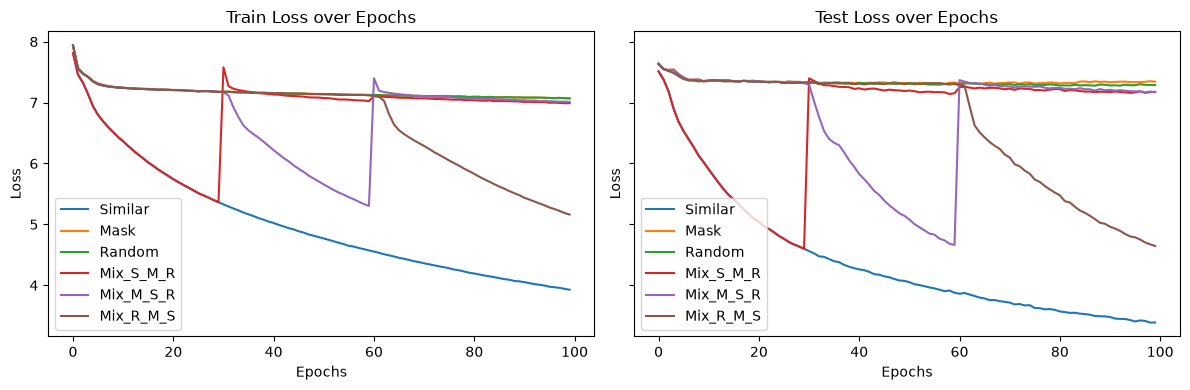

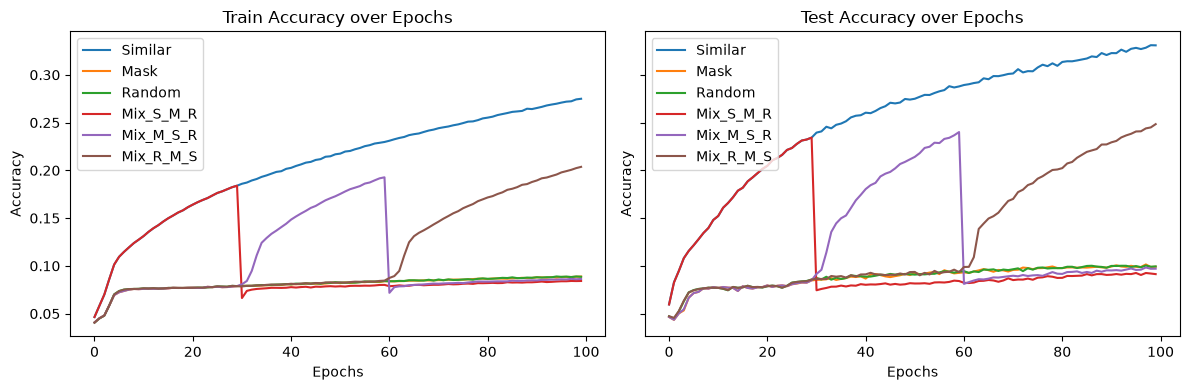

In [10]:
plot_train_test_metric(results_one_step, "loss", ylabel="Loss")
plot_train_test_metric(results_one_step, "acc", ylabel="Accuracy")

### Four step denoising training

In [11]:
results_4_steps = {
    "Similar":mean_train_results["similar_100"]["four_steps"],
    "Mask": mean_train_results["mask_100"]["four_steps"],
    "Random": mean_train_results["random_100"]["four_steps"],
    "Mix_S_M_R": mean_train_results["mix_30_30_40"]["four_steps"],
    "Mix_M_S_R": mean_train_results["mix_30m_30s_40r"]["four_steps"],
    "Mix_R_M_S": mean_train_results["mix_30r_30m_40s"]["four_steps"]
}

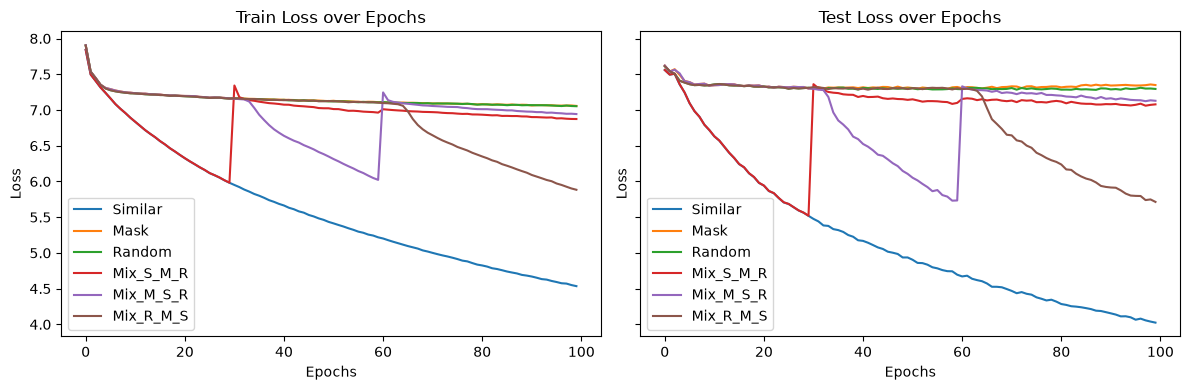

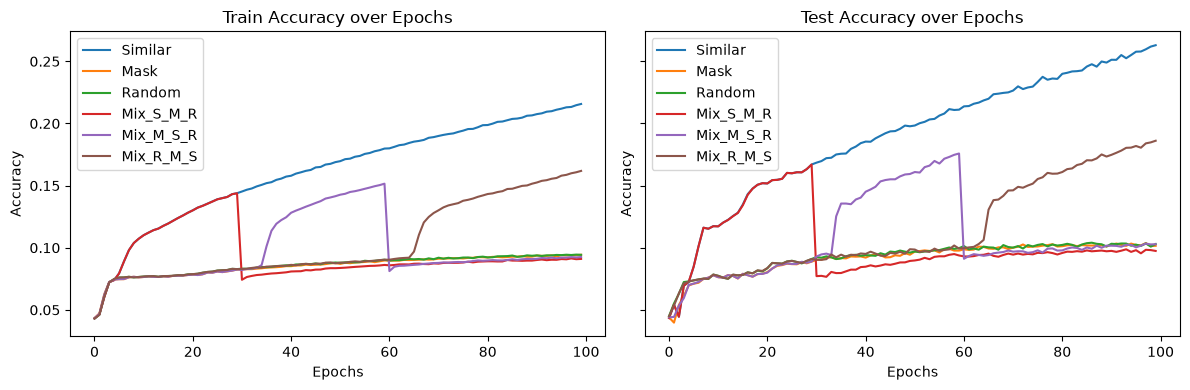

In [12]:
plot_train_test_metric(results_4_steps, "loss", ylabel="Loss")
plot_train_test_metric(results_4_steps, "acc", ylabel="Accuracy")

### One step vs four steps 

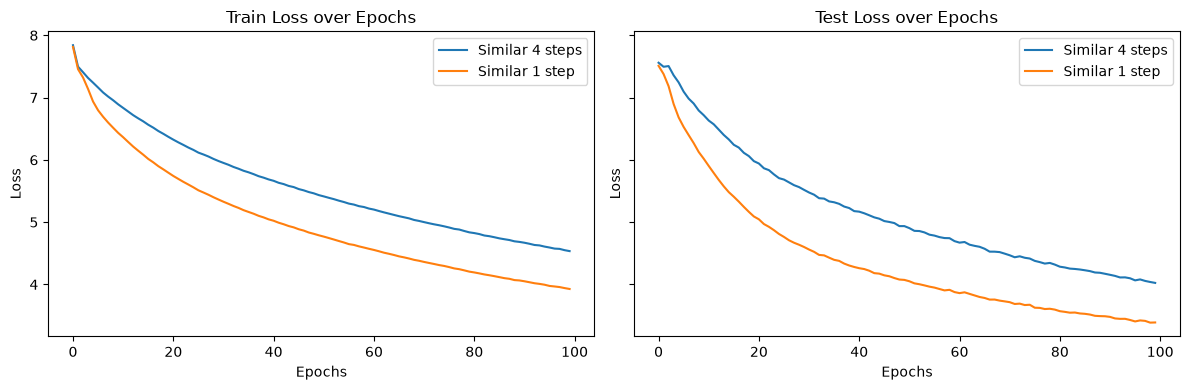

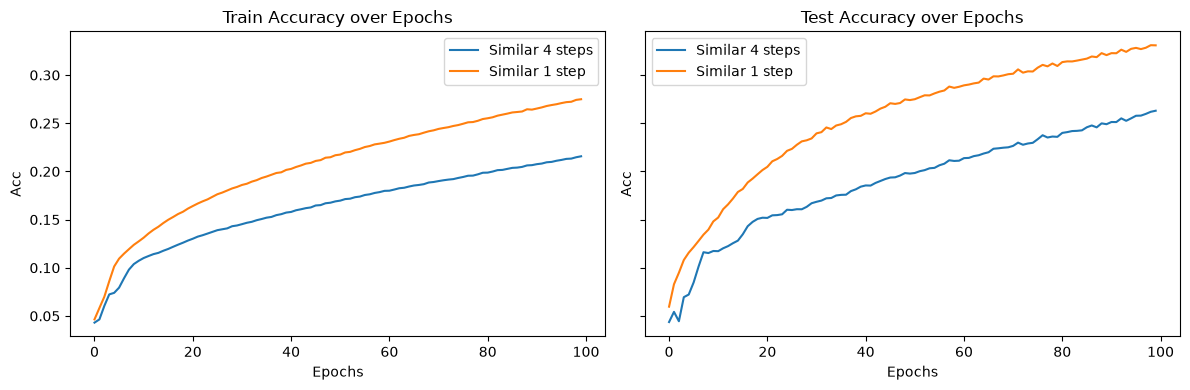

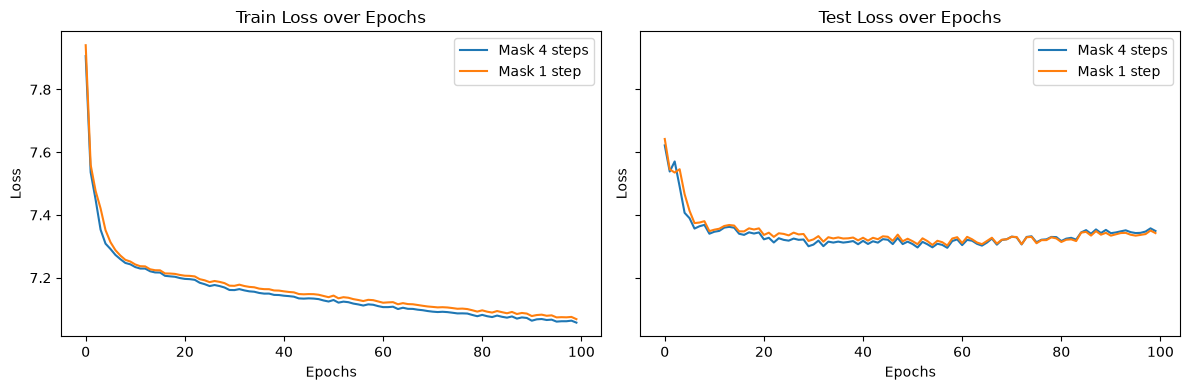

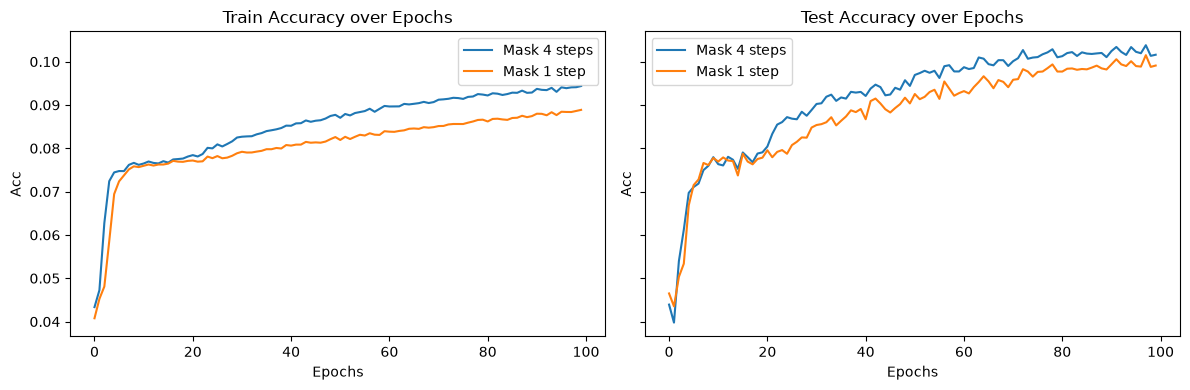

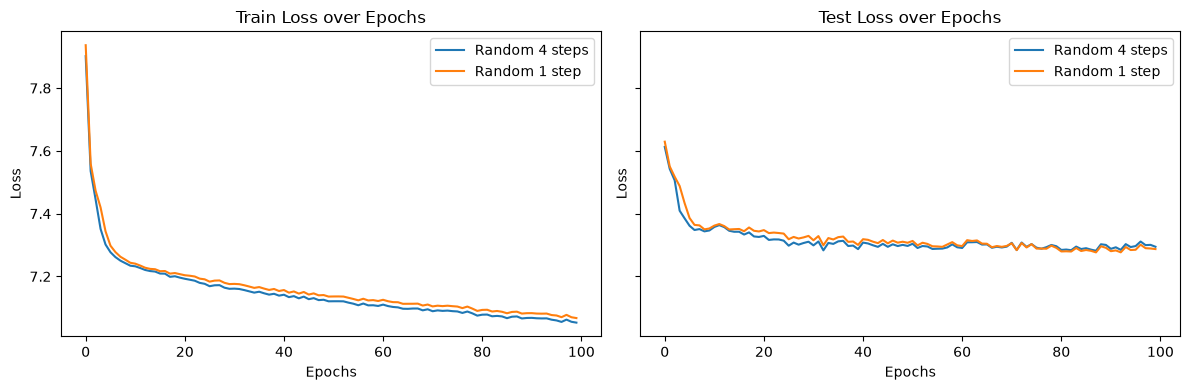

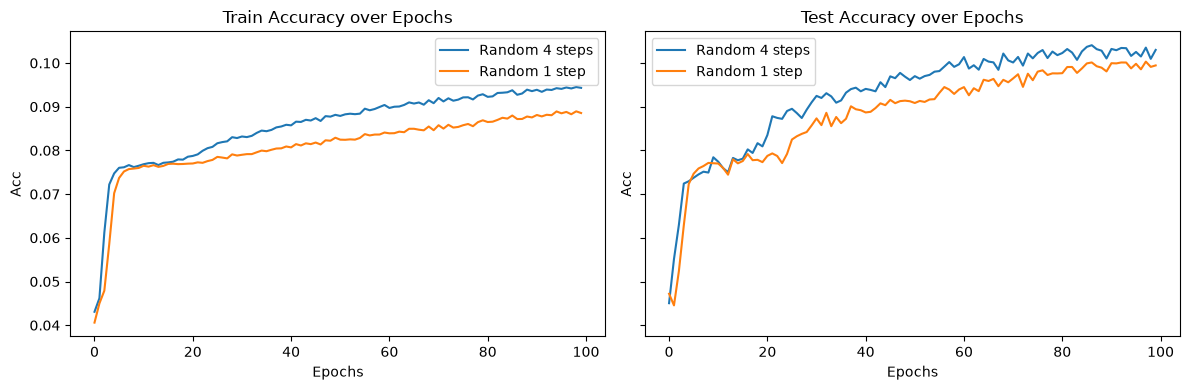

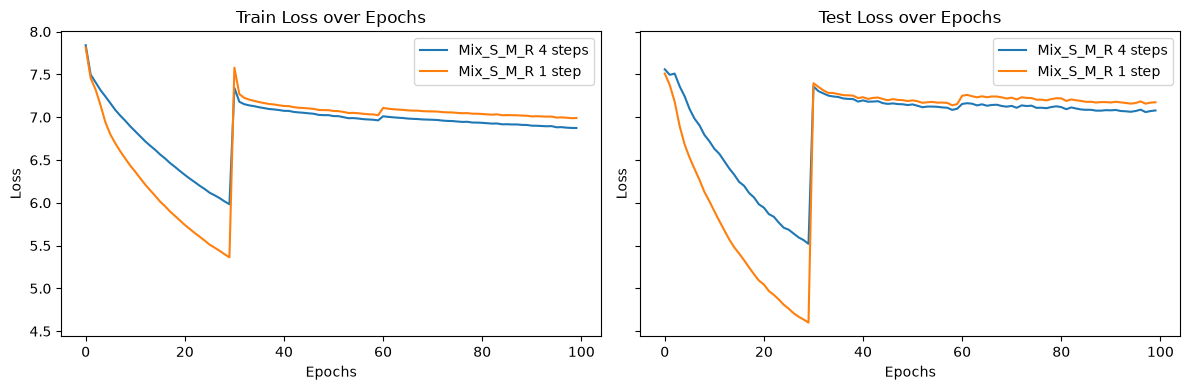

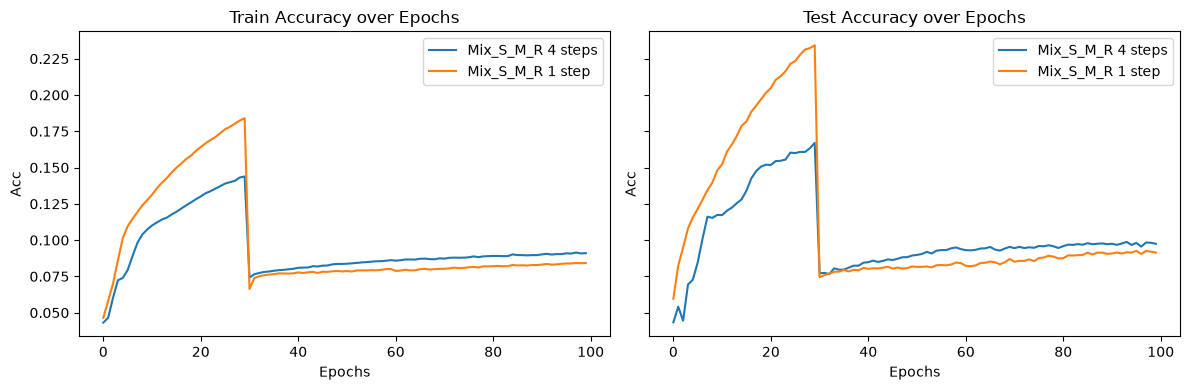

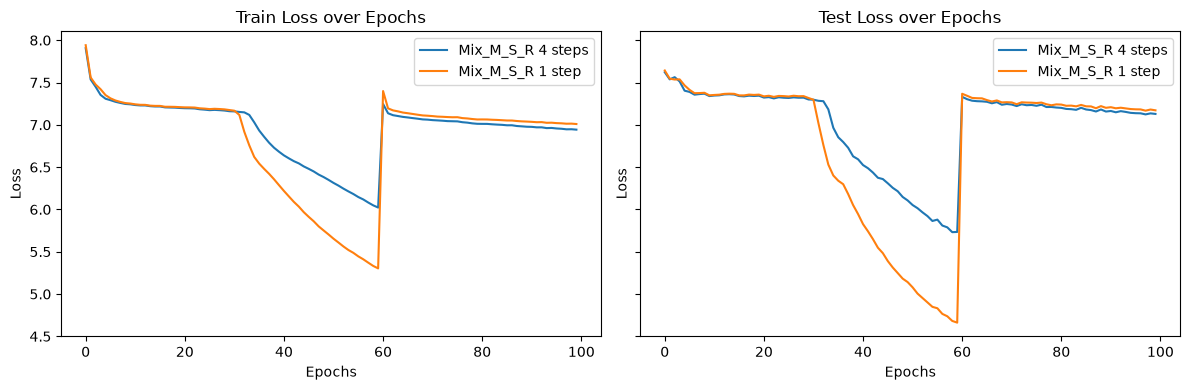

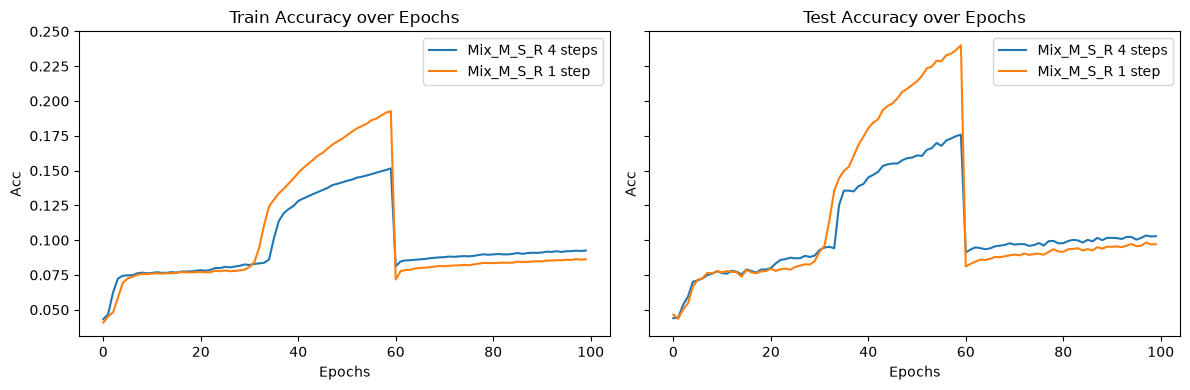

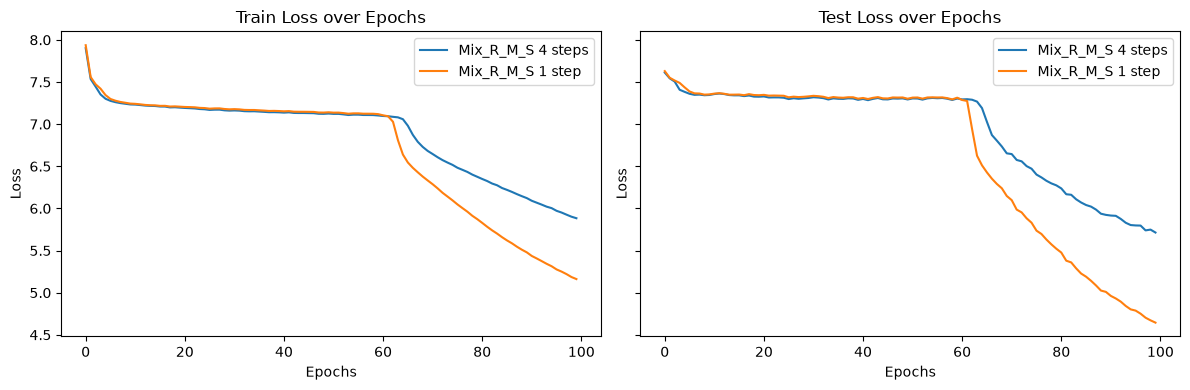

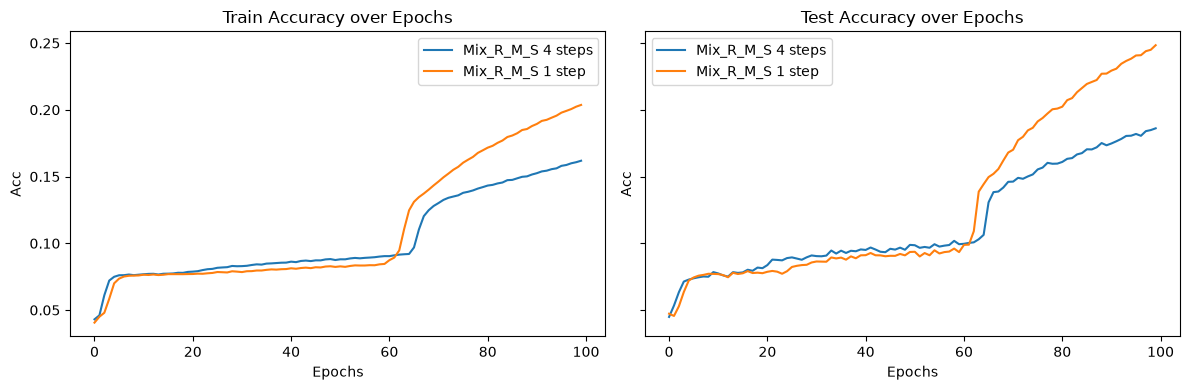

In [13]:
all_results = [
    {
        "Similar 4 steps": results_4_steps["Similar"],
        "Similar 1 step": results_one_step["Similar"]
    },
    {
        "Mask 4 steps": results_4_steps["Mask"],
        "Mask 1 step": results_one_step["Mask"]
    },
    {
        "Random 4 steps": results_4_steps["Random"],
        "Random 1 step": results_one_step["Random"]
    },
    {
        "Mix_S_M_R 4 steps": results_4_steps["Mix_S_M_R"],
        "Mix_S_M_R 1 step": results_one_step["Mix_S_M_R"]
    },
    {
        "Mix_M_S_R 4 steps": results_4_steps["Mix_M_S_R"],
        "Mix_M_S_R 1 step": results_one_step["Mix_M_S_R"]
    },
    {
        "Mix_R_M_S 4 steps": results_4_steps["Mix_R_M_S"],
        "Mix_R_M_S 1 step": results_one_step["Mix_R_M_S"]
    }
]
metrics = ["loss", "acc"]
for result in all_results:
    for metric in metrics:
        plot_train_test_metric(result, metric, ylabel=metric.capitalize())


## Evaluation results

### Create the full dataset

In [14]:
MODEL_NAME_MAP = {
    'similar_100': 'similar',
    'mask_100': 'mask', 
    'random_100': 'random',
    'mix_30_30_40': 'mix_s_m_r_t',
    'similar_100_4_steps': 'similar_4',
    'mask_100_4_steps': 'mask_4',
    'random_100_4_steps': 'random_4',
    'mix_30_30_40_4_steps': 'mix_s_m_r_4_t',
    'mix_30m_30s_40r': 'mix_m_s_r',
    'mix_30r_30m_40s': 'mix_r_m_s',
    'mix_30m_30s_40r_4_steps': 'mix_m_s_r_4',
    'mix_30r_30m_40s_4_steps': 'mix_r_m_s_4',
}

denoising_lvls = ['1', '2', '4', '8', '16', '32', '64', '100']


df_eval = None

for denoising_step in denoising_lvls:
    for seed in seeds:
        for step in ['one', 'four']:
            df = pd.read_json(
                f'../eval/new/seed_{seed}/denoising_{denoising_step}/{step}_step_training/evaluation_results.json'
            )
            df_eval = pd.concat([df_eval, df], ignore_index=True) if df_eval is not None else df

df_eval['denoising_gain'] = df_eval['accuracy_denoising'] - df_eval['accuracy']
df_eval.model = df_eval.model.map(MODEL_NAME_MAP)

### Compare models on the 50-step denoising evaluation


In [15]:
def compare_models_by_method(df, corruption_method, corruption_rate, denoise_iterations, metrics=('loss', 'accuracy', 'accuracy_denoising')):
    selected = df[
        (df['corruption_method'] == corruption_method)
        & (df['corruption_rate'] == corruption_rate)
        & (df['denoise_iterations'] == denoise_iterations)
    ]
    per_seed = selected.groupby(['model', 'seed'])[list(metrics)].mean()
    summary = per_seed.groupby('model').agg(['mean', 'std'])
    ncols = 2
    nrows = (len(metrics) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(18, 6 * nrows),
        squeeze=False,
    )
    fig.suptitle(
        f'Comparison by {corruption_method.capitalize()} corruption '
        f'(rate: {corruption_rate:.0%}, denoise: {denoise_iterations})',
        fontsize=16,
    )

    for i, metric in enumerate(metrics):
        metric_summary = summary[metric].sort_values('mean', ascending=False)
        ax = axes[i // ncols, i % ncols]
        ax.barh(
            metric_summary.index, metric_summary['mean'],
            xerr=metric_summary['std'].fillna(0),
            height=0.85, capsize=4,
        )
        ax.invert_yaxis()
        ax.set_title(metric.replace('_', ' ').capitalize())
        ax.set_xlabel(f"{metric.replace('_', ' ').capitalize()} (mean ± std across seeds)")
        ax.tick_params(axis='y', labelsize=9)

    for i in range(len(metrics), nrows * ncols):
        axes[i // ncols, i % ncols].set_visible(False)

    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


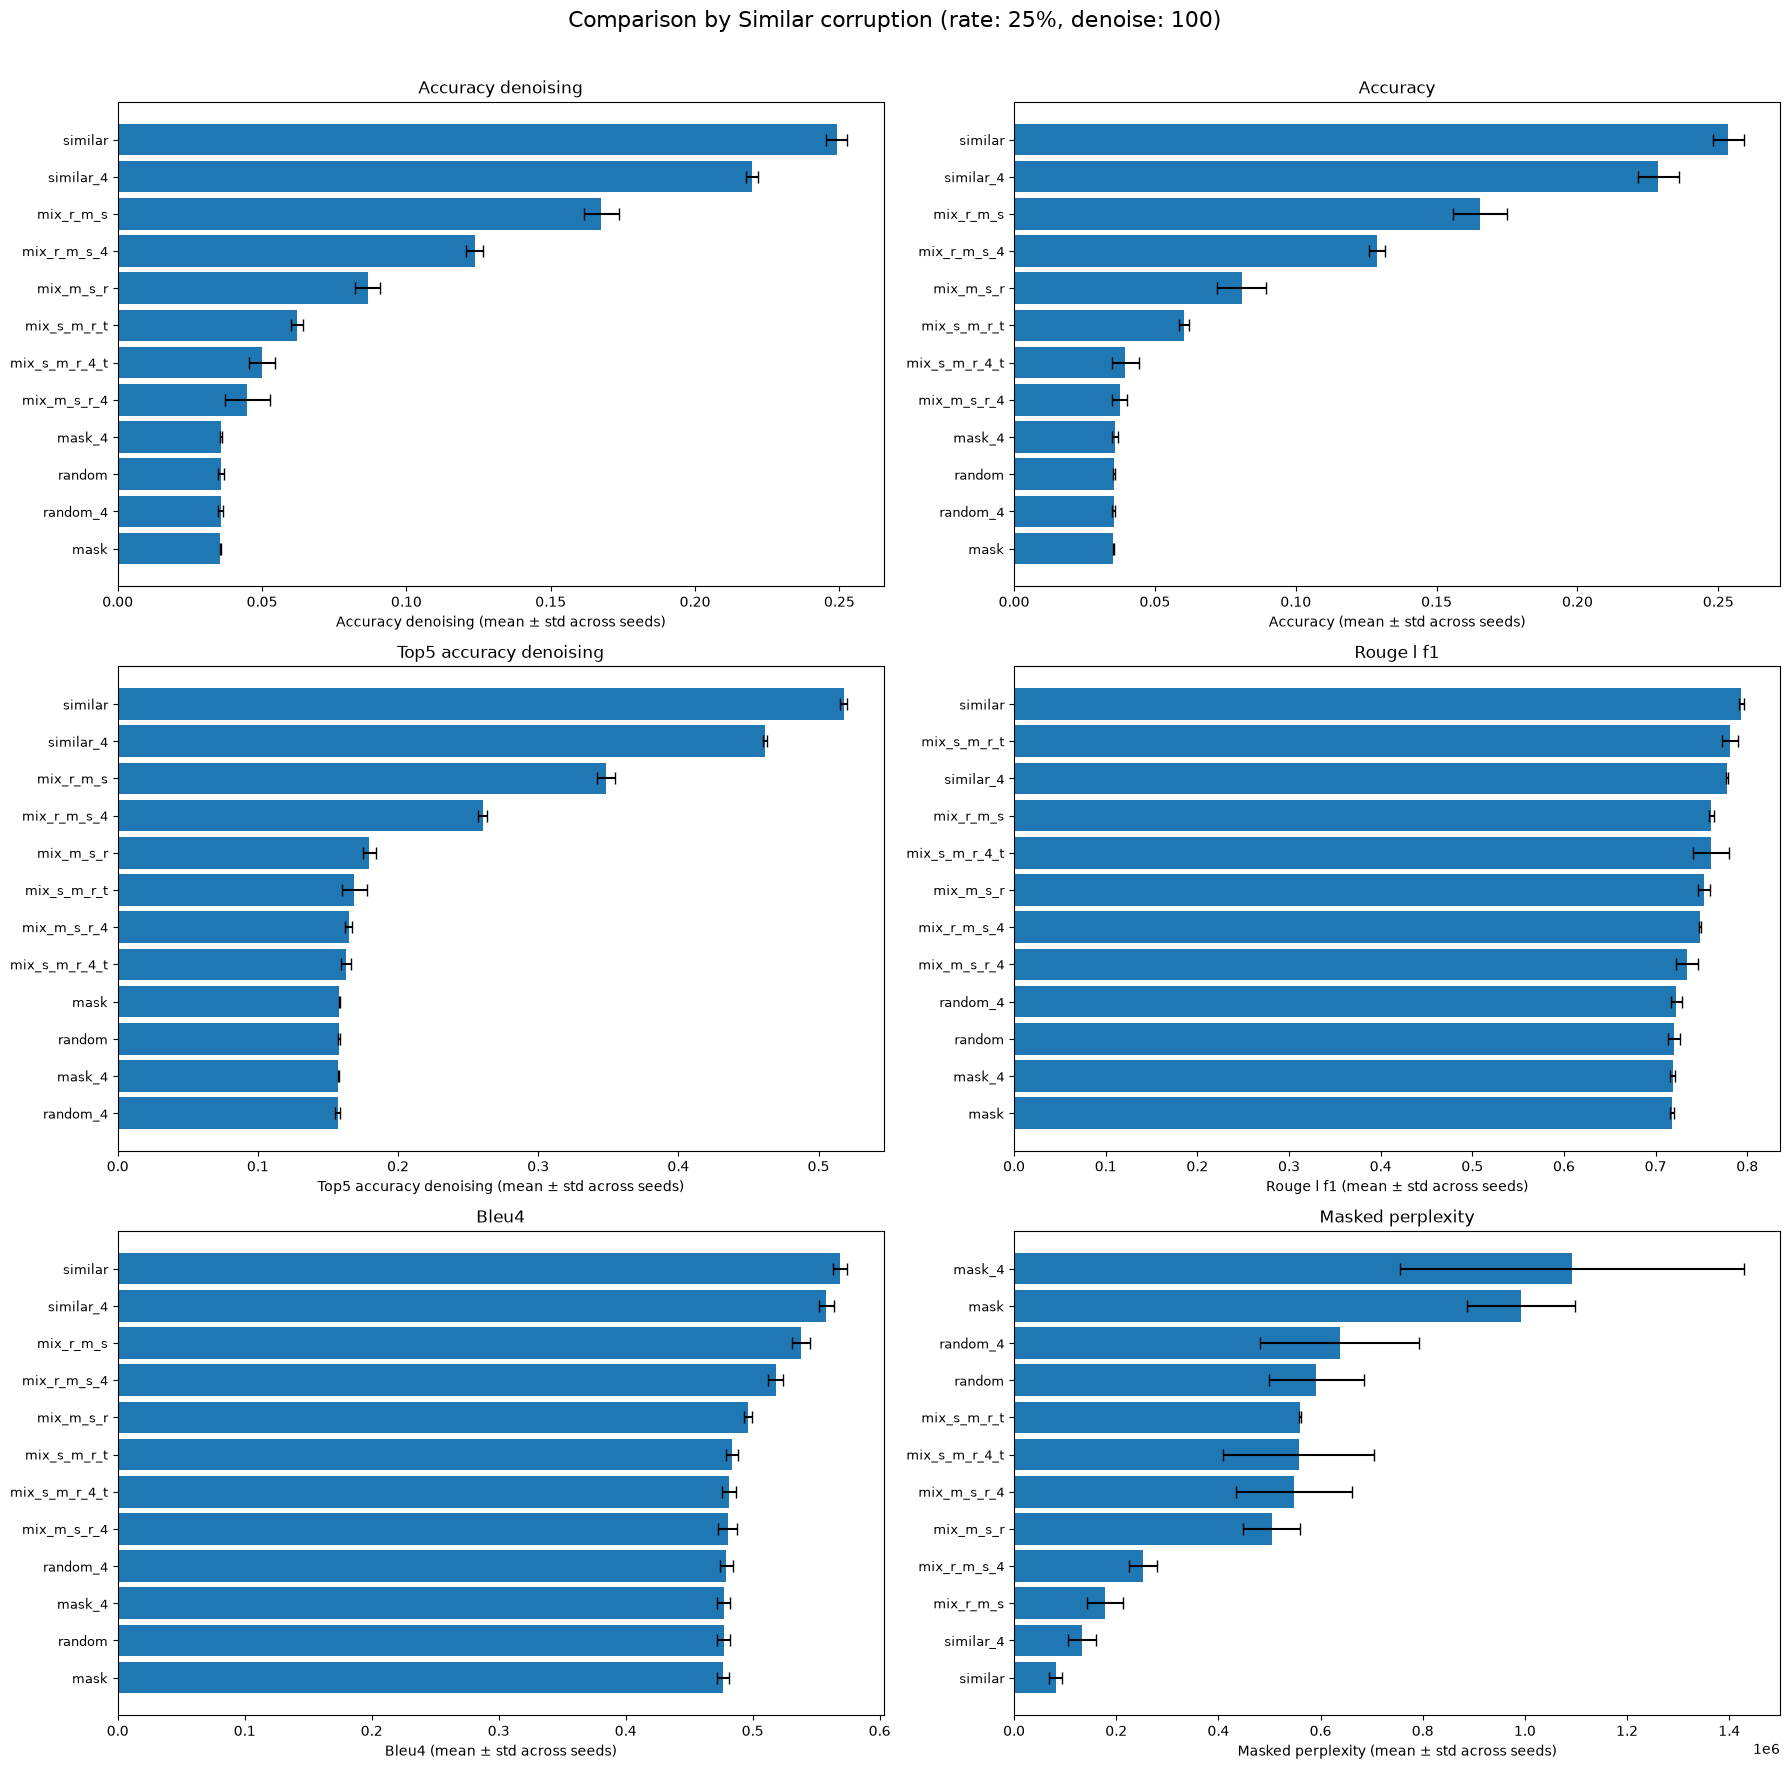

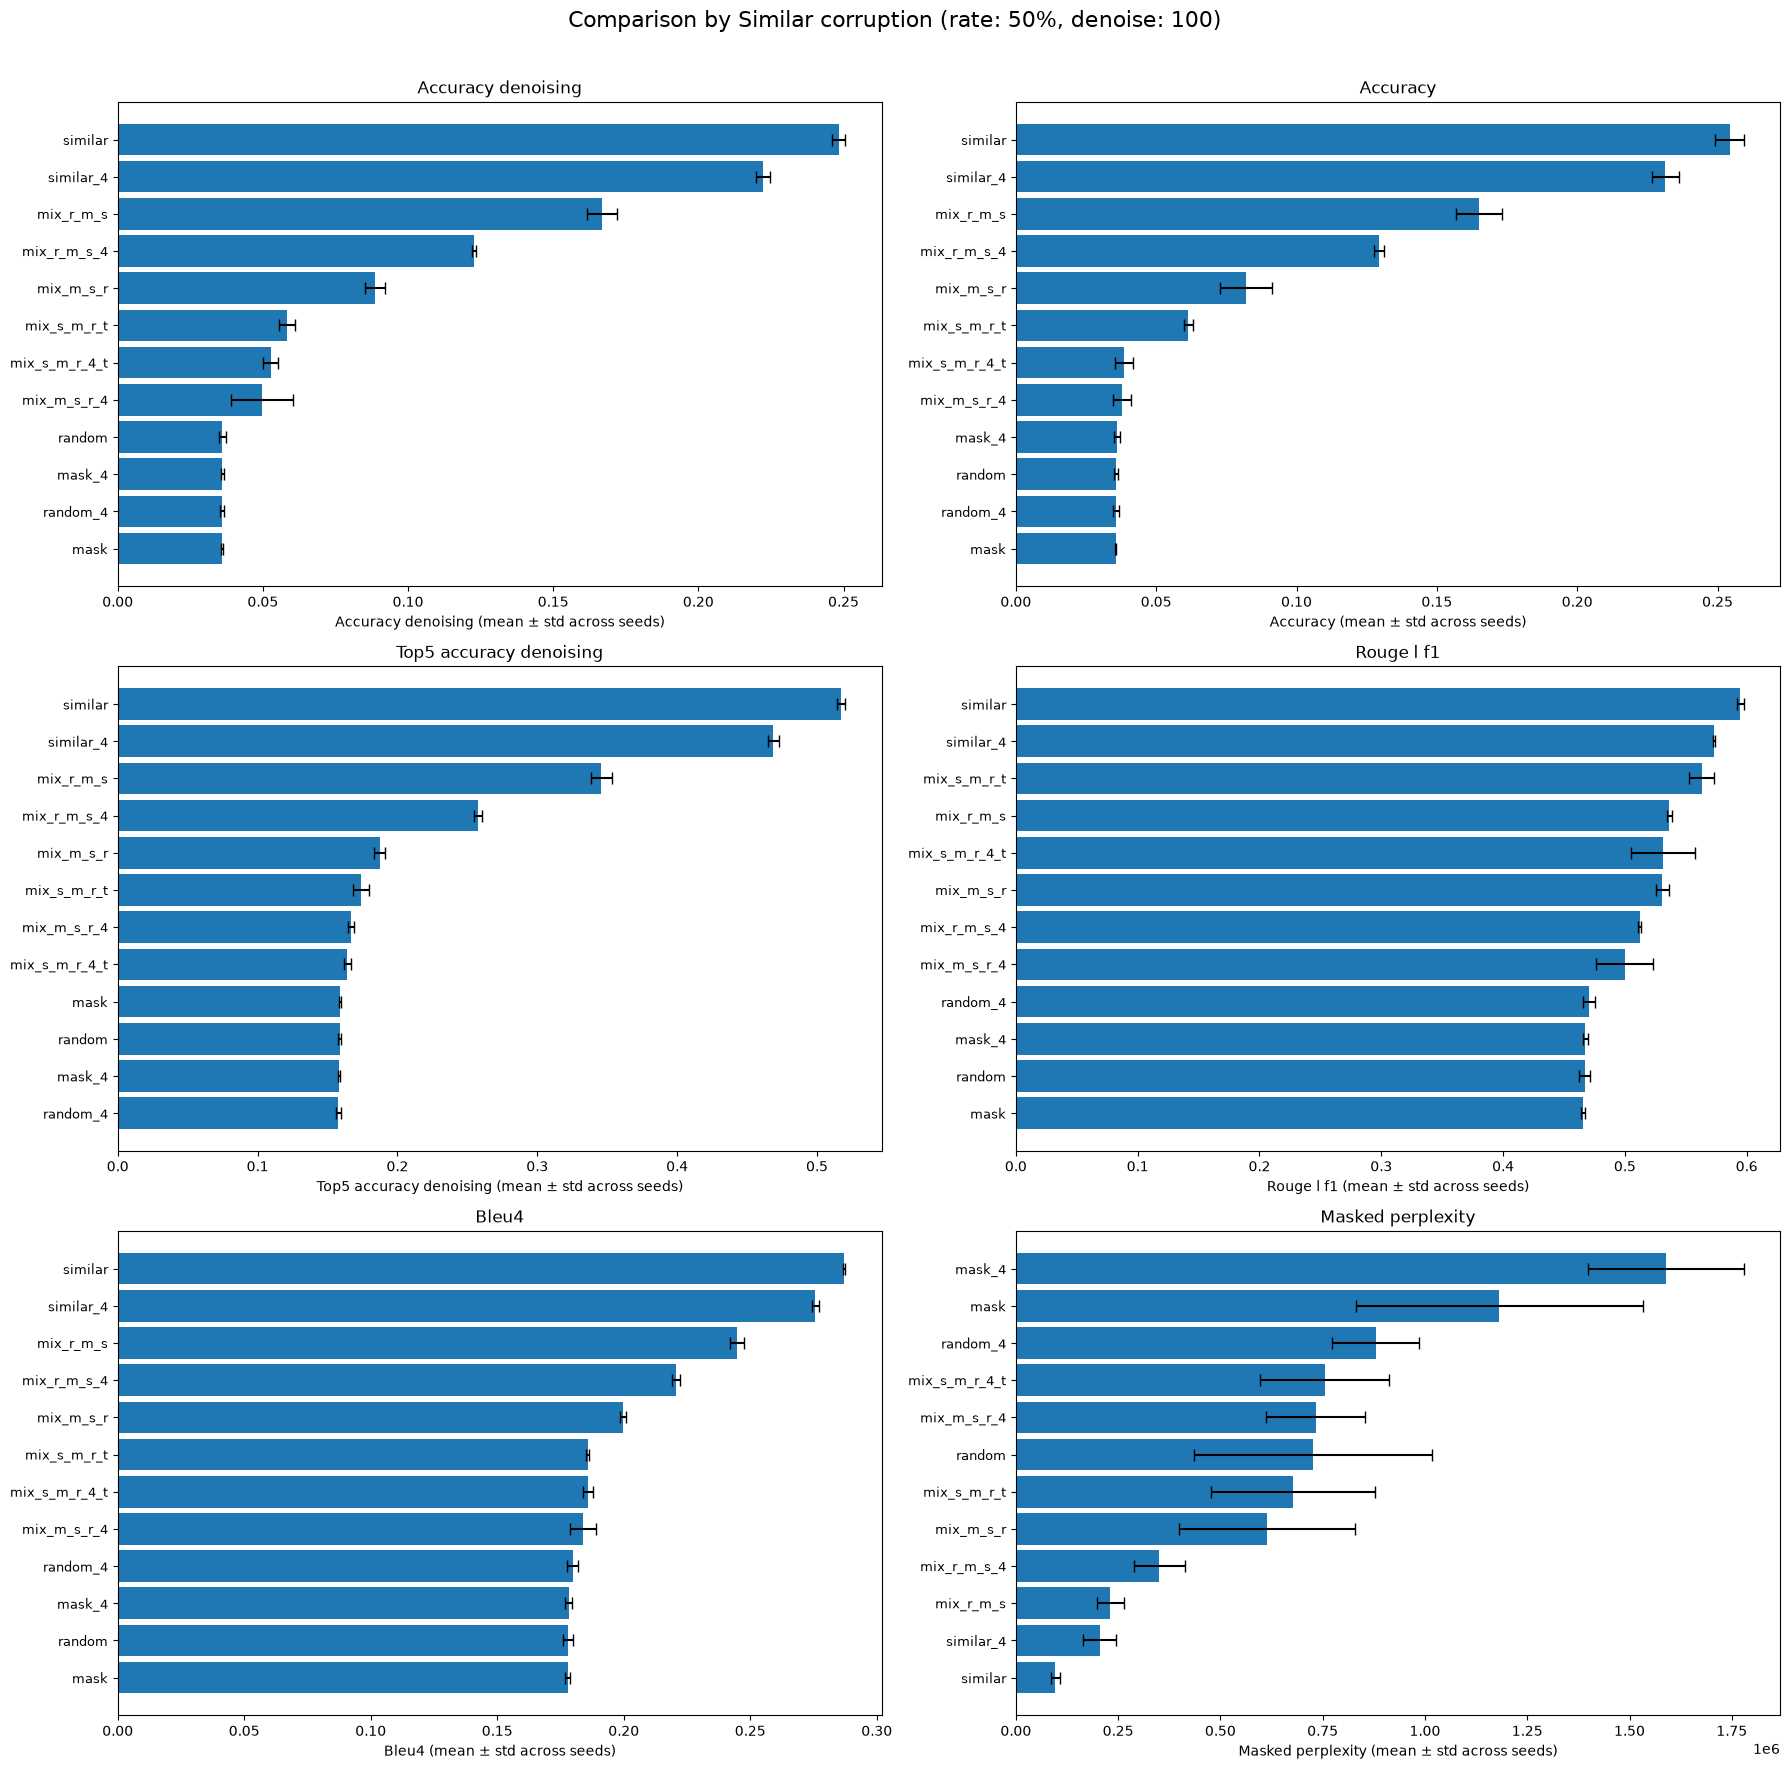

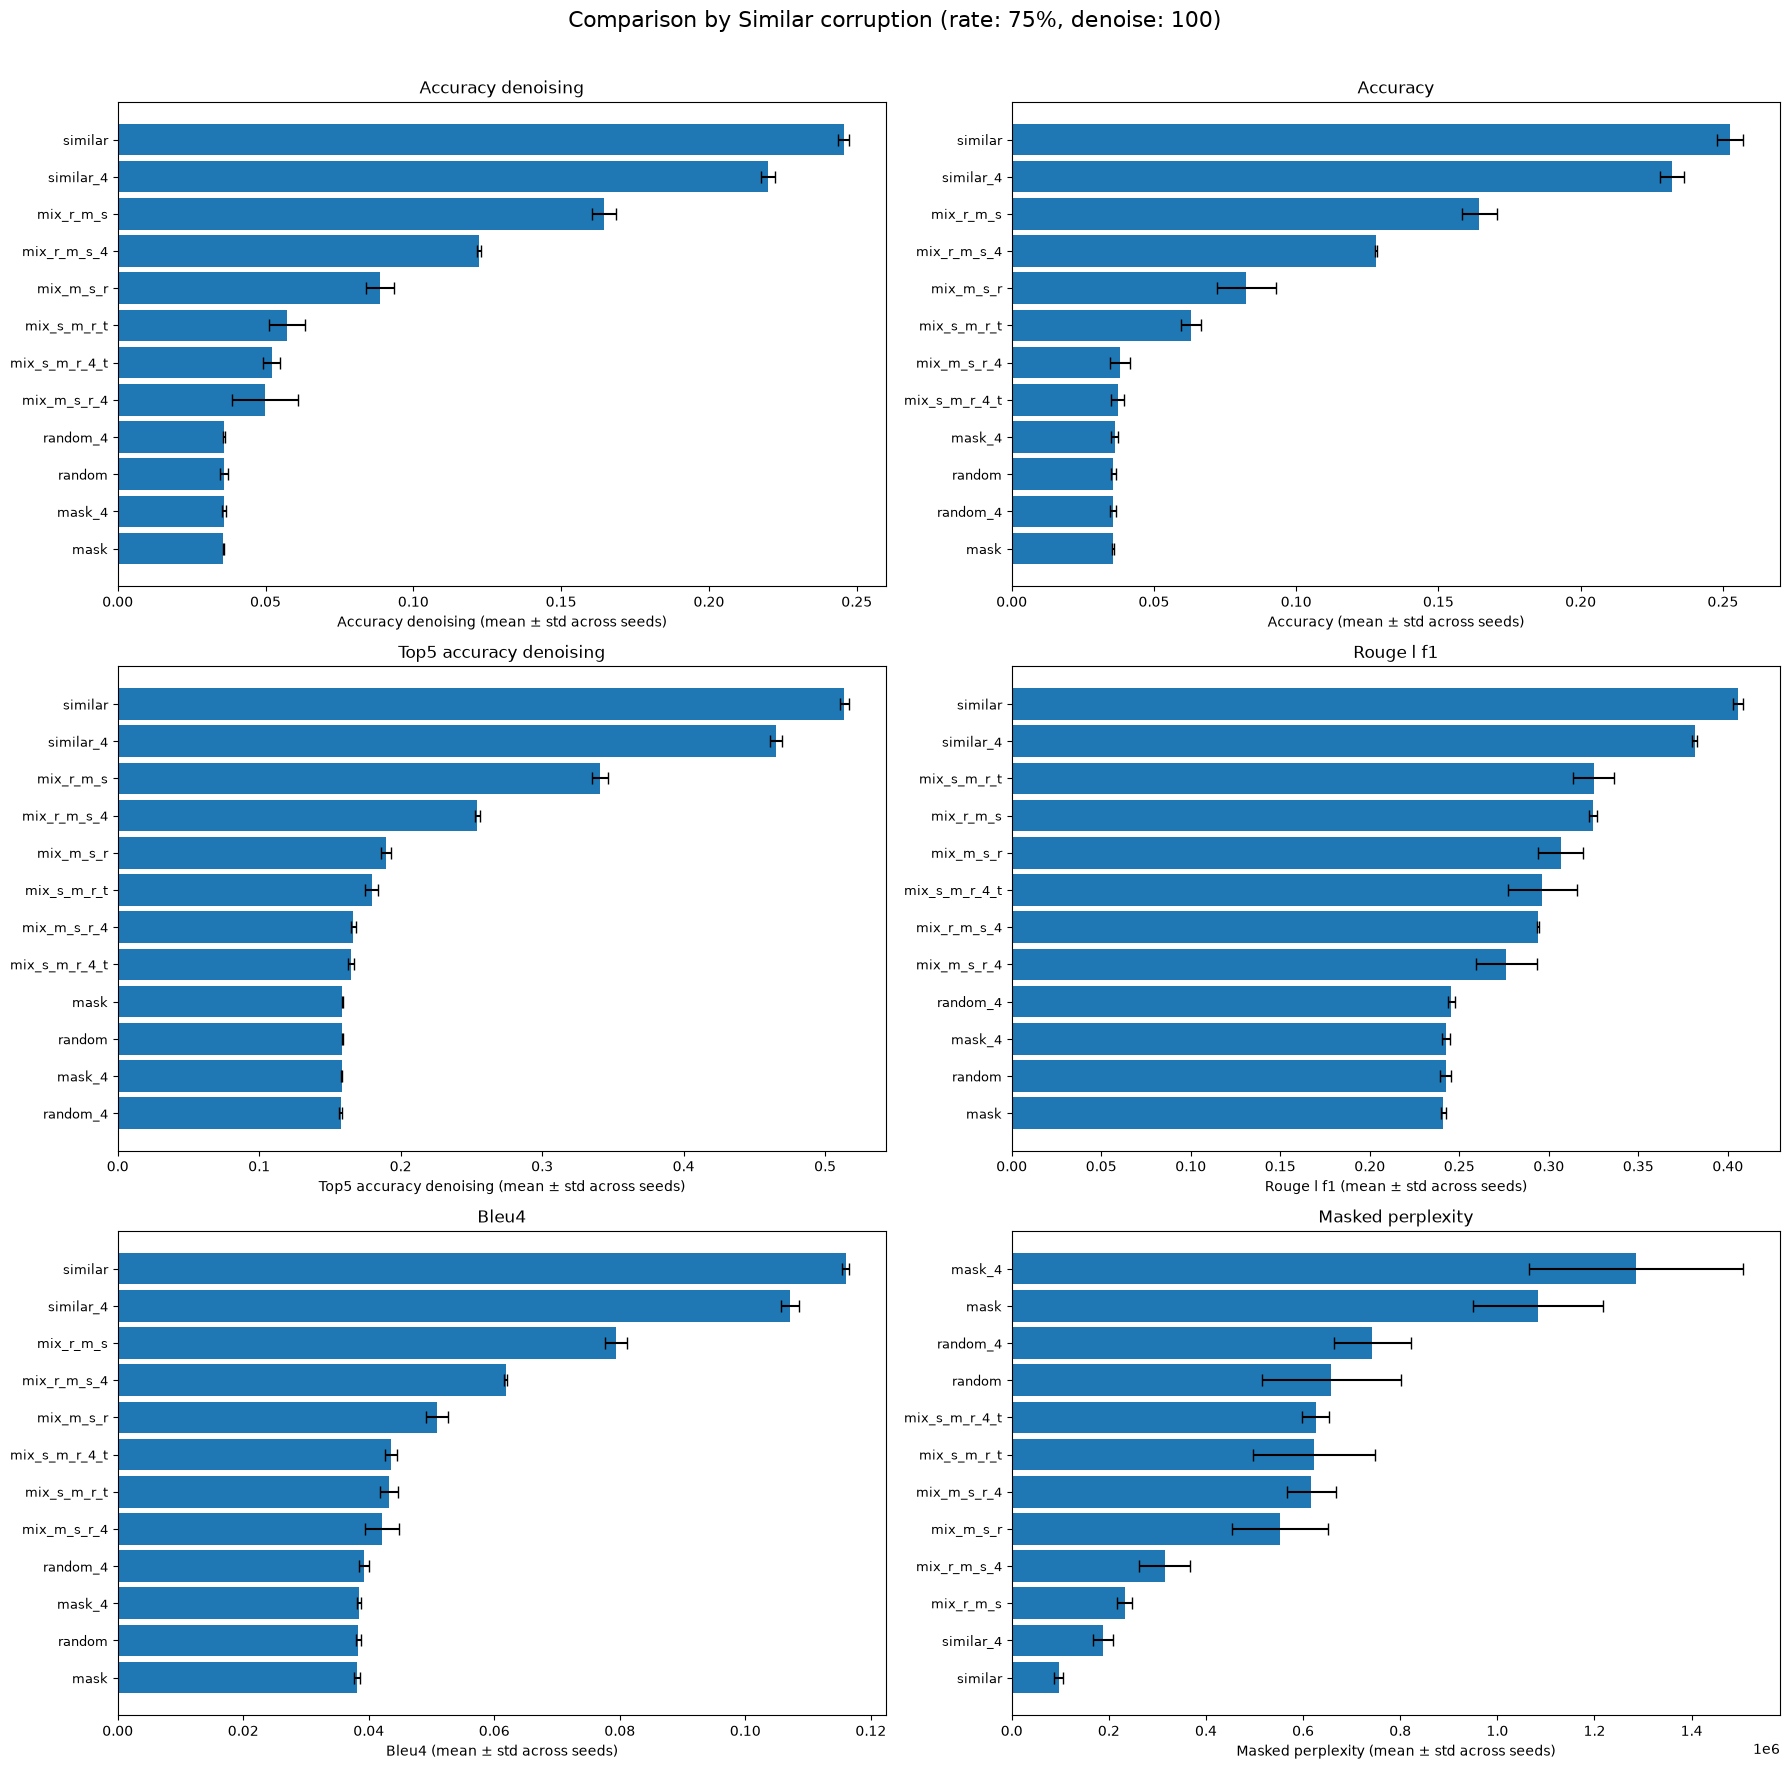

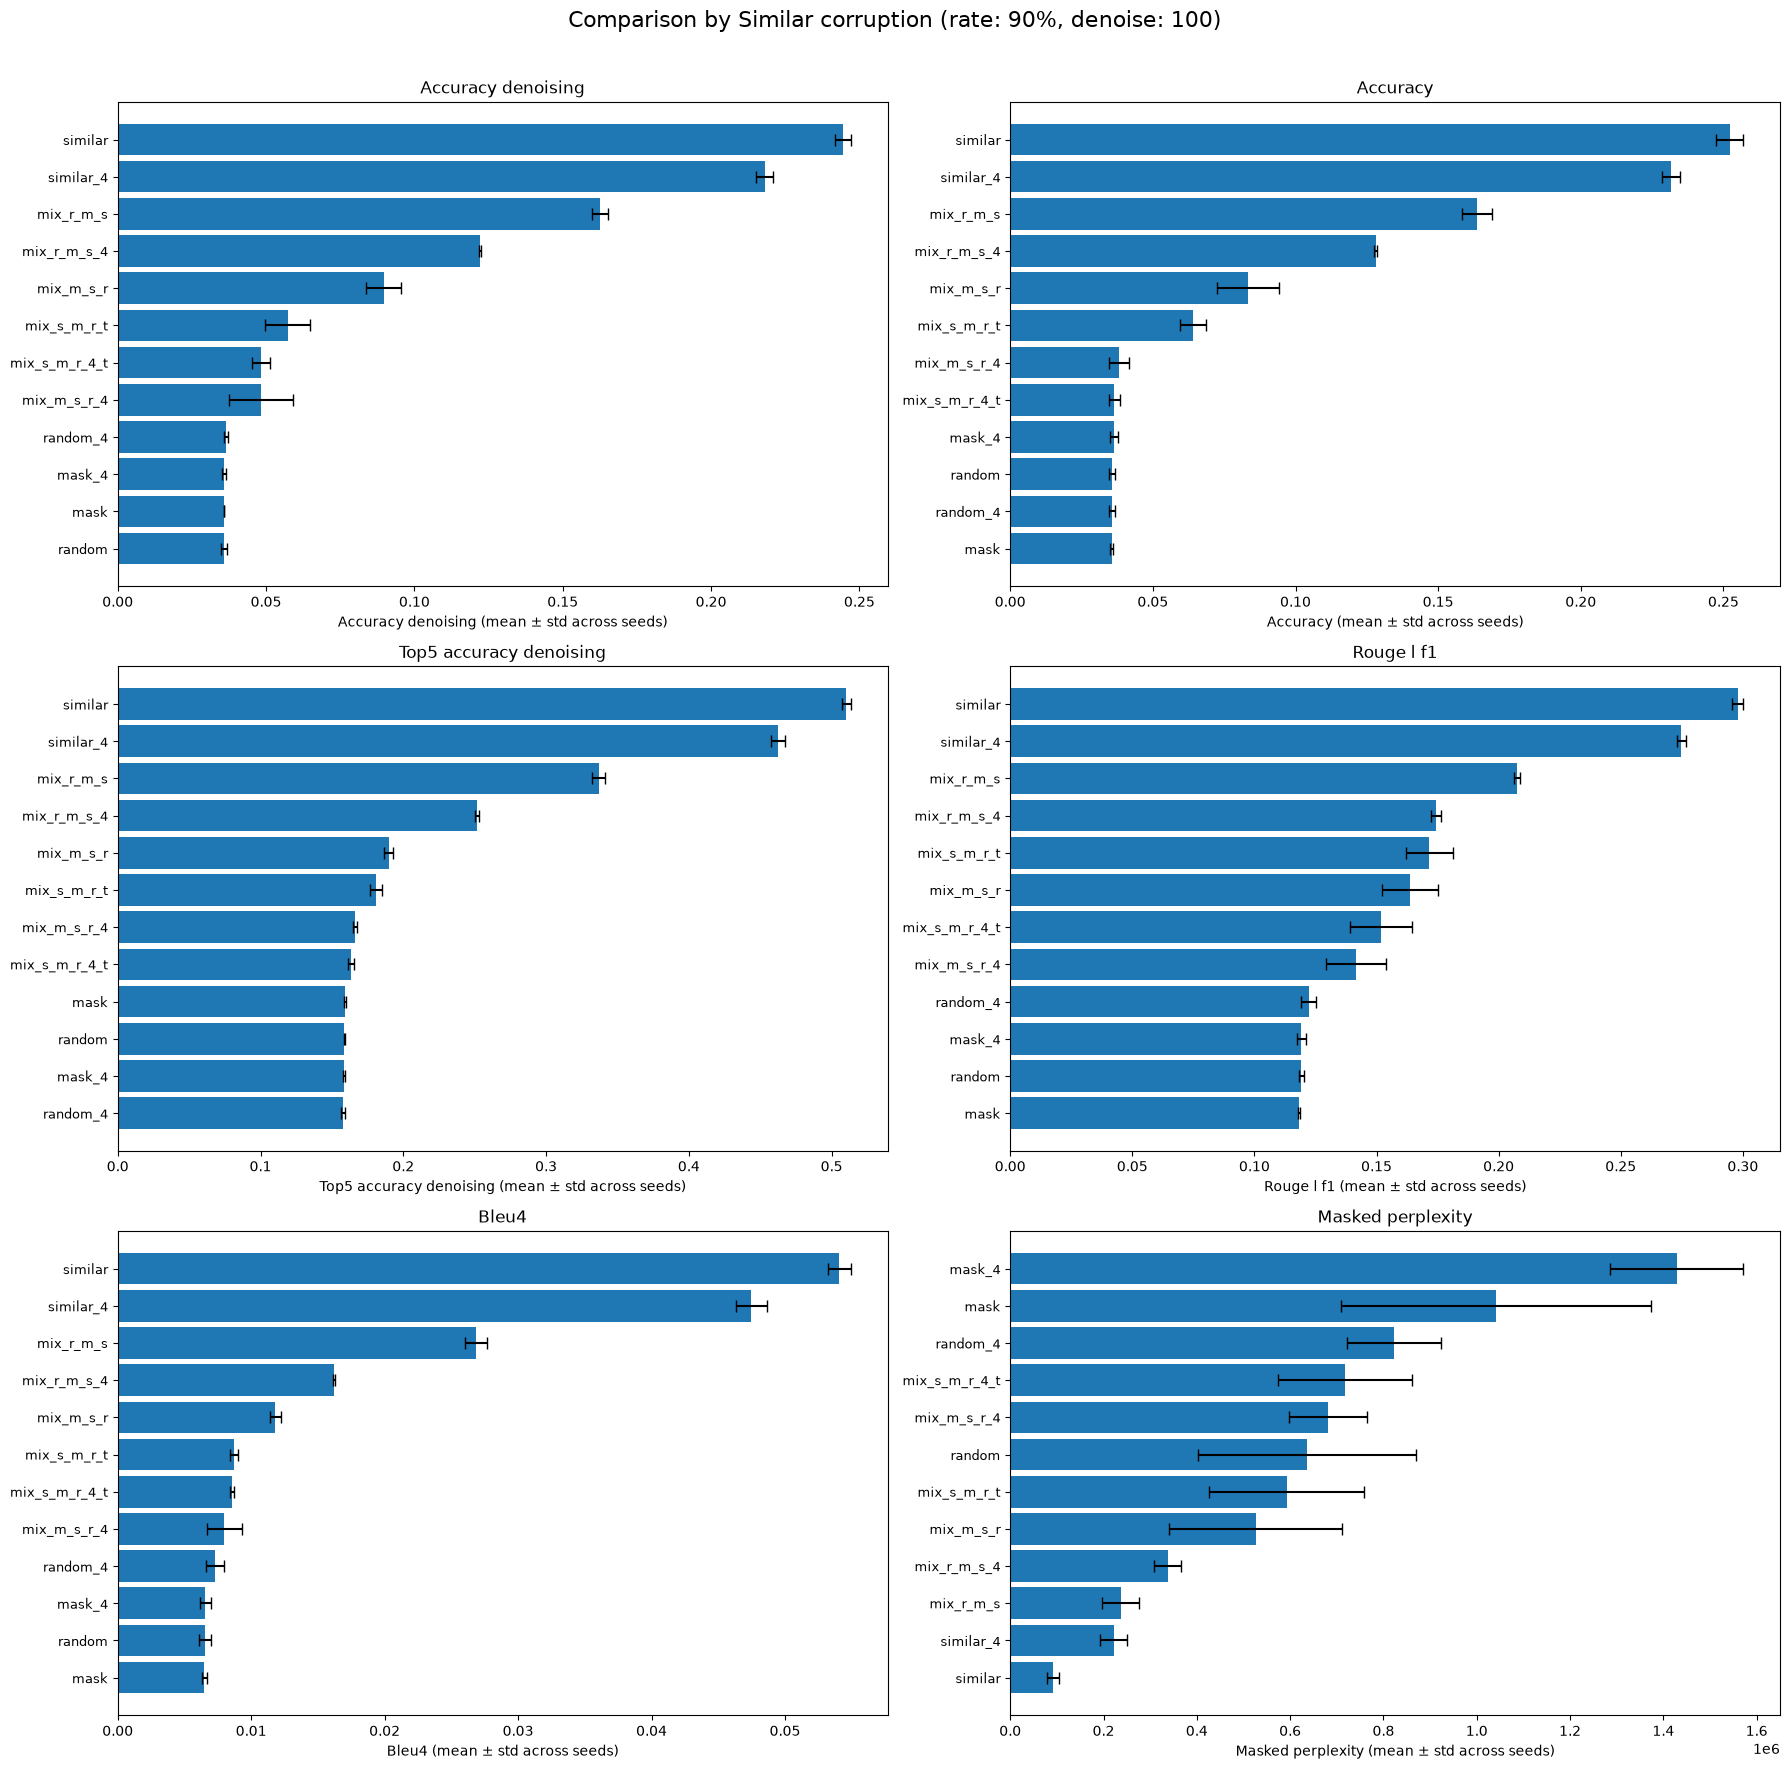

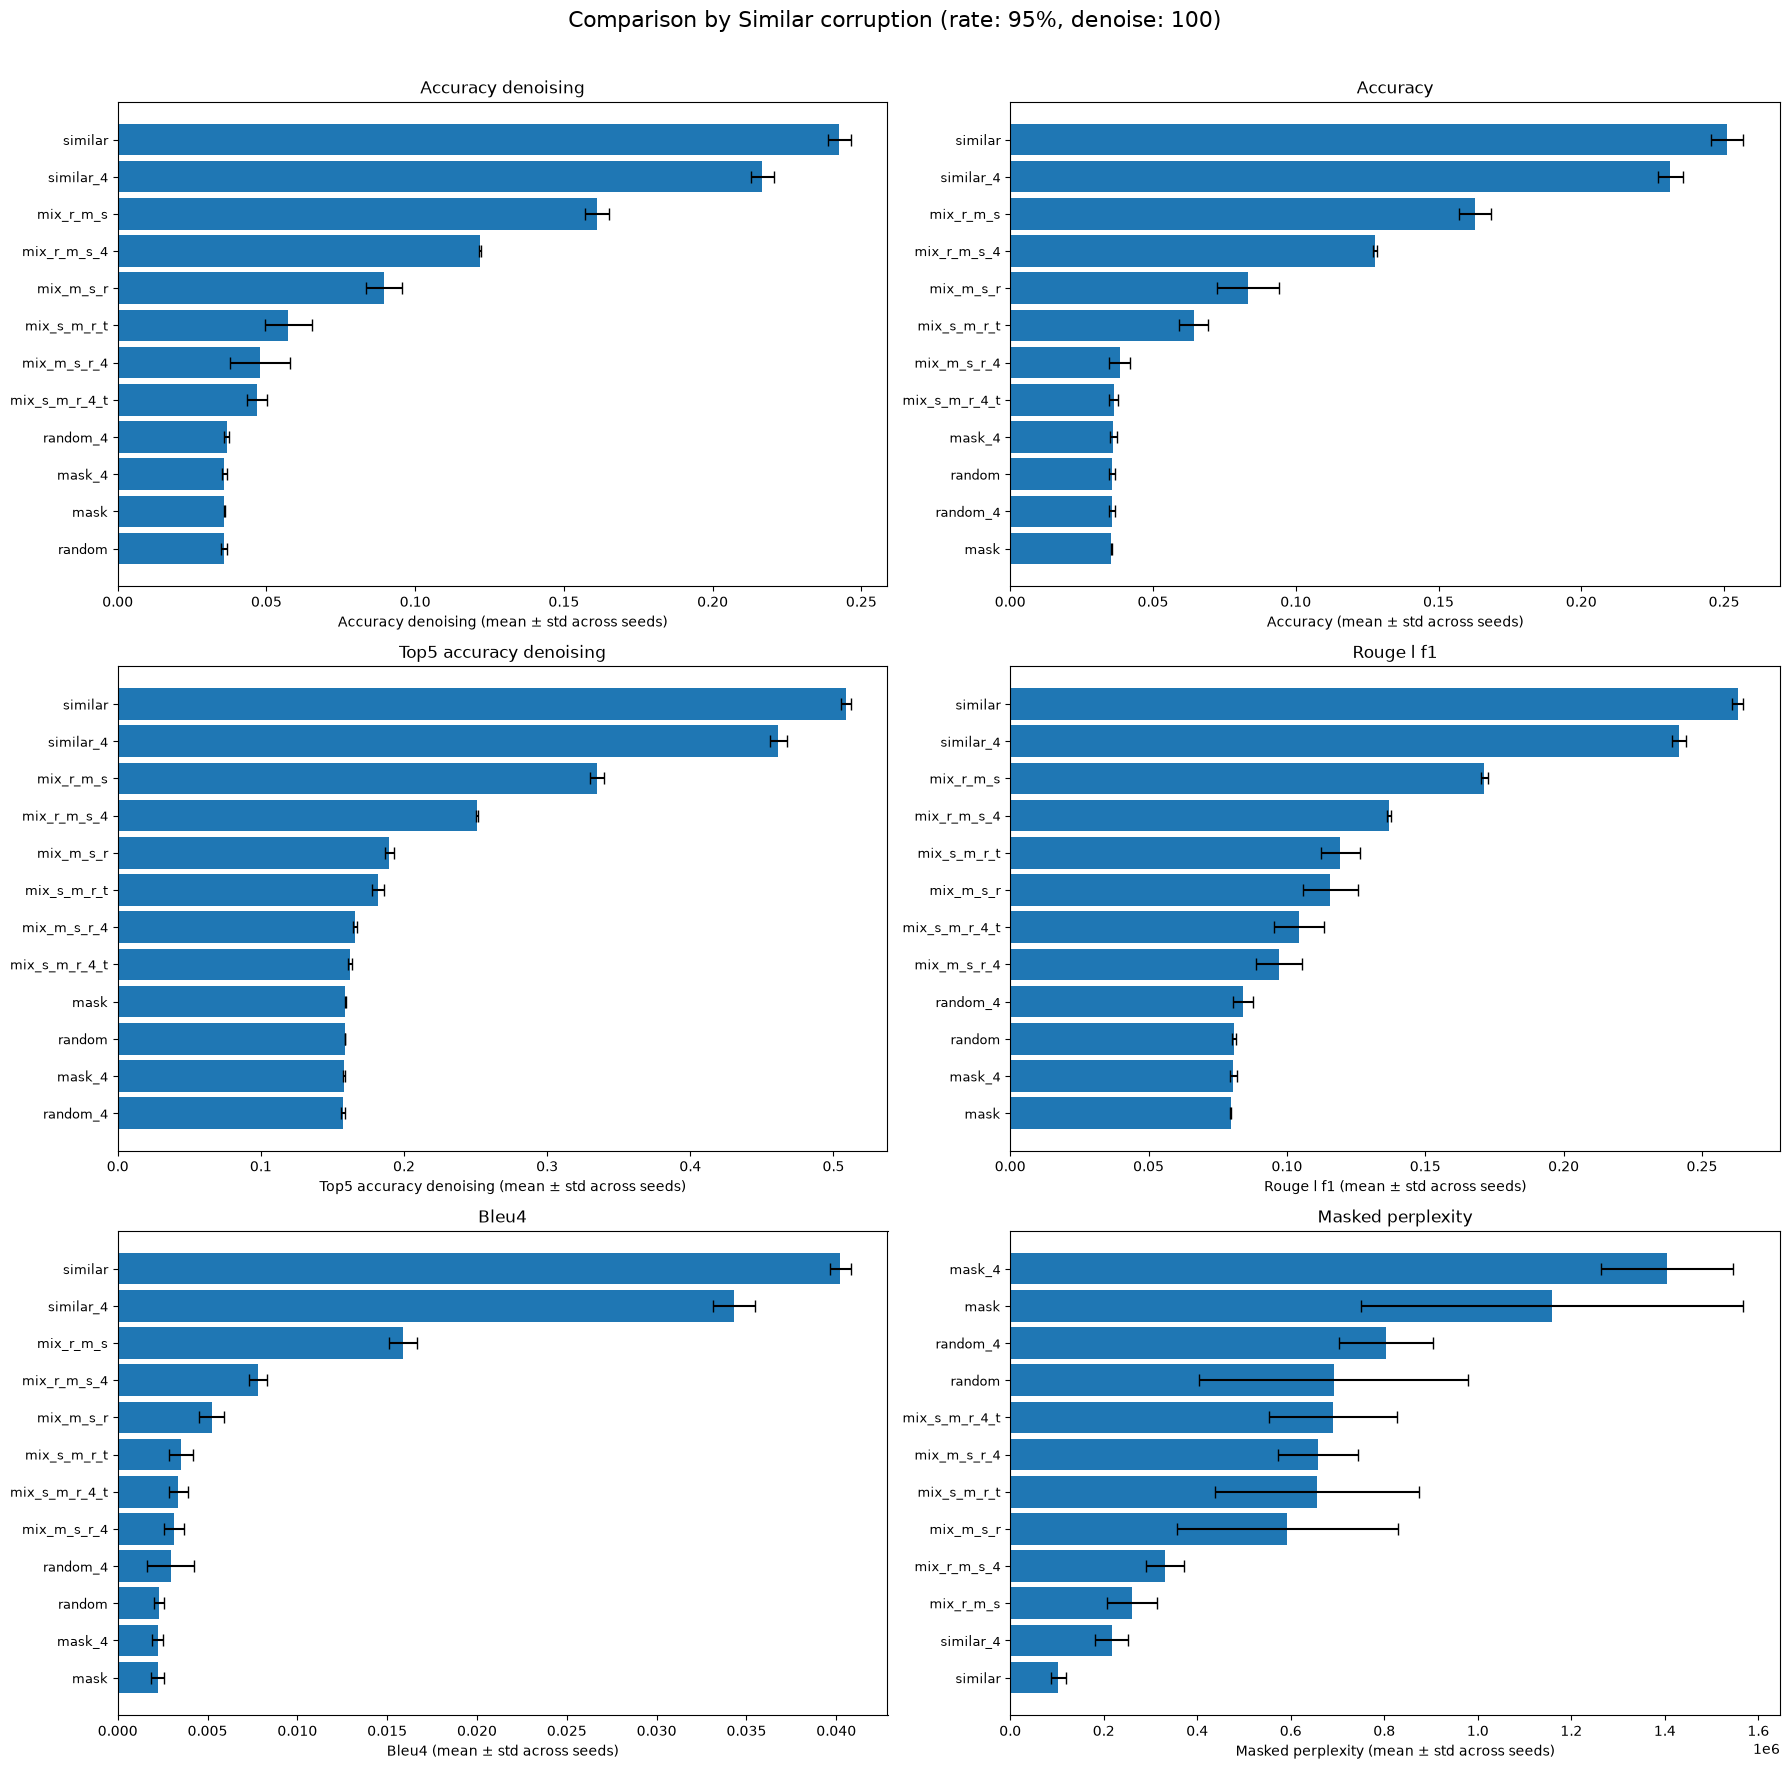

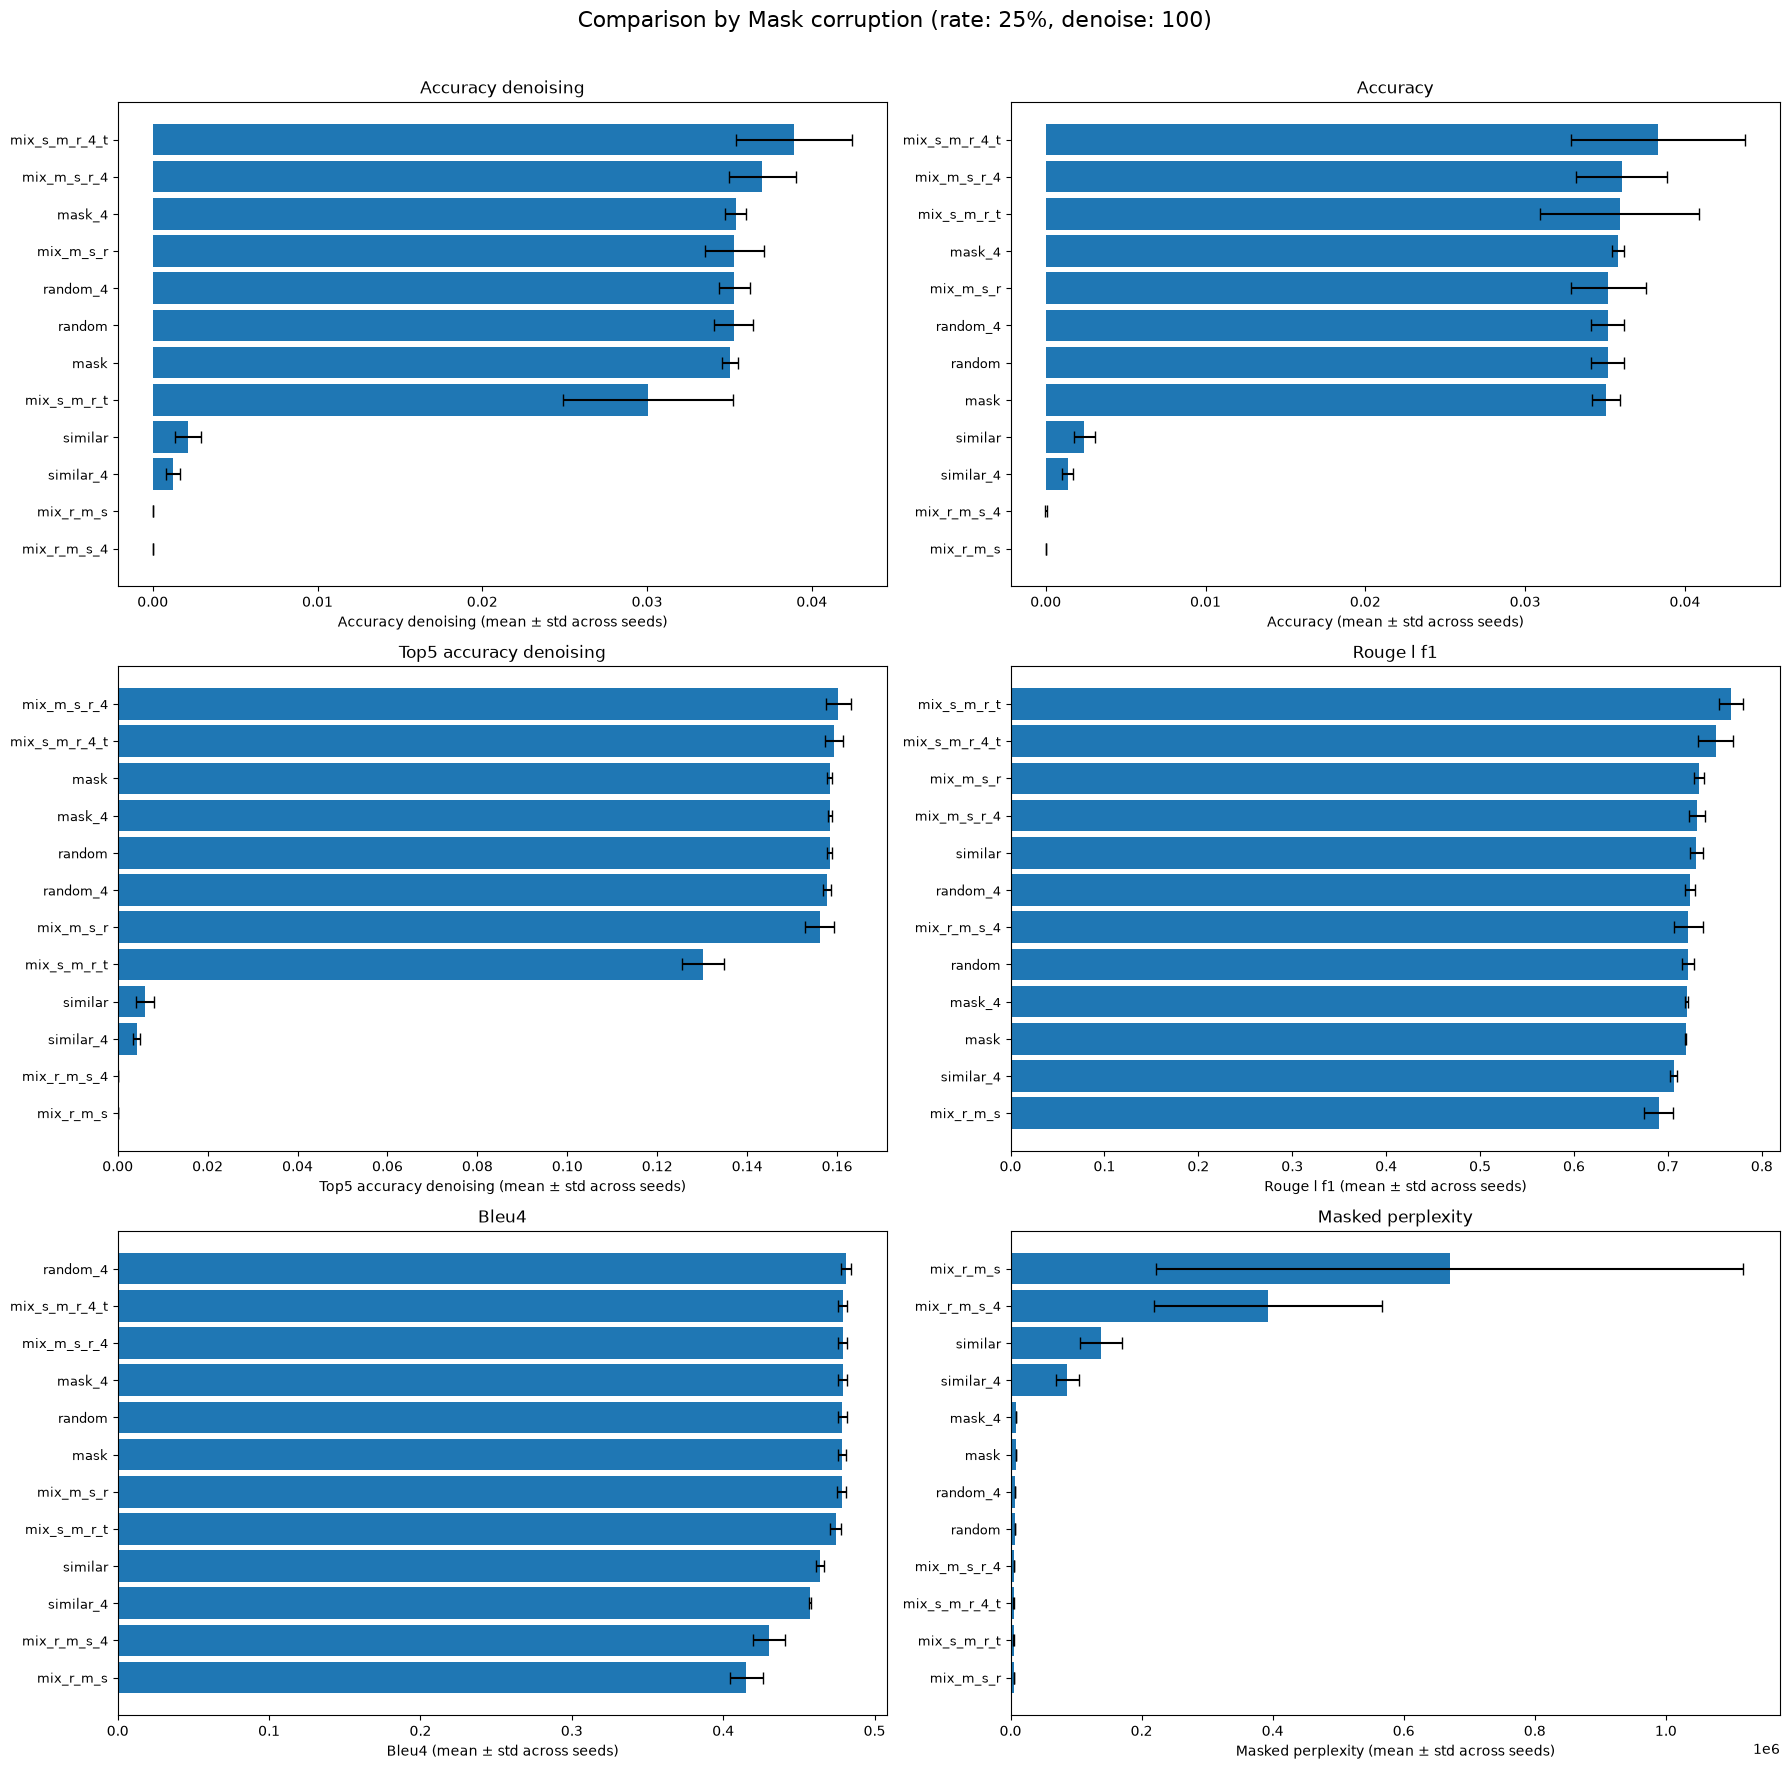

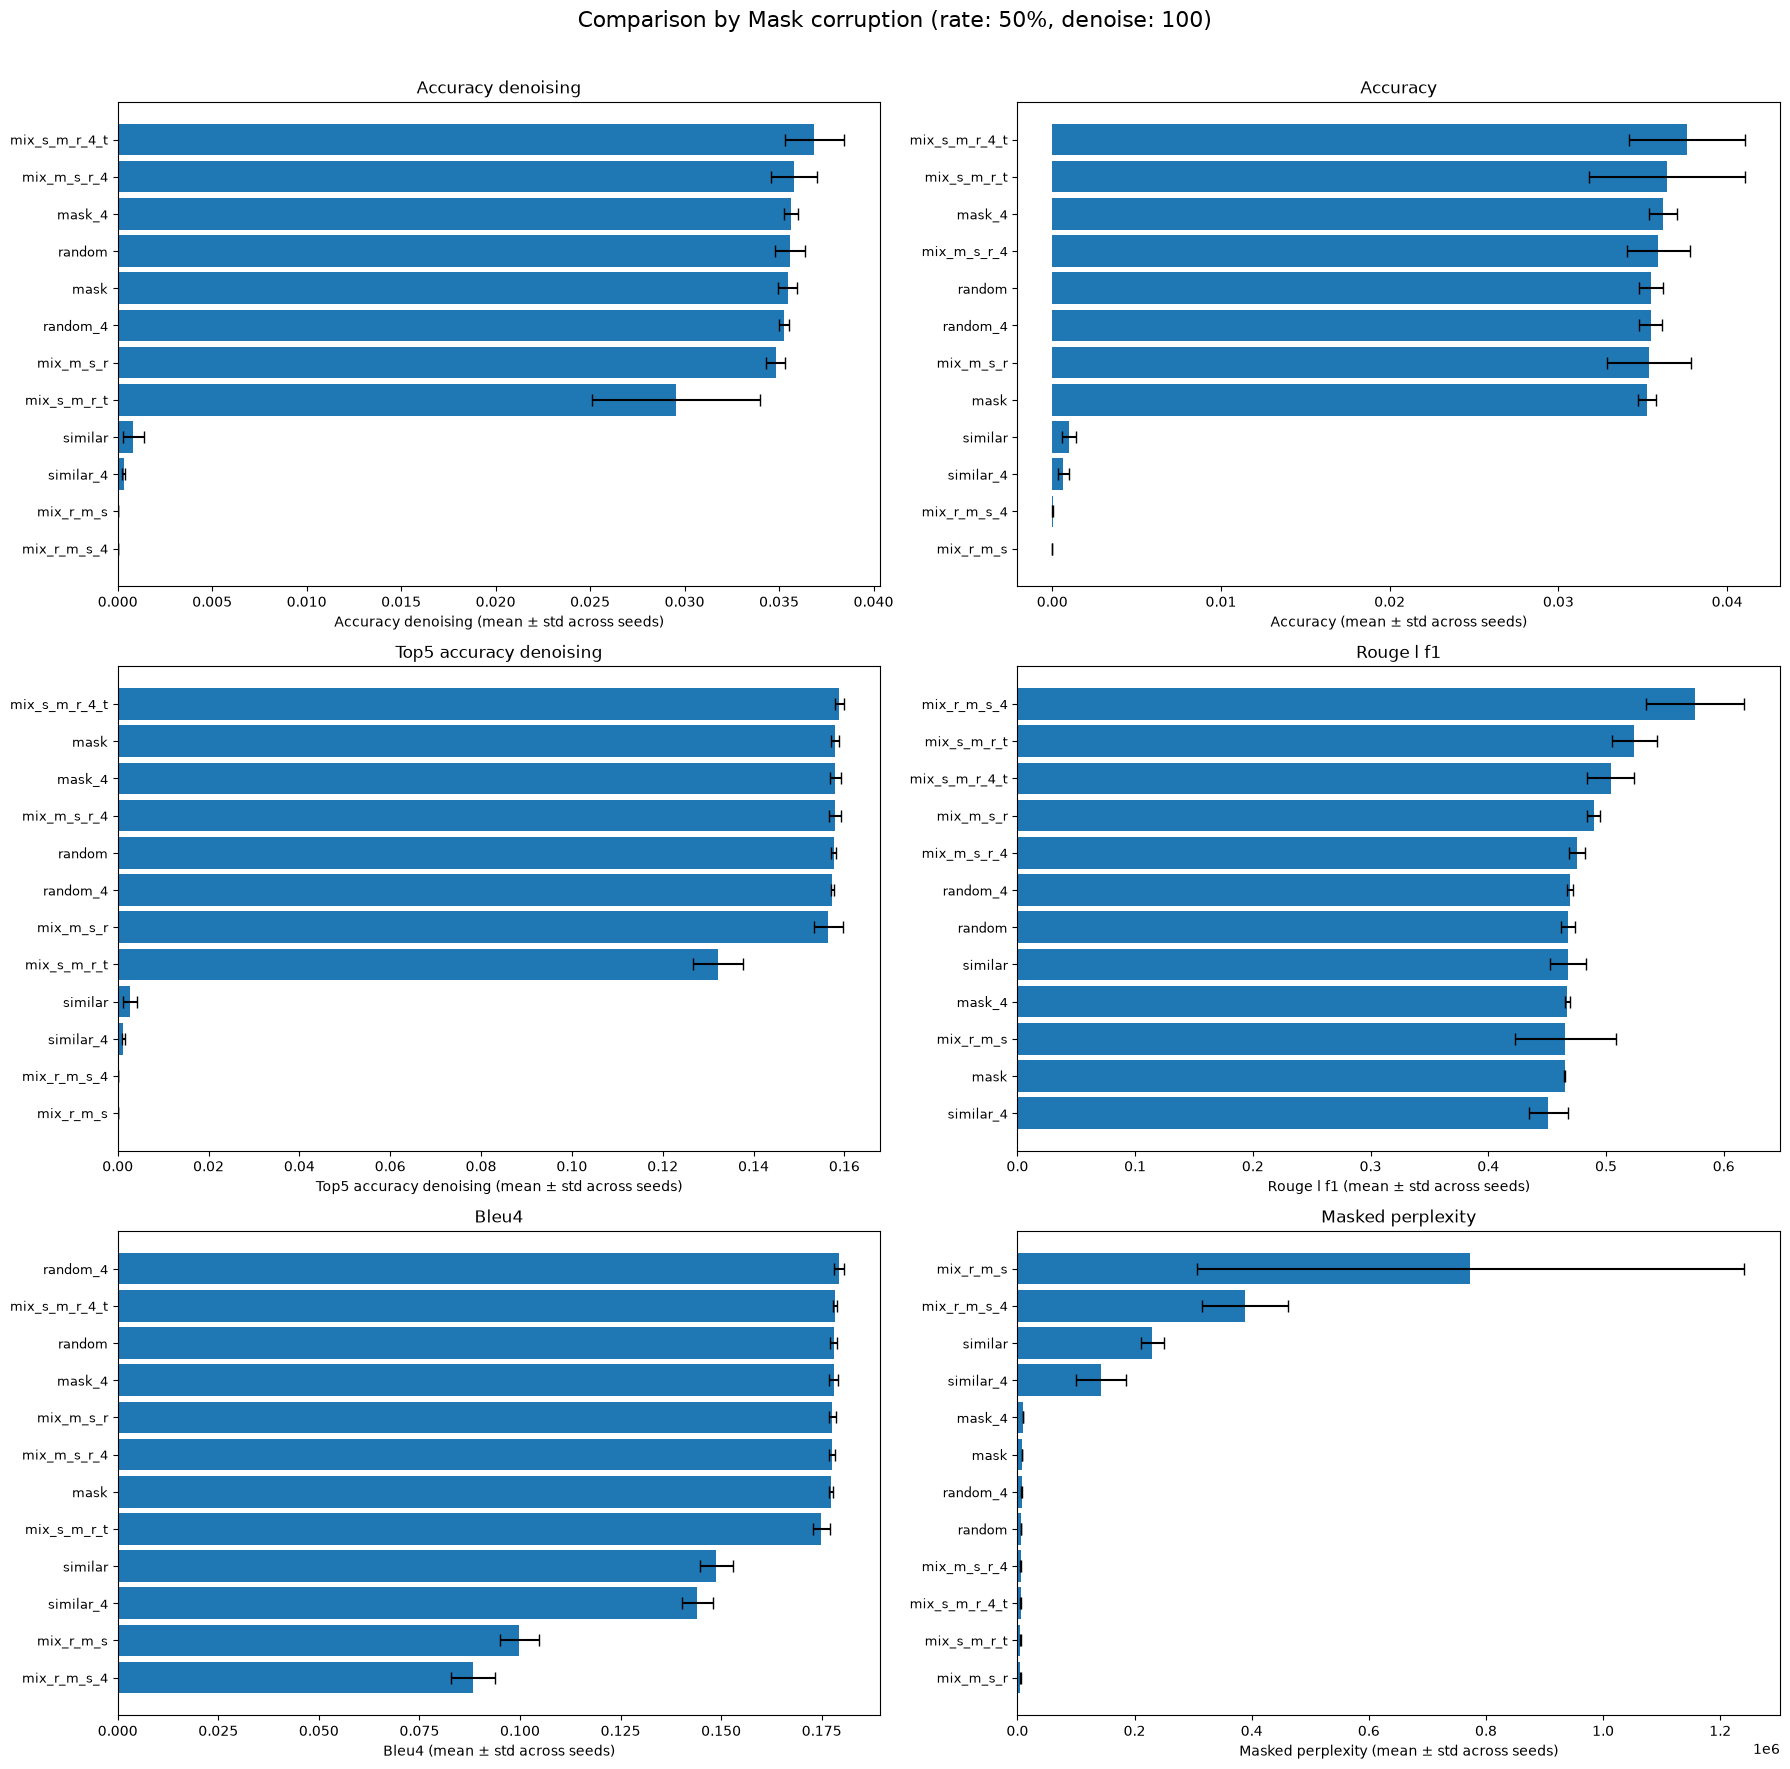

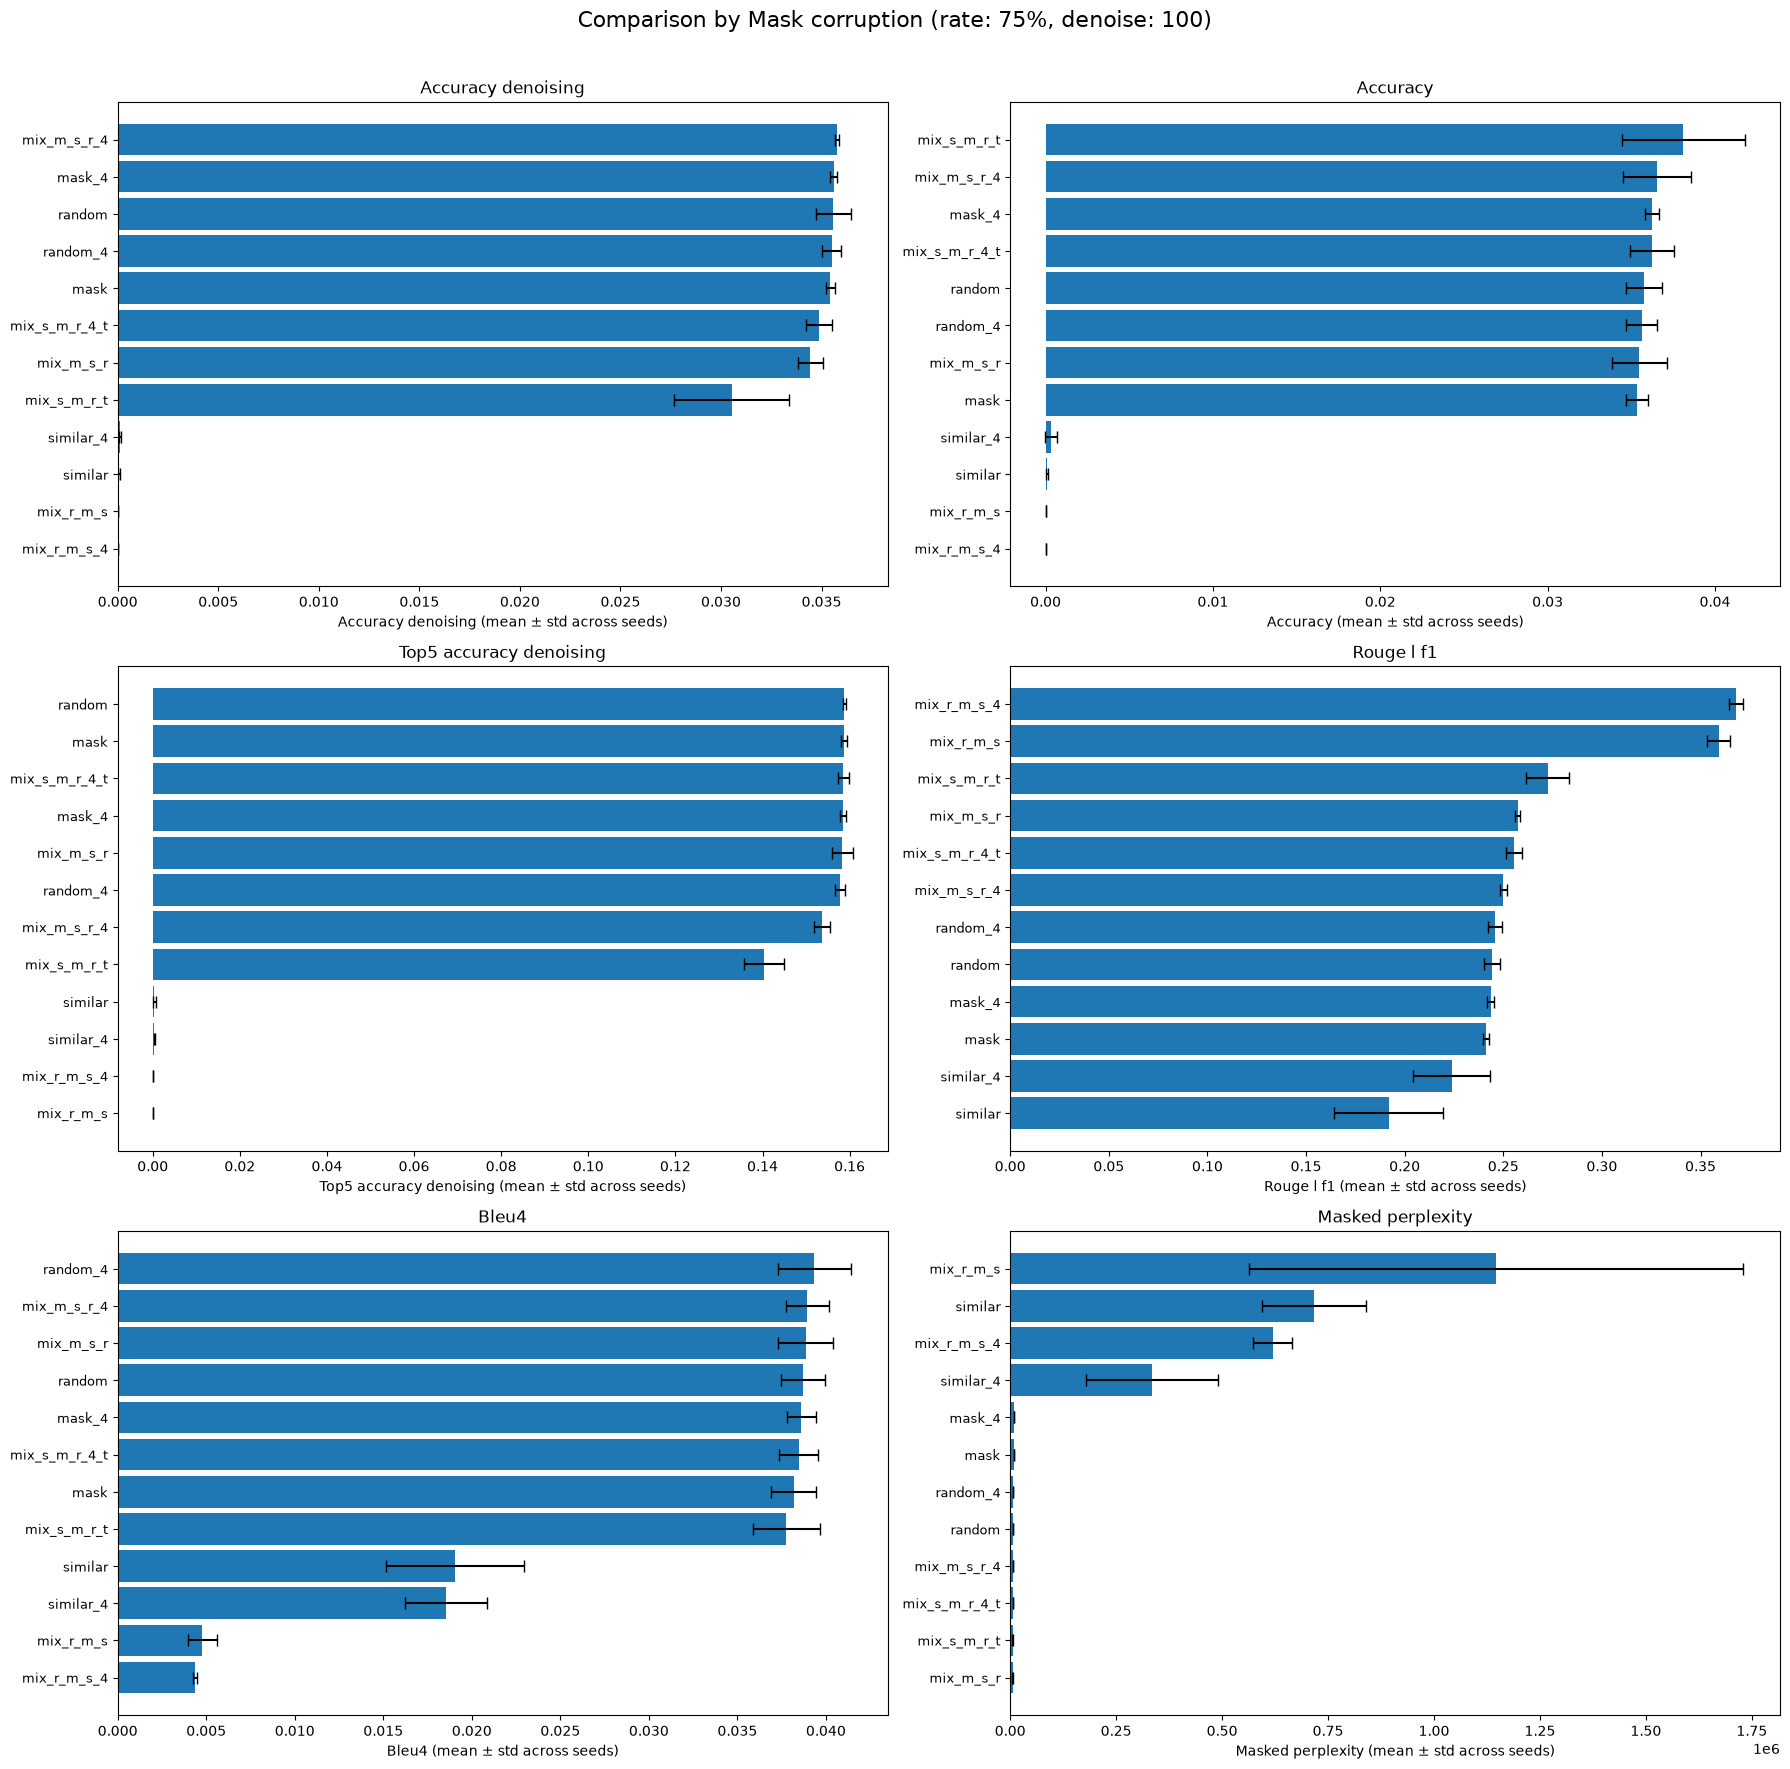

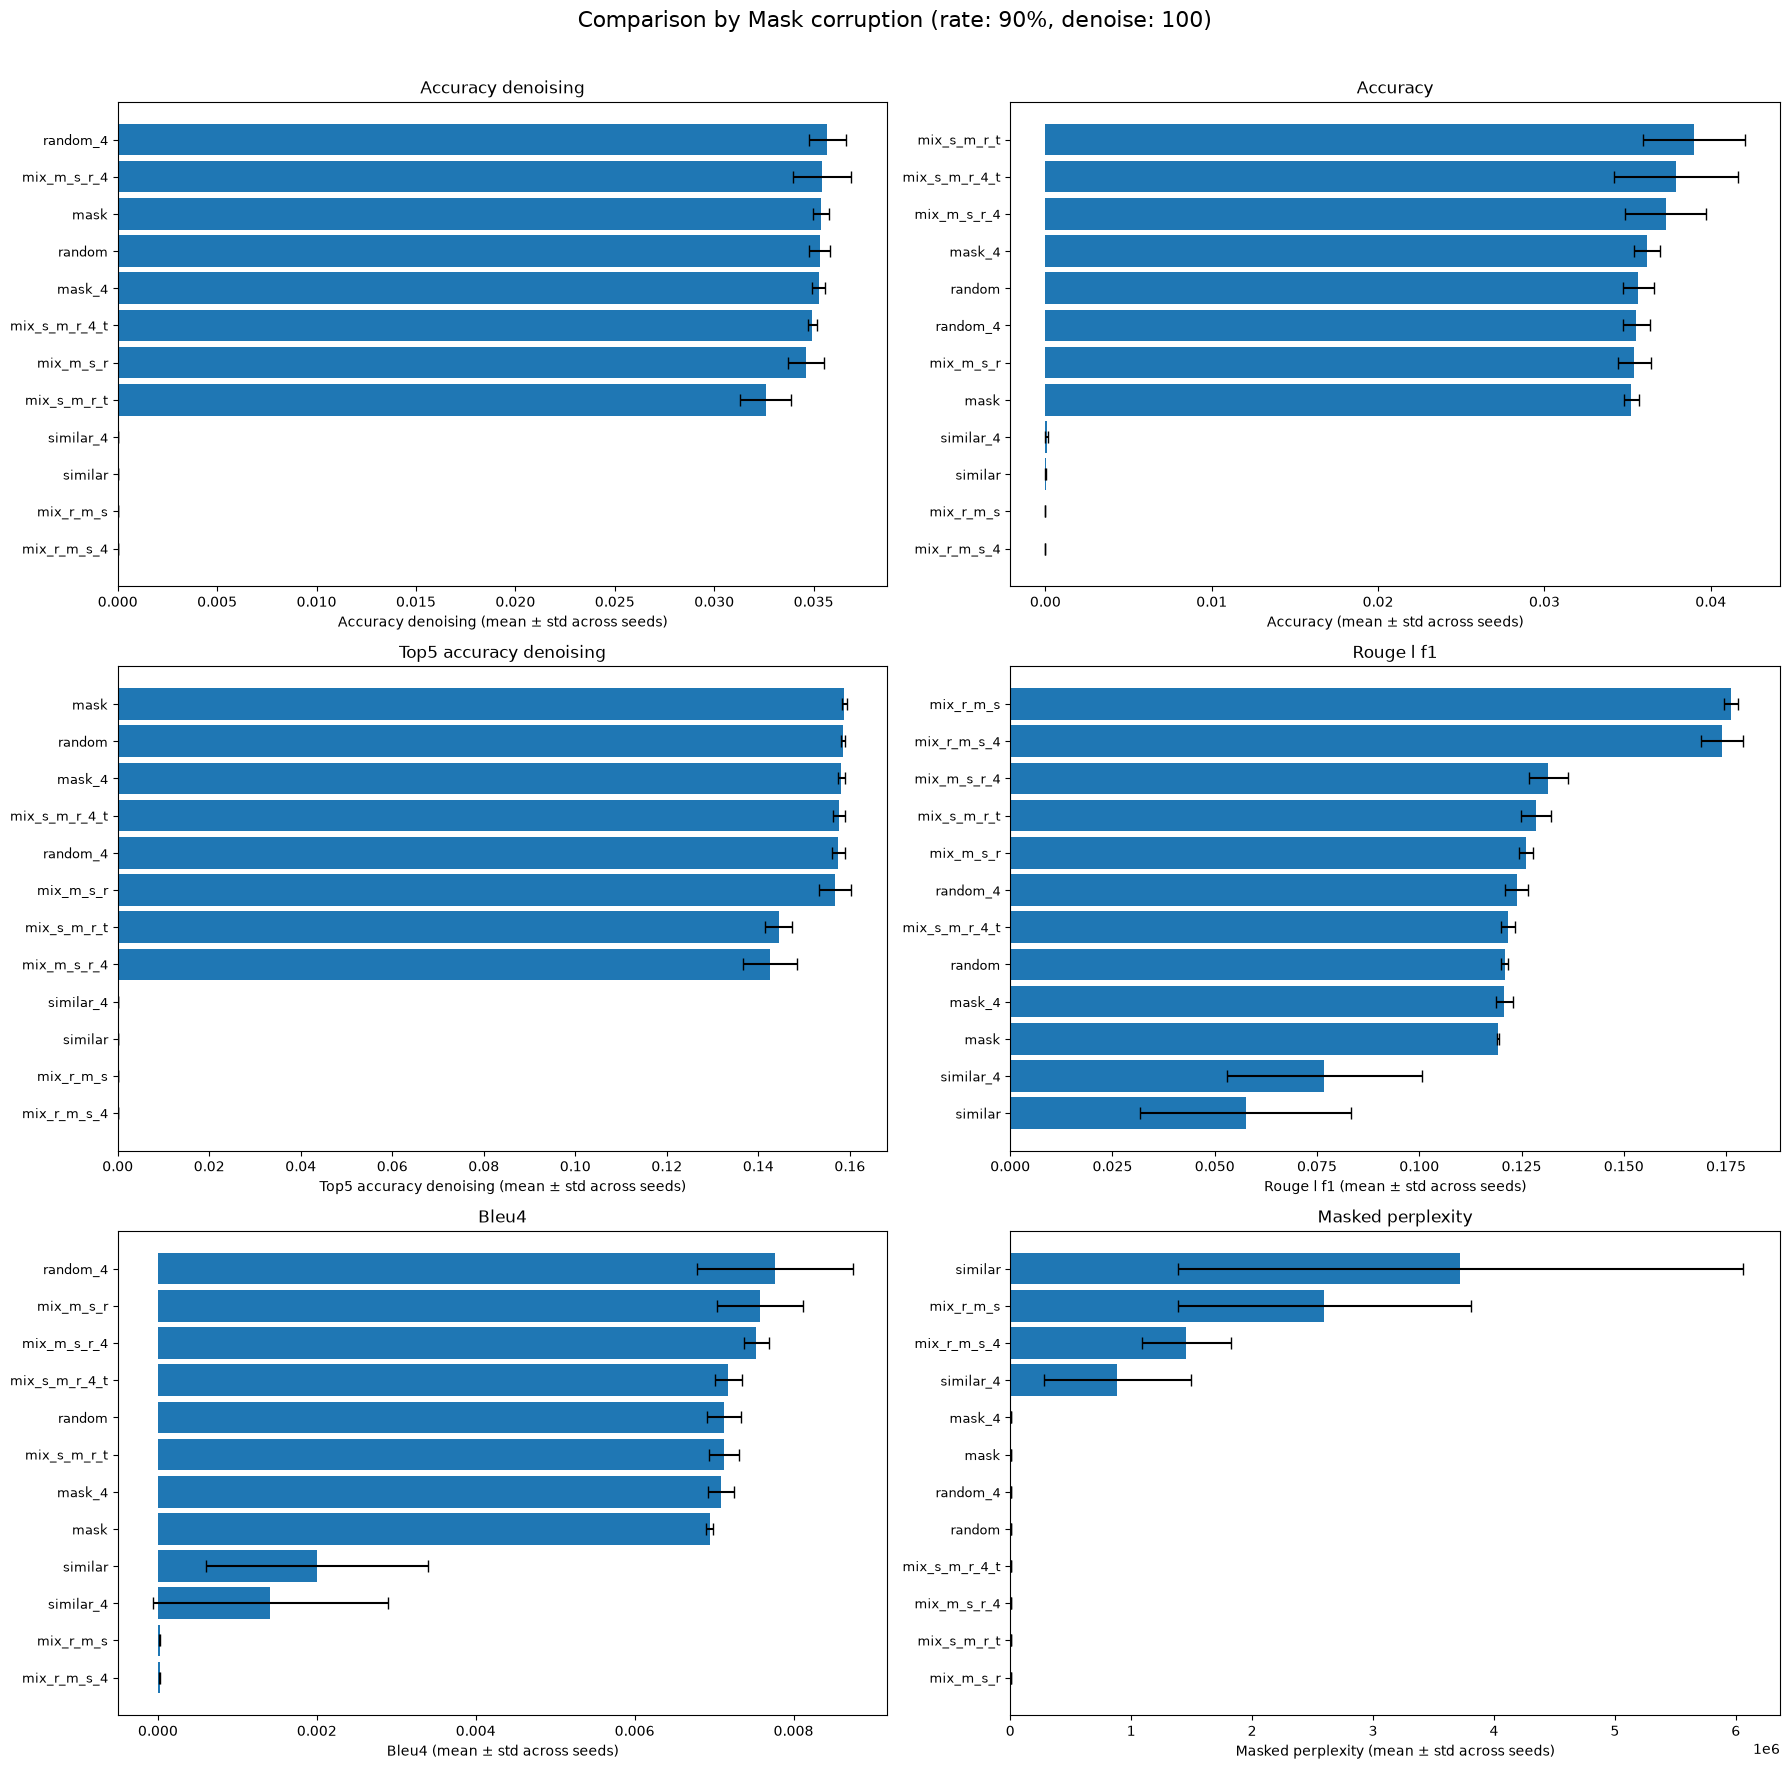

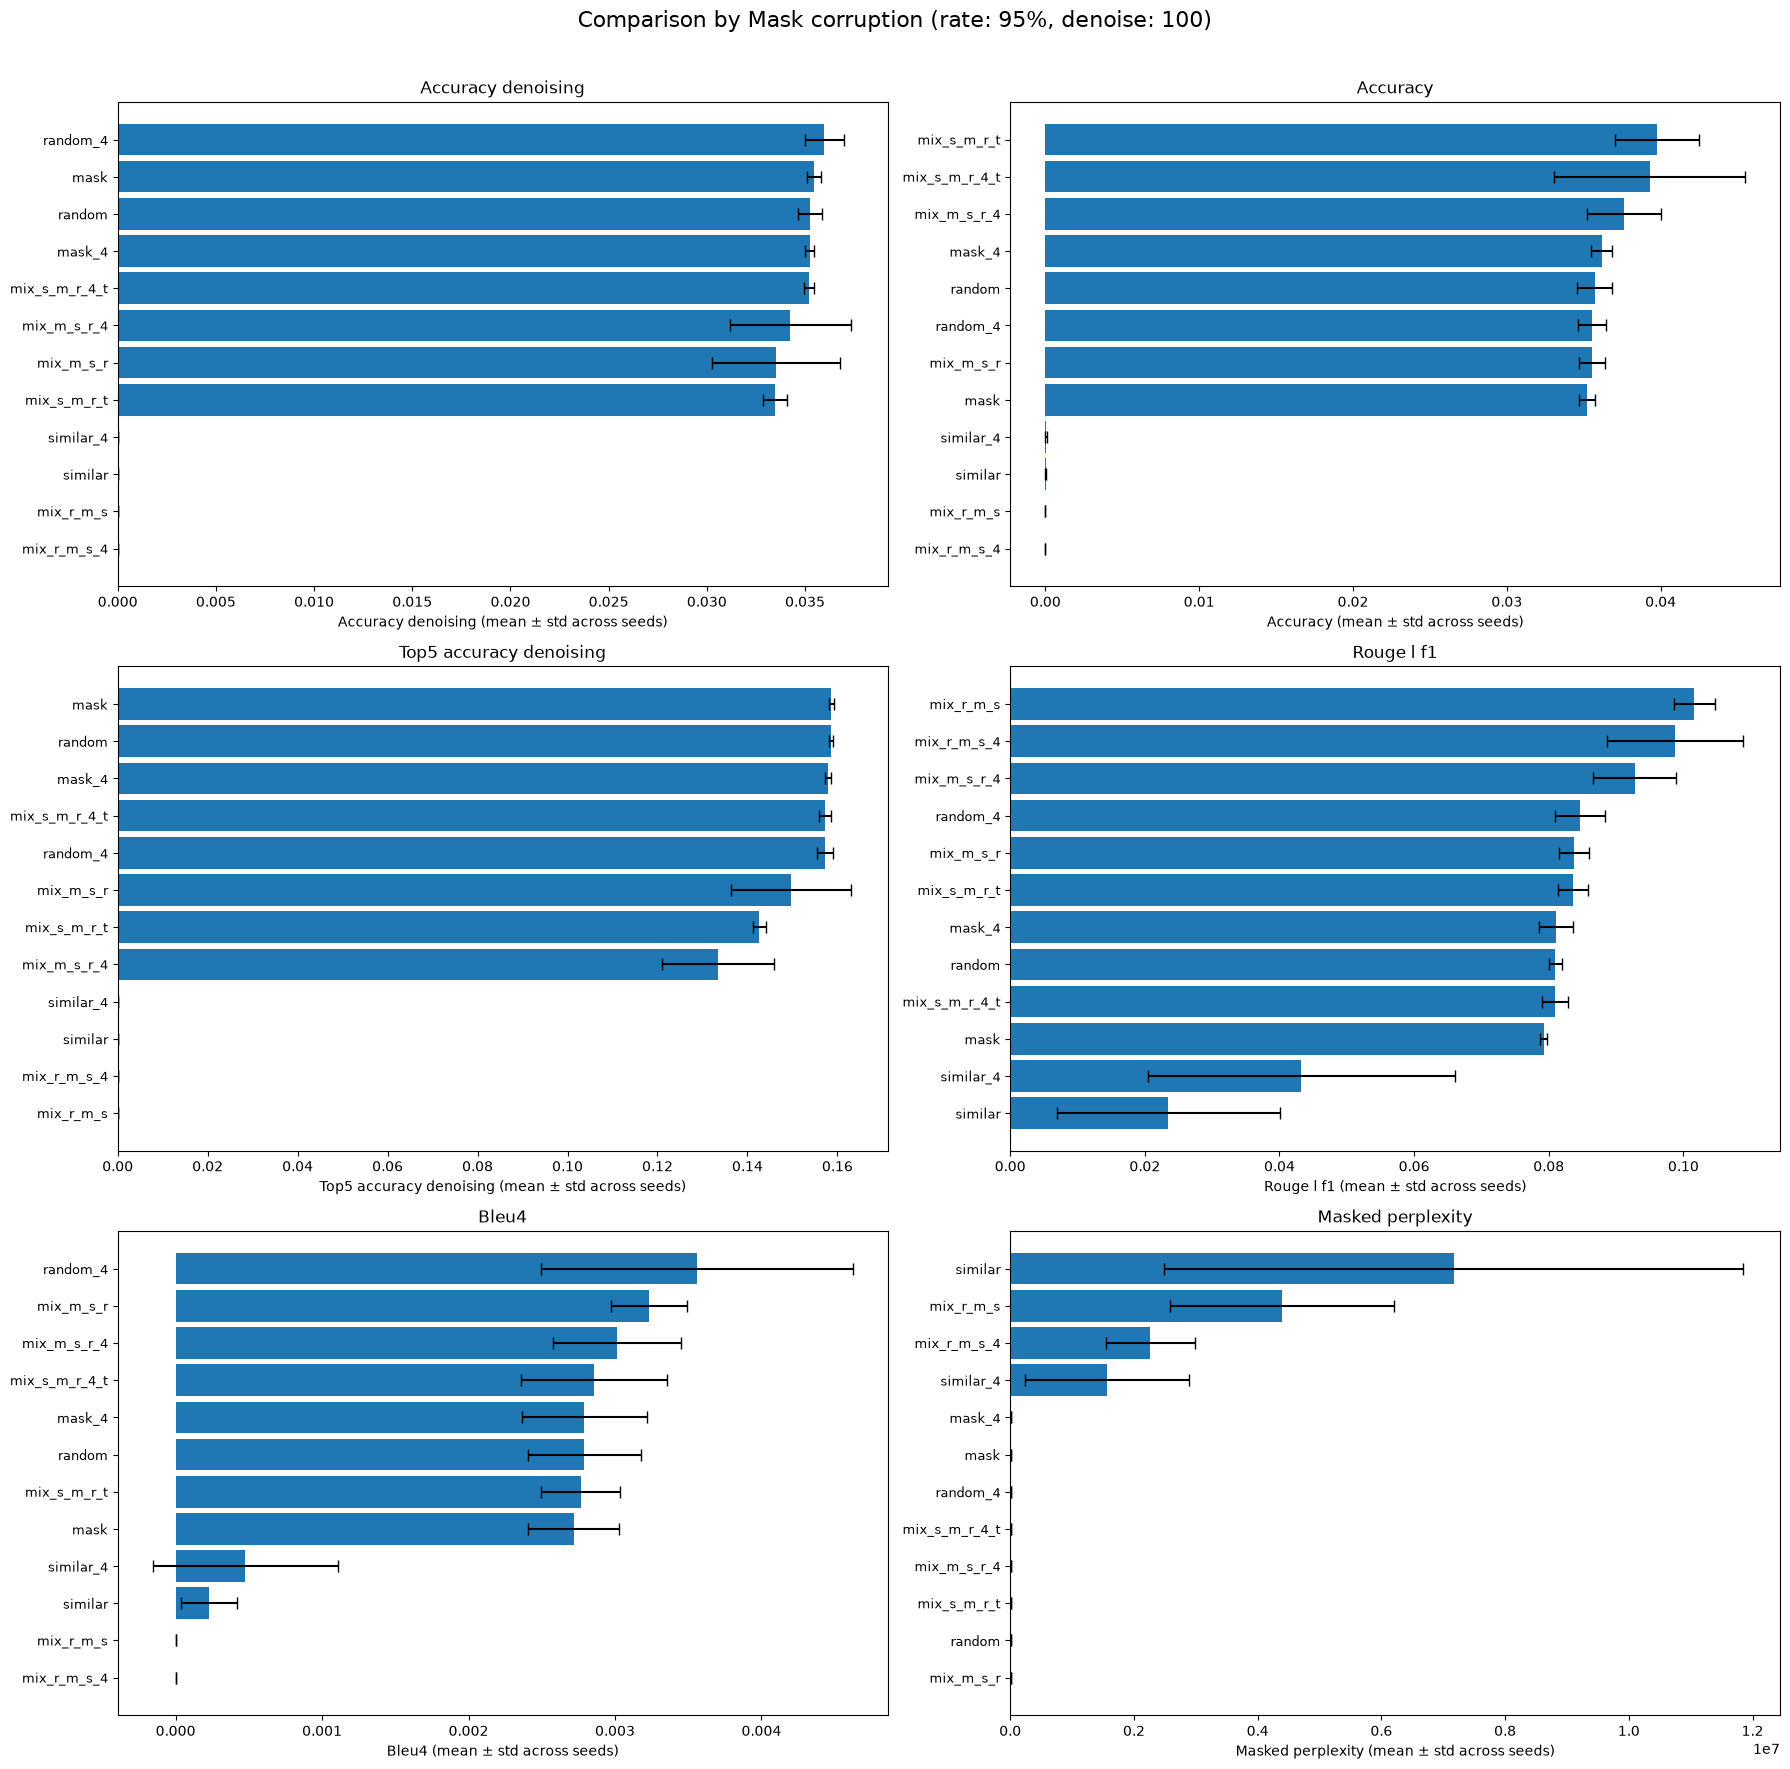

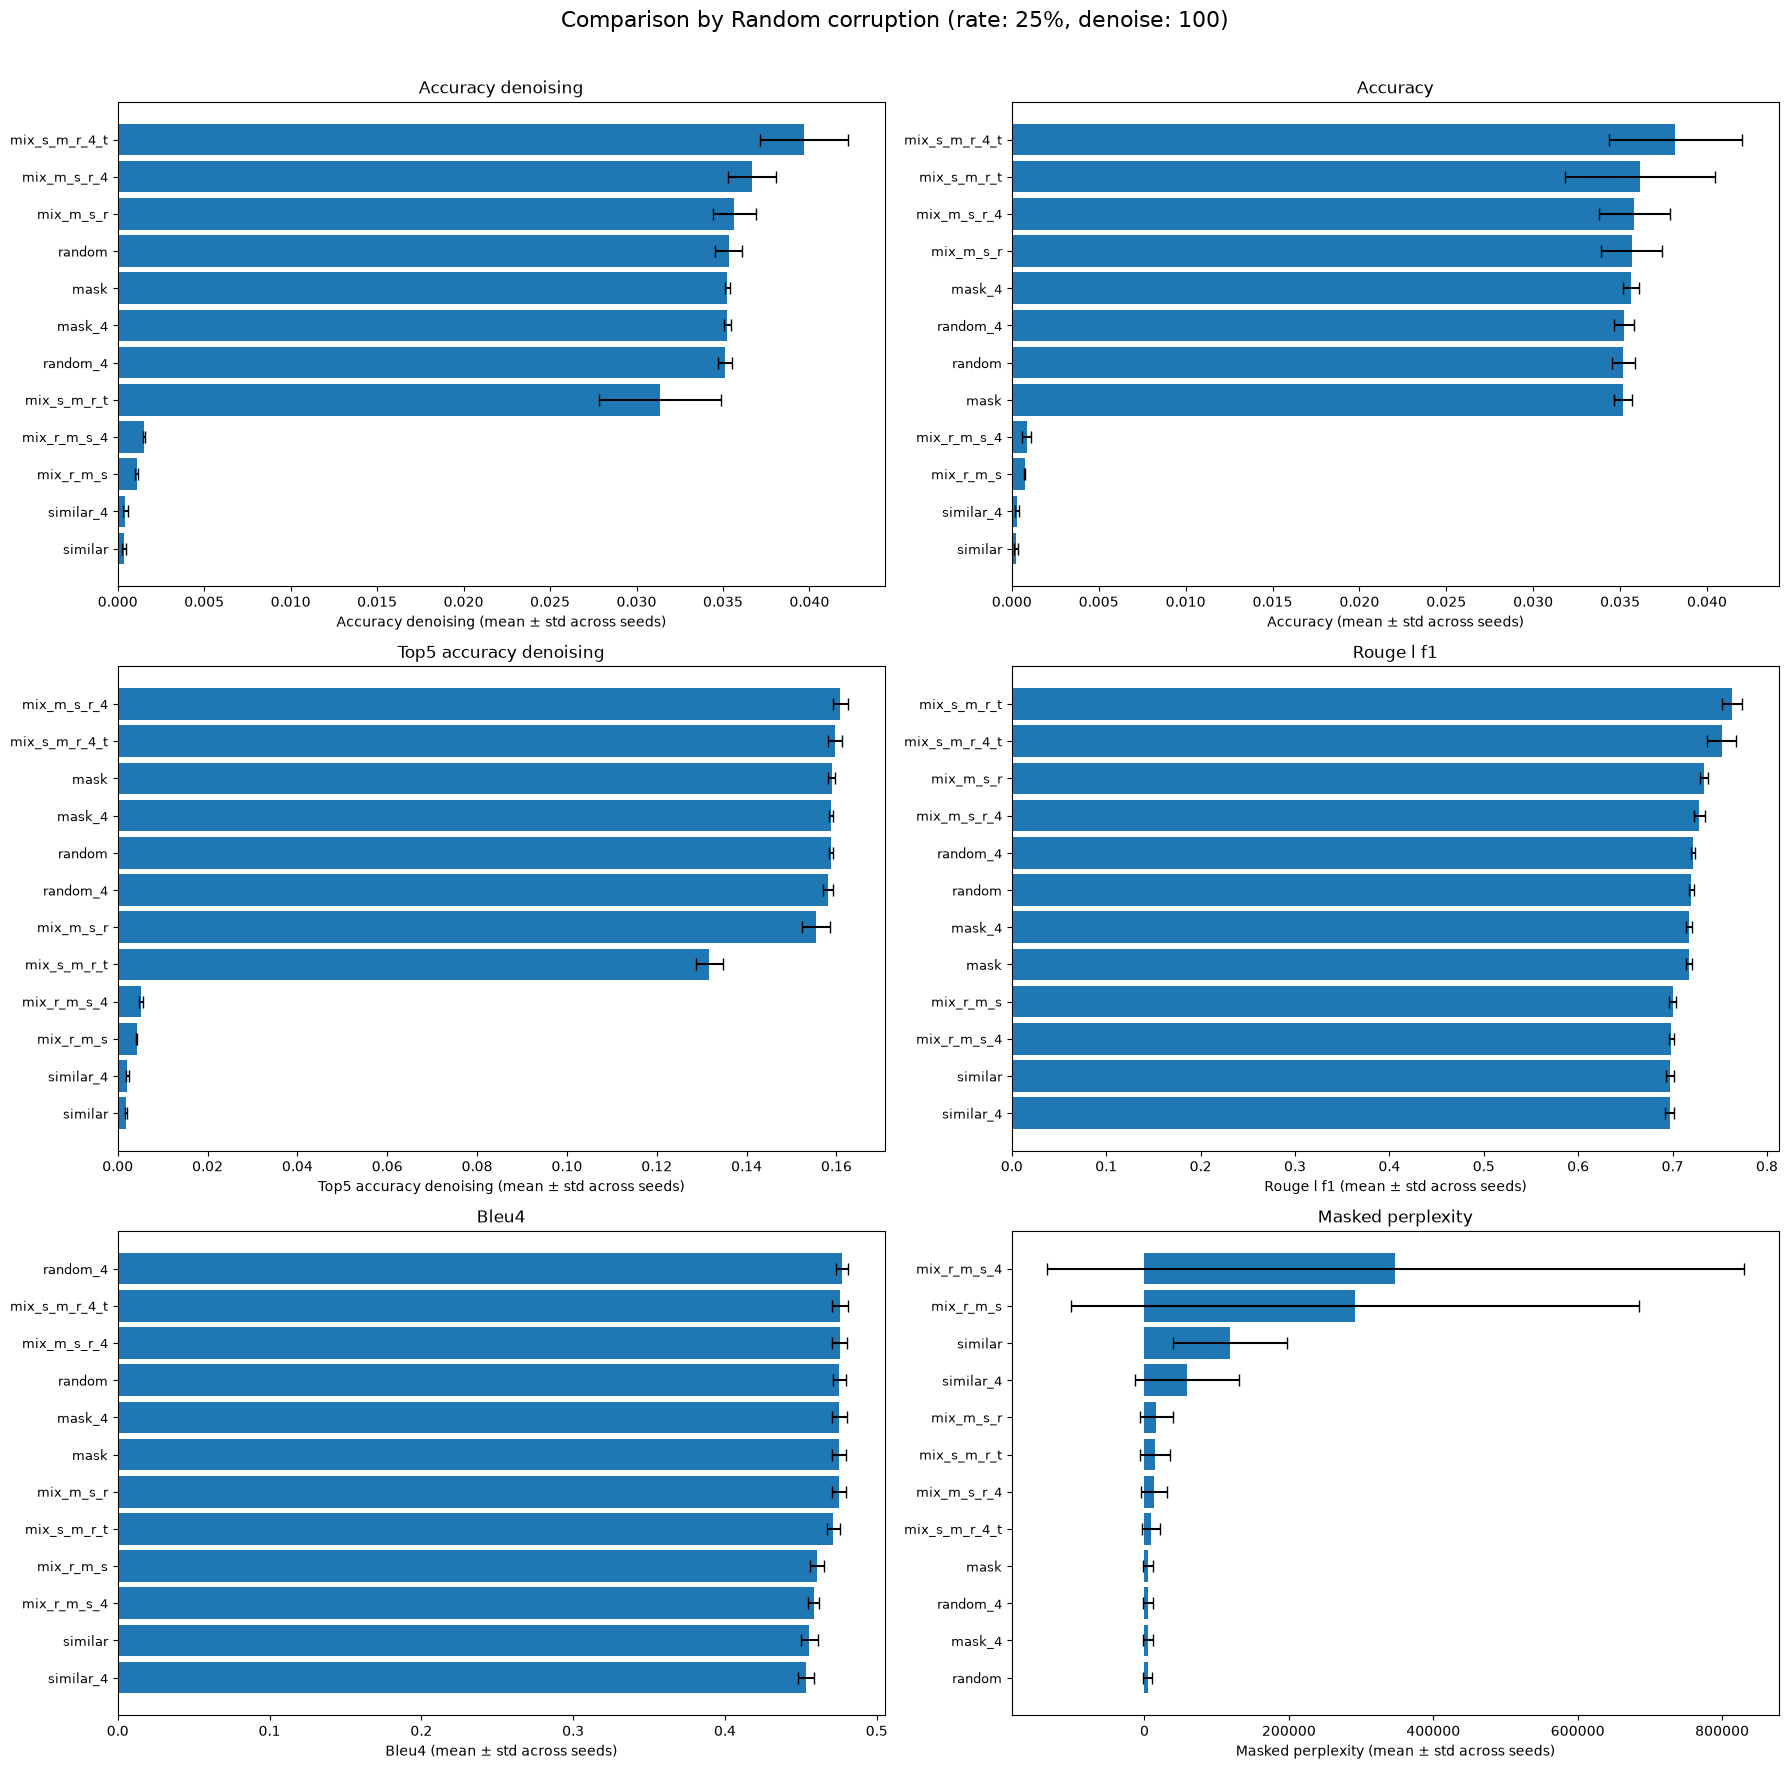

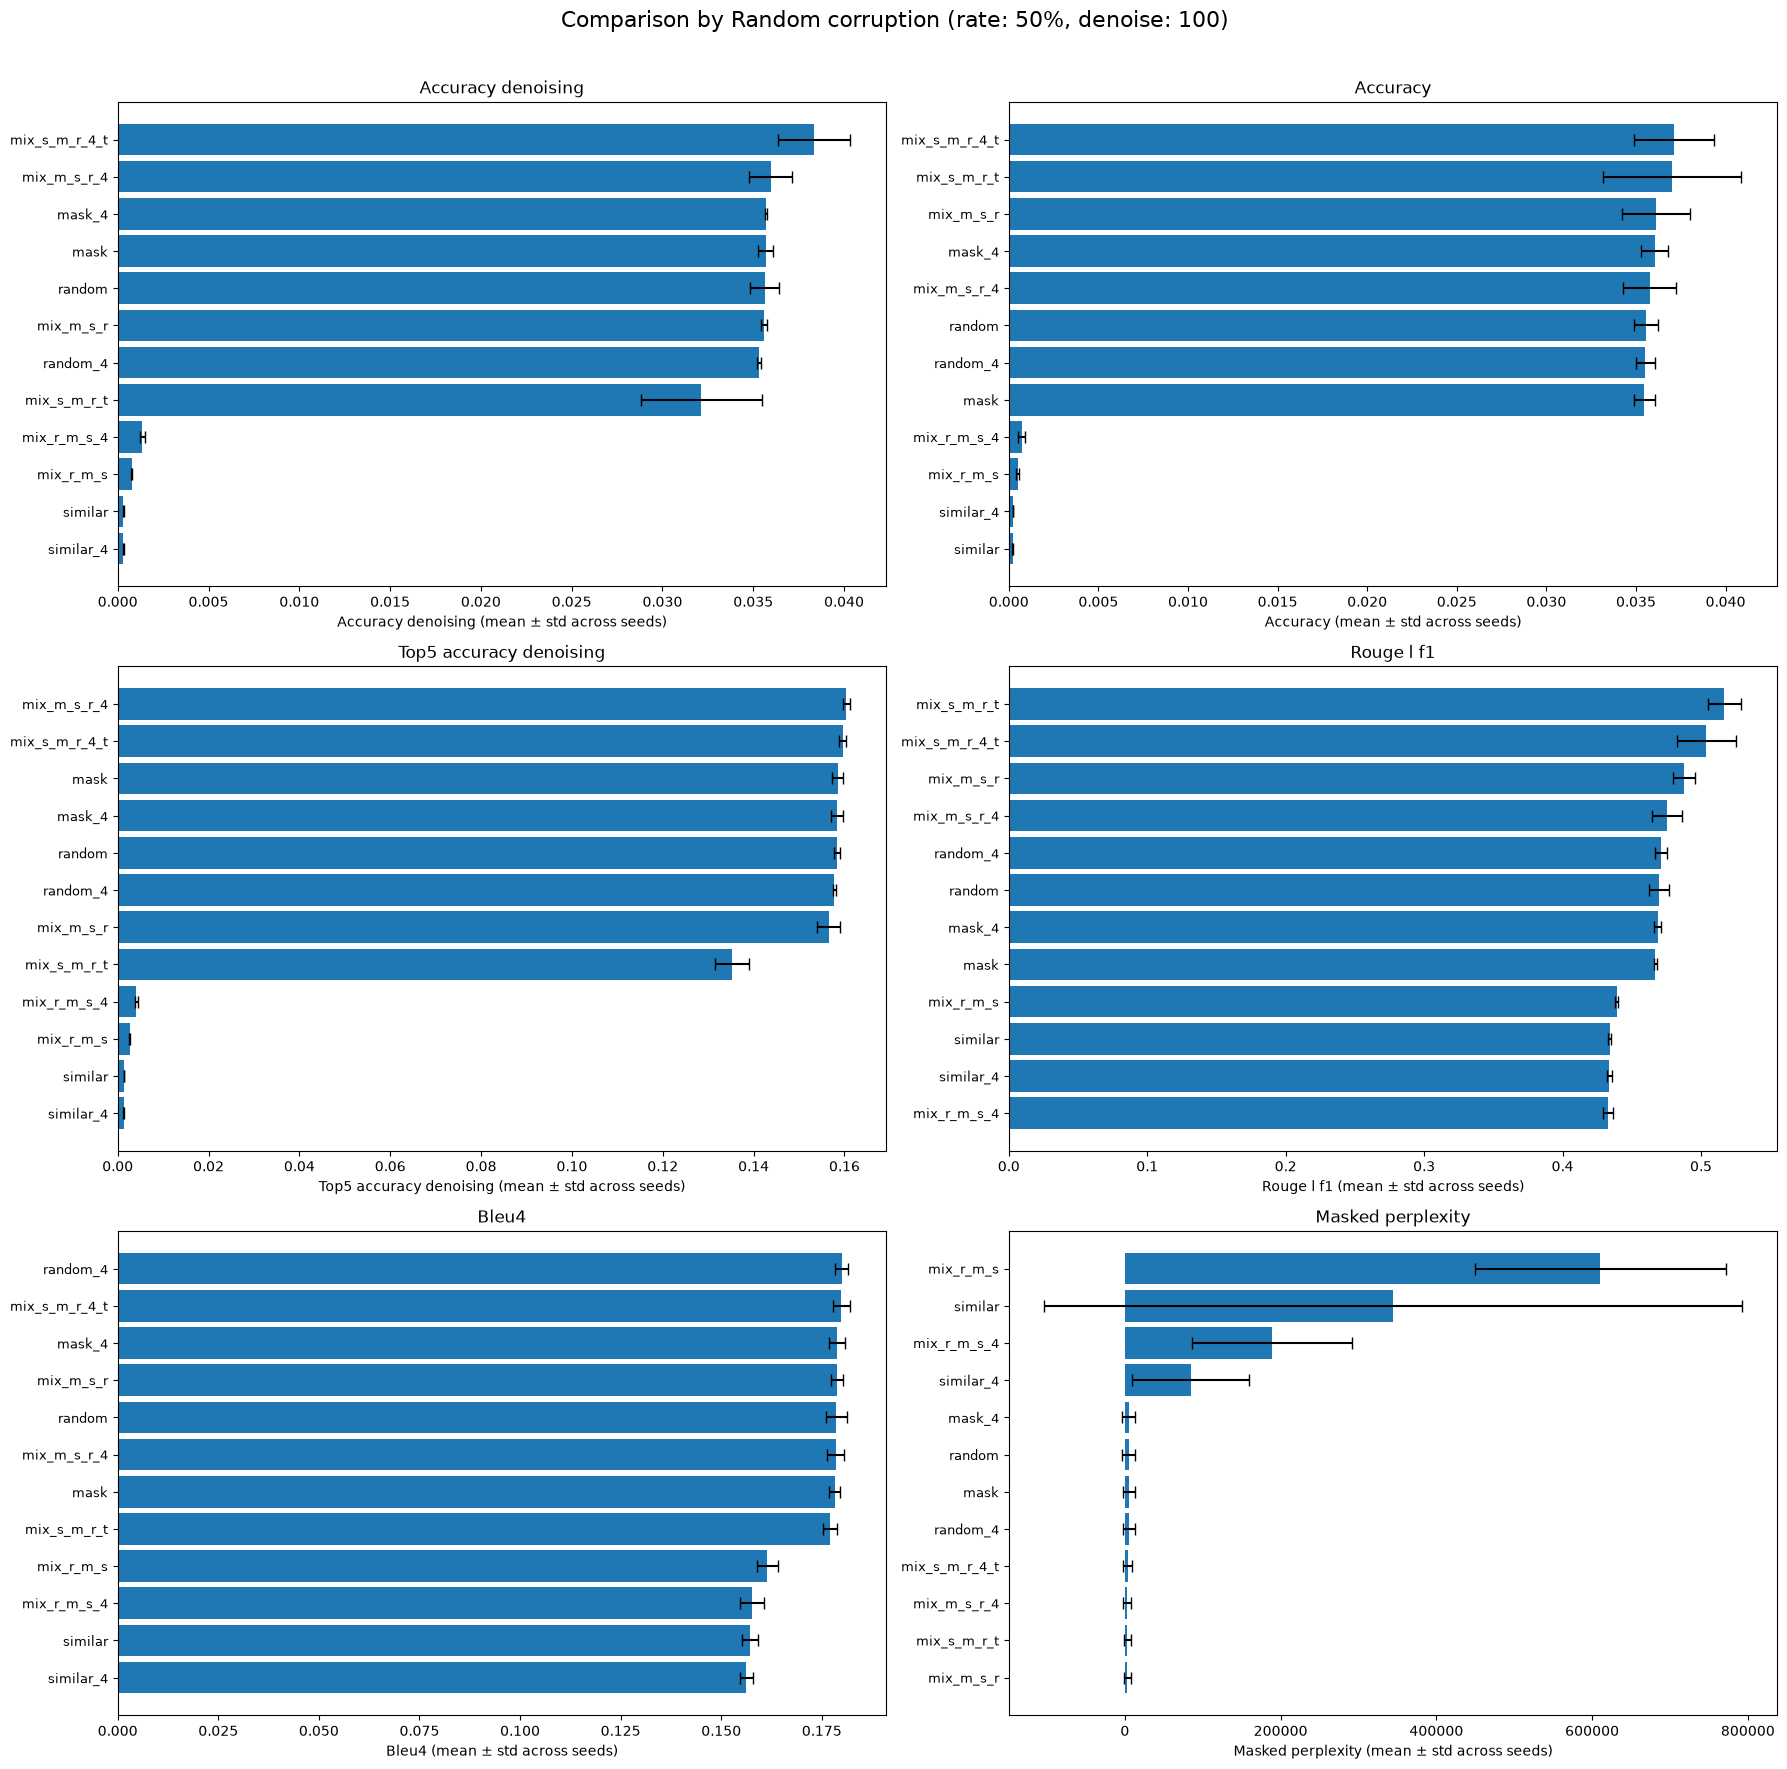

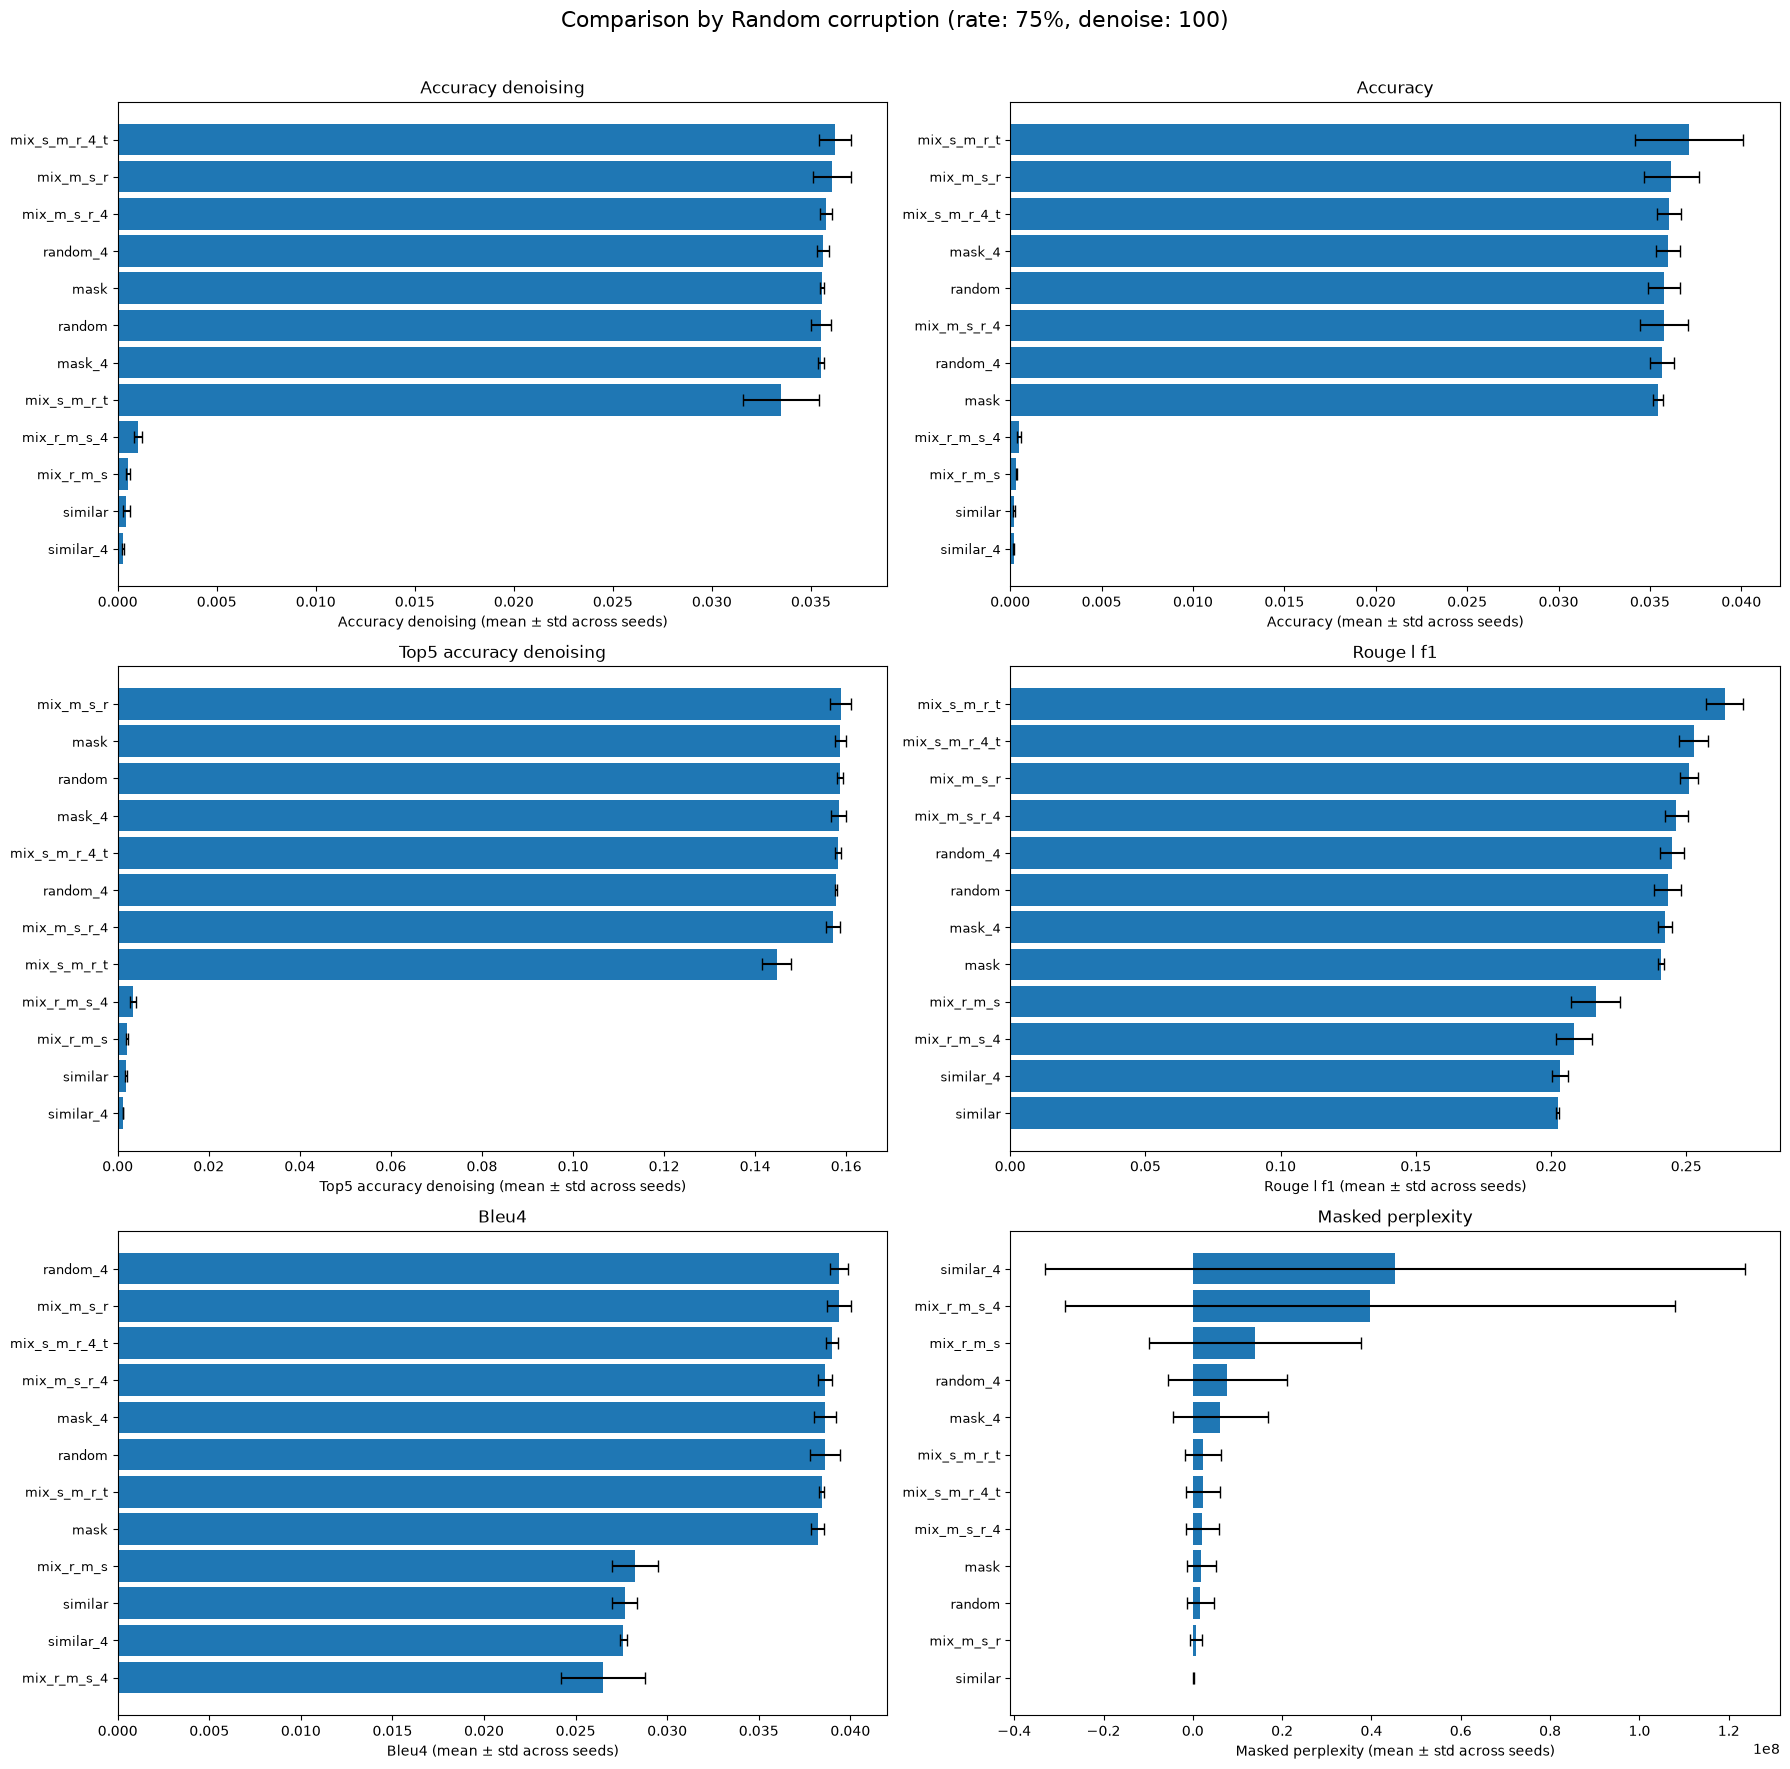

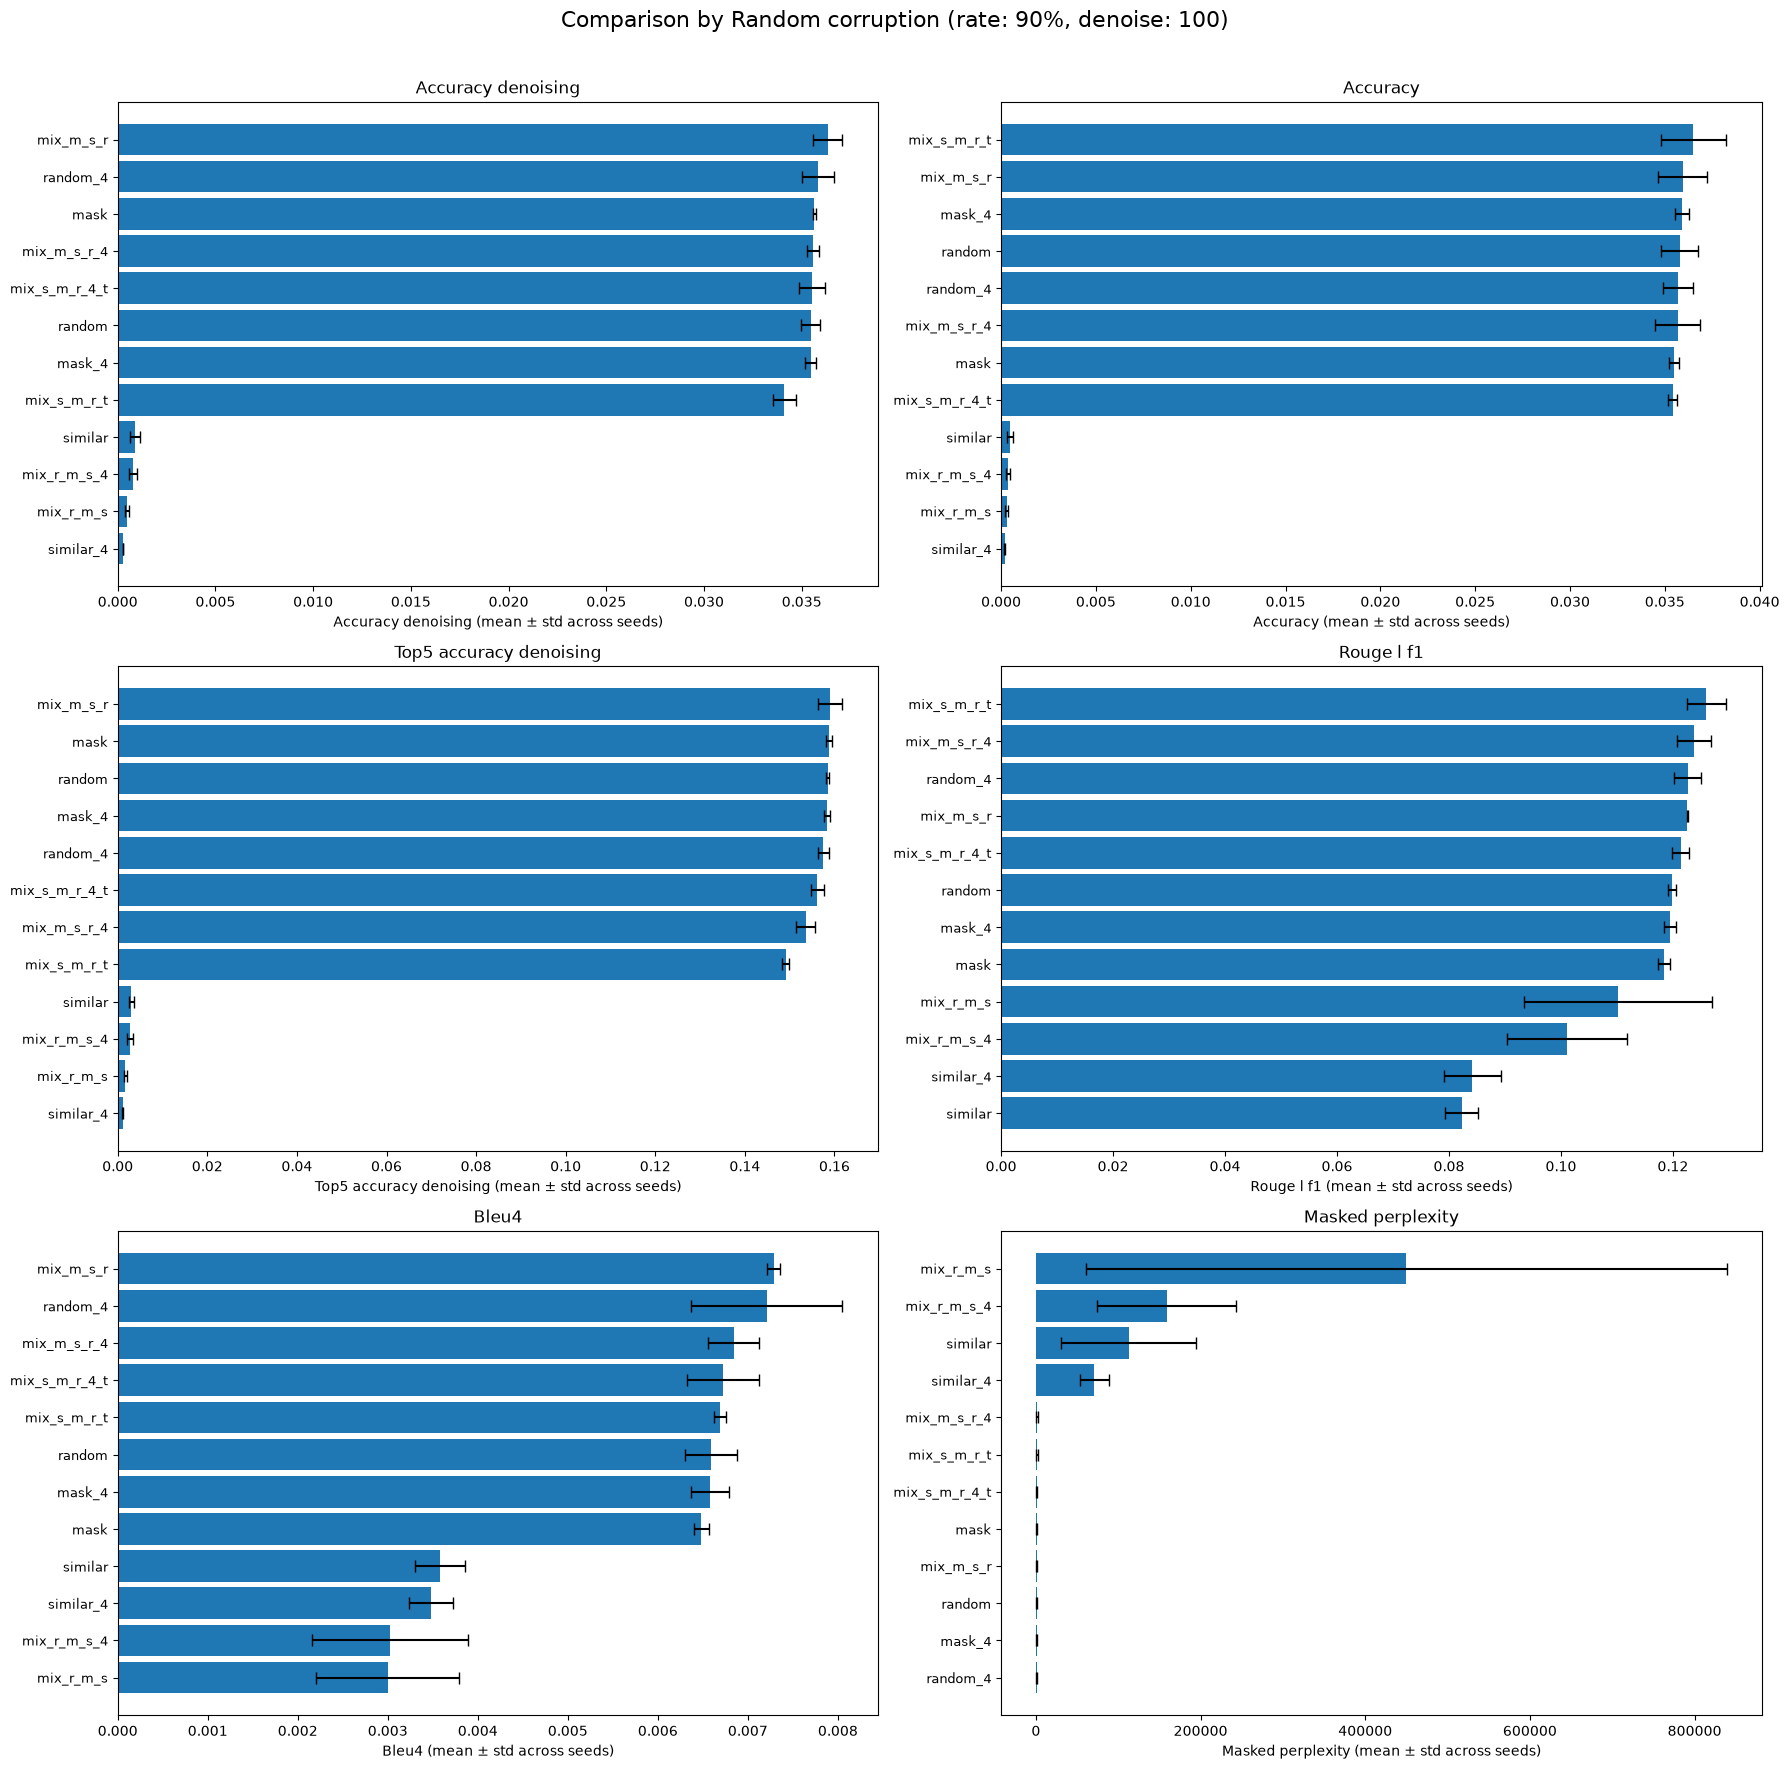

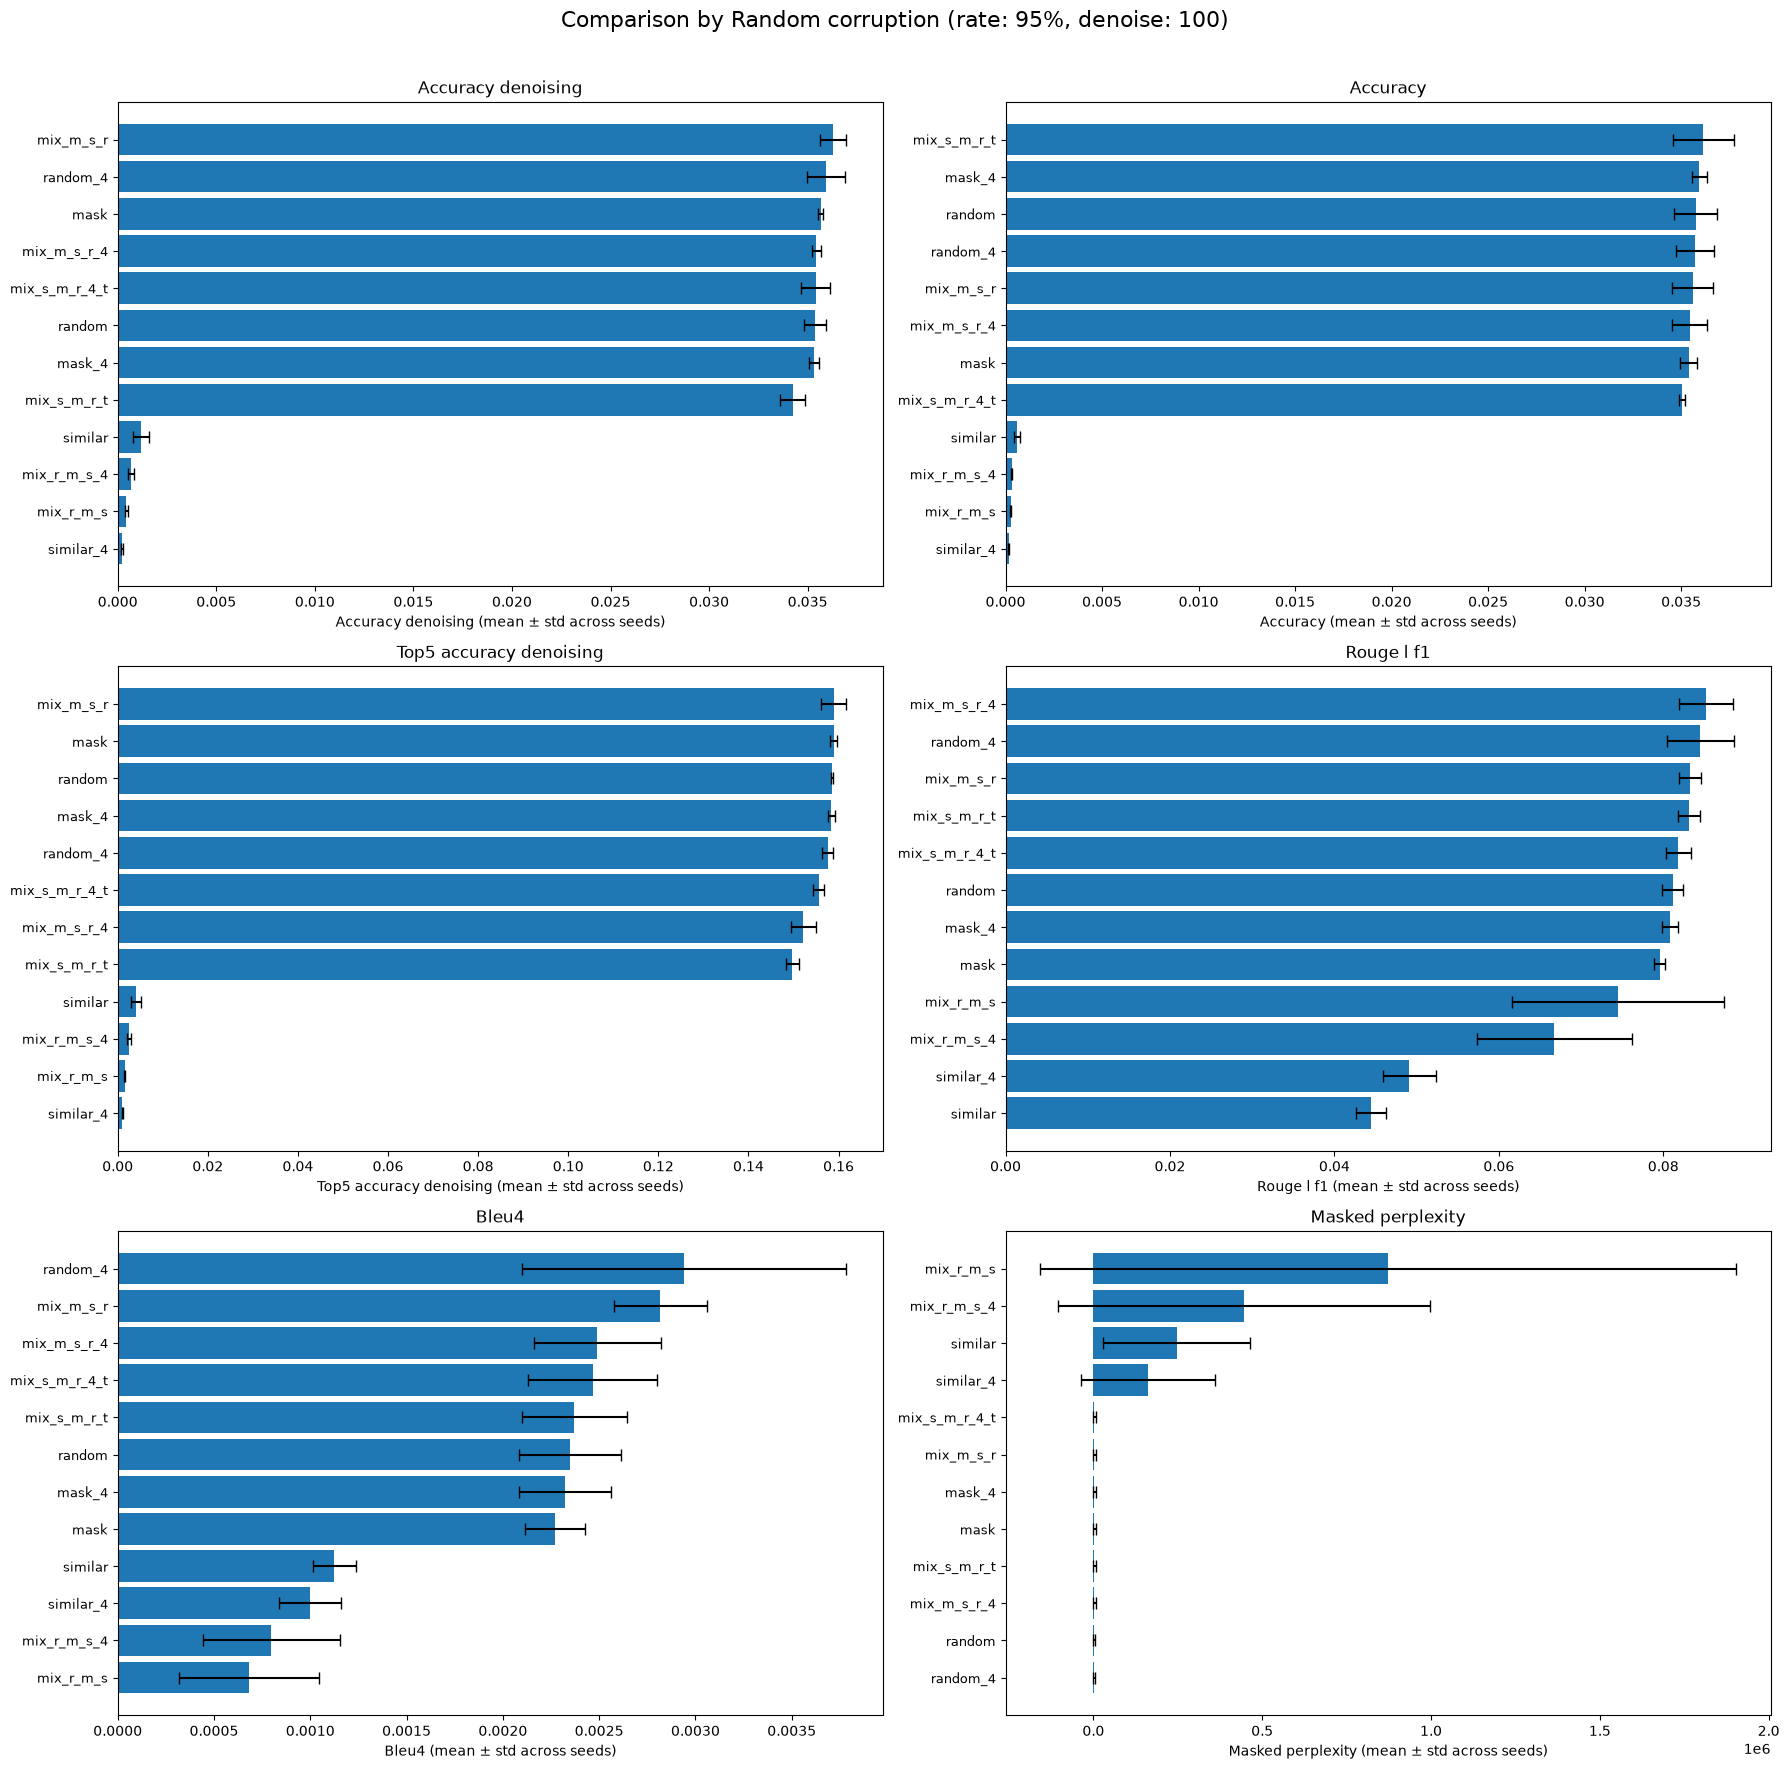

In [16]:
for (corruption_method, corruption_rate) in df_eval[['corruption_method', 'corruption_rate']].drop_duplicates().values:
    compare_models_by_method(
        df_eval,
        corruption_method,
        corruption_rate,
        denoise_iterations=int(df_eval['denoise_iterations'].max()),
        metrics=[
            'accuracy_denoising',
            'accuracy',
            'top5_accuracy_denoising',
            'rouge_l_f1',
            'bleu4',
            'masked_perplexity'
        ],
    )


## Compare metrics on random and mask corruptions

### Only mask corruption

In [17]:
df_mask = df_eval[df_eval['corruption_method'].isin(['mask'])]
df_mask_grouped = df_mask.groupby(
    ['model']
).agg(
    {
        'loss': ['mean', 'std'],
        'accuracy': ['mean', 'std'],
        'accuracy_denoising': ['mean', 'std'],
        'denoising_gain': ['mean', 'std'],
        'top5_accuracy_denoising': ['mean', 'std'],
        'rouge_l_f1': ['mean', 'std'],
        'bleu4': ['mean', 'std'],
        'masked_perplexity': ['mean', 'std']
    }
).sort_values(by=('accuracy_denoising', 'mean'), ascending=False)
df_mask_grouped

loss                accuracy           accuracy_denoising  \
                    mean       std          mean       std               mean   
model                                                                           
mix_s_m_r_4_t   8.693524  0.145297  3.787021e-02  0.003722           0.037766   
mix_m_s_r_4     8.689393  0.125190  3.667830e-02  0.002036           0.036637   
mix_m_s_r       8.629528  0.117567  3.539808e-02  0.001479           0.035925   
mask_4          9.115598  0.025977  3.611846e-02  0.000545           0.035595   
random_4        8.871776  0.023497  3.546751e-02  0.000737           0.035510   
random          8.808768  0.012816  3.554950e-02  0.000842           0.035464   
mask            9.033027  0.015589  3.521783e-02  0.000525           0.035331   
mix_s_m_r_t     8.652486  0.142529  3.784092e-02  0.003528           0.034701   
similar        13.658249  1.521721  6.989129e-04  0.000977           0.000581   
similar_4      12.684767  1.101222  4.940736e-04  0.000539           0.000418   
mix_r_m_s_4    13.555468  0.751400  7.300909e-06  0.000019           0.000017   
mix_r_m_s      14.101894  0.874591  9.402387e-07  0.000002           0.000009   

                        denoising_gain           top5_accuracy_denoising  \
                    std           mean       std                    mean   
model                                                                      
mix_s_m_r_4_t  0.002652      -0.000105  0.003384                0.158138   
mix_m_s_r_4    0.003217      -0.000042  0.004168                0.149370   
mix_m_s_r      0.001954       0.000527  0.002232                0.154397   
mask_4         0.000723      -0.000523  0.000985                0.158033   
random_4       0.000647       0.000042  0.000673                0.157800   
random         0.000678      -0.000086  0.000425                0.158403   
mask           0.000429       0.000113  0.000368                0.158165   
mix_s_m_r_t    0.003941      -0.003140  0.003474                0.140750   
similar        0.000837      -0.000118  0.000273                0.001602   
similar_4      0.000562      -0.000076  0.000267                0.001456   
mix_r_m_s_4    0.000105       0.000009  0.000099                0.000160   
mix_r_m_s      0.000035       0.000008  0.000035                0.000118   

                        rouge_l_f1               bleu4            \
                    std       mean       std      mean       std   
model                                                              
mix_s_m_r_4_t  0.002980   0.349467  0.255546  0.141421  0.181182   
mix_m_s_r_4    0.014351   0.350697  0.242569  0.141337  0.181116   
mix_m_s_r      0.005647   0.345743  0.249028  0.141359  0.180898   
mask_4         0.000595   0.328321  0.239622  0.140990  0.181257   
random_4       0.000807   0.326831  0.238958  0.141211  0.181293   
random         0.000567   0.326269  0.239589  0.140846  0.181270   
mask           0.000707   0.324673  0.239458  0.140746  0.181263   
mix_s_m_r_t    0.008276   0.359171  0.259283  0.140361  0.179793   
similar        0.002158   0.293334  0.273637  0.125220  0.177520   
similar_4      0.001785   0.288273  0.254954  0.123135  0.174753   
mix_r_m_s_4    0.000626   0.383130  0.234992  0.104549  0.166221   
mix_r_m_s      0.000464   0.348500  0.212735  0.102908  0.159760   

              masked_perplexity                
                           mean           std  
model                                          
mix_s_m_r_4_t      6.026049e+03  8.585713e+02  
mix_m_s_r_4        5.985336e+03  7.360525e+02  
mix_m_s_r          5.633021e+03  6.653301e+02  
mask_4             9.099120e+03  2.366236e+02  
random_4           7.129878e+03  1.668469e+02  
random             6.693216e+03  8.576143e+01  
mask               8.376181e+03  1.305516e+02  
mix_s_m_r_t        5.782541e+03  8.301643e+02  
similar            2.395932e+06  3.343421e+06  
similar_4          6.035767e+05  7.785497e+05  
mix_r_m_s_4       

### Only random corruption

In [18]:
df_random = df_eval[df_eval['corruption_method'].isin(['random'])]
df_random_grouped = df_random.groupby(
    ['model']
).agg(
    {
        'loss': ['mean', 'std'],
        'accuracy': ['mean', 'std'],
        'accuracy_denoising': ['mean', 'std'],
        'denoising_gain': ['mean', 'std'],
        'top5_accuracy_denoising': ['mean', 'std'],
        'rouge_l_f1': ['mean', 'std'],
        'bleu4': ['mean', 'std']
    }
).sort_values(by=('accuracy_denoising', 'mean'), ascending=False)
df_random_grouped

loss            accuracy           accuracy_denoising  \
                    mean       std      mean       std               mean   
model                                                                       
mix_s_m_r_4_t   8.773895  0.151954  0.036367  0.002014           0.037681   
mix_m_s_r_4     8.721072  0.134032  0.035692  0.001185           0.036976   
mix_m_s_r       8.690031  0.128783  0.035898  0.001268           0.036832   
mix_s_m_r_t     8.744565  0.157606  0.036582  0.002564           0.035849   
mask_4          9.108559  0.024095  0.035906  0.000471           0.035616   
random_4        8.871849  0.022972  0.035561  0.000619           0.035556   
random          8.808160  0.012043  0.035613  0.000758           0.035532   
mask            9.032386  0.020006  0.035389  0.000376           0.035479   
mix_r_m_s_4    11.795278  0.234431  0.000552  0.000243           0.001006   
mix_r_m_s      12.400680  0.488258  0.000425  0.000178           0.000735   
similar        14.825984  0.717379  0.000352  0.000180           0.000633   
similar_4      15.545390  0.743737  0.000211  0.000063           0.000347   

                        denoising_gain           top5_accuracy_denoising  \
                    std           mean       std                    mean   
model                                                                      
mix_s_m_r_4_t  0.002756       0.001315  0.002249                0.157733   
mix_m_s_r_4    0.001944       0.001284  0.002120                0.156390   
mix_m_s_r      0.001487       0.000934  0.001711                0.156710   
mix_s_m_r_t    0.002677      -0.000733  0.002735                0.143789   
mask_4         0.000489      -0.000290  0.000699                0.158349   
random_4       0.000506      -0.000005  0.000592                0.158076   
random         0.000567      -0.000081  0.000393                0.158594   
mask           0.000325       0.000091  0.000247                0.158471   
mix_r_m_s_4    0.000574       0.000454  0.000479                0.003485   
mix_r_m_s      0.000506       0.000310  0.000431                0.002688   
similar        0.000436       0.000281  0.000350                0.002803   
similar_4      0.000224       0.000135  0.000201                0.001456   

                        rouge_l_f1               bleu4            
                    std       mean       std      mean       std  
model                                                             
mix_s_m_r_4_t  0.003052   0.347582  0.256672  0.140944  0.180497  
mix_m_s_r_4    0.004893   0.345550  0.246504  0.140809  0.180267  
mix_m_s_r      0.003037   0.341476  0.248586  0.140781  0.179974  
mix_s_m_r_t    0.008490   0.356726  0.257610  0.139852  0.179056  
mask_4         0.000734   0.326929  0.239586  0.140189  0.180154  
random_4       0.000724   0.326692  0.238782  0.140448  0.180206  
random         0.000639   0.326035  0.239394  0.140113  0.180167  
mask           0.000826   0.324429  0.239366  0.140027  0.180157  
mix_r_m_s_4    0.001661   0.301403  0.238555  0.128684  0.174638  
mix_r_m_s      0.001509   0.308591  0.235315  0.129893  0.175744  
similar        0.001880   0.292219  0.244529  0.128365  0.173331  
similar_4      0.000733   0.291816  0.244063  0.128035  0.172942

### Random & mask corruption

In [19]:
df_random_mask = df_eval[df_eval['corruption_method'].isin(['random', 'mask'])]
df_random_mask_grouped = df_random_mask.groupby(
    ['model']
).agg(
    {
        'loss': ['mean', 'std'],
        'accuracy': ['mean', 'std'],
        'accuracy_denoising': ['mean', 'std'],
        'denoising_gain': ['mean', 'std'],
        'top5_accuracy_denoising': ['mean', 'std'],
        'rouge_l_f1': ['mean', 'std'],
        'bleu4': ['mean', 'std']
    }
).sort_values(by=('accuracy_denoising', 'mean'), ascending=False)
df_random_mask_grouped

loss            accuracy           accuracy_denoising  \
                    mean       std      mean       std               mean   
model                                                                       
mix_s_m_r_4_t   8.733709  0.153720  0.037118  0.003079           0.037723   
mix_m_s_r_4     8.705232  0.130384  0.036185  0.001734           0.036806   
mix_m_s_r       8.659780  0.126724  0.035648  0.001397           0.036379   
mask_4          9.112079  0.025249  0.036012  0.000519           0.035606   
random_4        8.871813  0.023188  0.035514  0.000681           0.035533   
random          8.808464  0.012413  0.035581  0.000800           0.035498   
mask            9.032706  0.017900  0.035303  0.000464           0.035405   
mix_s_m_r_t     8.698525  0.156879  0.037211  0.003141           0.035275   
similar        14.242116  1.323458  0.000525  0.000722           0.000607   
mix_r_m_s_4    12.675373  1.042253  0.000280  0.000323           0.000511   
similar_4      14.115078  1.712768  0.000353  0.000409           0.000382   
mix_r_m_s      13.251287  1.107300  0.000213  0.000247           0.000372   

                        denoising_gain           top5_accuracy_denoising  \
                    std           mean       std                    mean   
model                                                                      
mix_s_m_r_4_t  0.002699       0.000605  0.002954                0.157935   
mix_m_s_r_4    0.002658       0.000621  0.003366                0.152880   
mix_m_s_r      0.001791       0.000730  0.001995                0.155554   
mask_4         0.000616      -0.000407  0.000860                0.158191   
random_4       0.000580       0.000019  0.000633                0.157938   
random         0.000625      -0.000083  0.000408                0.158499   
mask           0.000387       0.000102  0.000313                0.158318   
mix_s_m_r_t    0.003411      -0.001936  0.003345                0.142270   
similar        0.000667       0.000081  0.000372                0.002203   
mix_r_m_s_4    0.000644       0.000232  0.000411                0.001822   
similar_4      0.000428       0.000030  0.000258                0.001456   
mix_r_m_s      0.000510       0.000159  0.000341                0.001403   

                        rouge_l_f1               bleu4            
                    std       mean       std      mean       std  
model                                                             
mix_s_m_r_4_t  0.003017   0.348525  0.255575  0.141183  0.180461  
mix_m_s_r_4    0.011262   0.348123  0.244046  0.141073  0.180314  
mix_m_s_r      0.004670   0.343609  0.248295  0.141070  0.180059  
mask_4         0.000685   0.327625  0.239103  0.140590  0.180328  
random_4       0.000778   0.326762  0.238369  0.140829  0.180372  
random         0.000610   0.326152  0.238990  0.140479  0.180341  
mask           0.000783   0.324551  0.238911  0.140387  0.180332  
mix_s_m_r_t    0.008503   0.357948  0.257909  0.140107  0.179049  
similar        0.002107   0.292777  0.258949  0.126792  0.175078  
mix_r_m_s_4    0.002084   0.342266  0.239806  0.116616  0.170554  
similar_4      0.001362   0.290045  0.249052  0.125585  0.173503  
mix_r_m_s      0.001703   0.328545  0.224731  0.116401  0.168135

In [20]:
def plot_metric_barplots(grouped_df, figsize=(18, 12)):
    metrics = [
        ('loss', 'Loss', False),
        ('accuracy_denoising', 'Denoising Accuracy', True),
        ('denoising_gain', 'Denoising Gain', True),
        ('top5_accuracy_denoising', 'Top-5 Denoising Accuracy', True),
        ('rouge_l_f1', 'ROUGE-L F1 Score', True),
        ('bleu4', 'BLEU-4 Score', True)
    ]

    fig, axes = plt.subplots(len(metrics) // 2, 2, figsize=figsize)
    axes = axes.flatten()

    models = grouped_df.index.astype(str)
    x = np.arange(len(models))

    for ax, (metric, title, higher_is_better) in zip(axes, metrics):
        means = grouped_df[(metric, 'mean')]
        stds = grouped_df[(metric, 'std')].fillna(0)

        bars = ax.bar(
            x,
            means,
            yerr=stds,
            capsize=5,
            alpha=0.85,
            edgecolor='black'
        )

        ax.set_title(title)
        ax.set_ylabel('Value')
        ax.set_xticks(x)
        ax.set_xticklabels(models, rotation=45, ha='right')
        ax.grid(axis='y', linestyle='--', alpha=0.4)
        for bar, mean, std in zip(bars, means, stds):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + std,
                f'{mean:.4f}',
                ha='center',
                va='bottom',
                fontsize=9
            )

    fig.suptitle(
        'Comparison of Models on Random and Mask Corruptions',
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

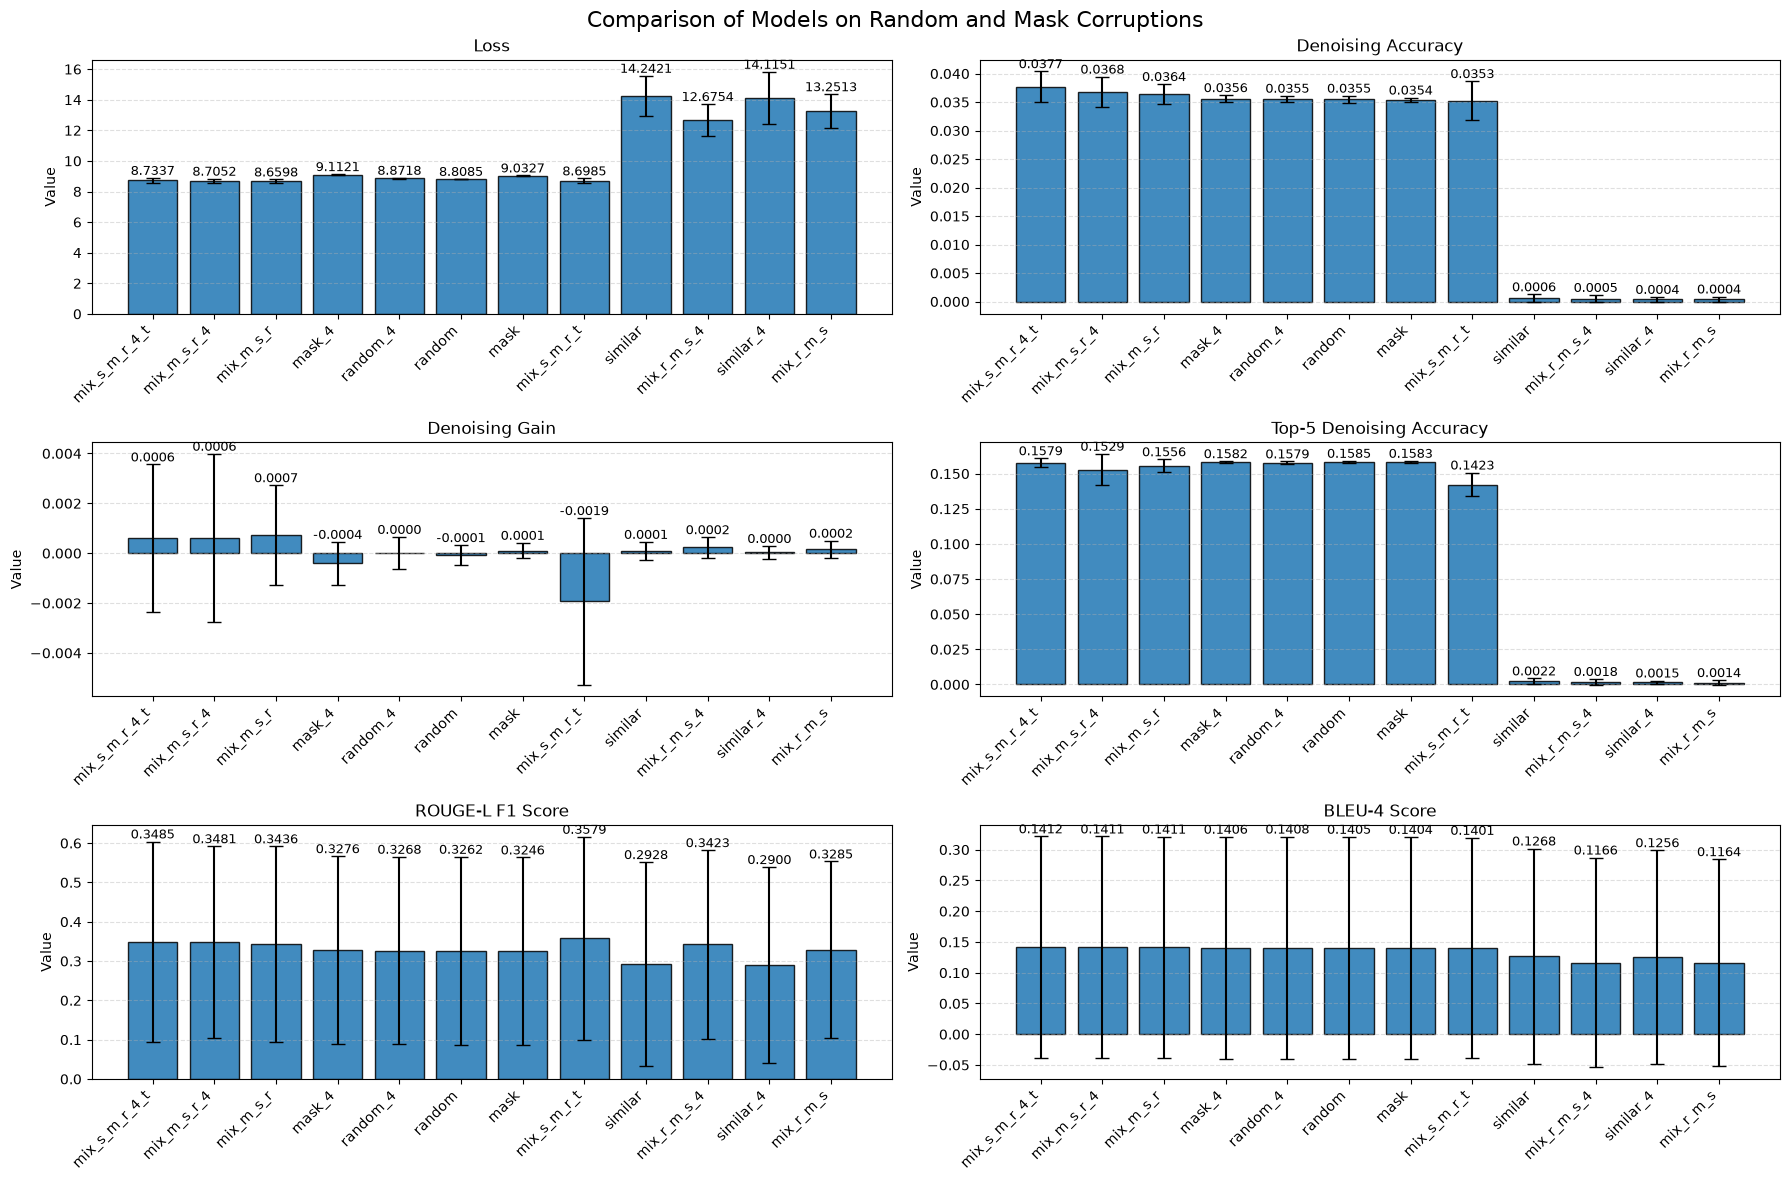

In [21]:
plot_metric_barplots(df_random_mask_grouped)

In [23]:
from IPython.display import display

TARGET_MODEL = 'mix_s_m_r_4_t'
METRIC_DIRECTIONS = {
    'loss': False,
    'accuracy_denoising': True,
    'denoising_gain': True,
    'top5_accuracy_denoising': True,
    'rouge_l_f1': True,
    'bleu4': True,
}

# Average evaluation settings within each seed, then average the seed means.
comparison_data = df_random_mask.dropna(subset=['model'])
per_seed_means = comparison_data.groupby(['model', 'seed'])[list(METRIC_DIRECTIONS)].mean()
model_means = per_seed_means.groupby('model').mean()
model_stds = per_seed_means.groupby('model').std()
if TARGET_MODEL not in model_means.index:
    raise ValueError(f'Target model {TARGET_MODEL!r} is missing from the evaluation data.')
other_means = model_means.drop(index=TARGET_MODEL)
if other_means.empty:
    raise ValueError('At least one other model is required for comparison.')

# Positive advantage always means the target is better; negative means worse.
comparison_rows = []
advantages_by_model = pd.DataFrame(index=other_means.index)
for metric, higher_is_better in METRIC_DIRECTIONS.items():
    direction = 1 if higher_is_better else -1
    target = model_means.loc[TARGET_MODEL, metric]
    competitors = other_means[metric].dropna()
    best_other = competitors.idxmax() if higher_is_better else competitors.idxmin()
    best_value = competitors.loc[best_other]
    average_other = competitors.mean()
    delta = direction * (target - best_value)
    # Relative percentages are undefined for gain comparisons around/below zero.
    use_relative = metric != 'denoising_gain'
    comparison_rows.append({
        'metric': metric,
        'target_mean': target,
        'target_std_seeds': model_stds.loc[TARGET_MODEL, metric],
        'target_rank': int(model_means[metric].rank(method='min', ascending=not higher_is_better).loc[TARGET_MODEL]),
        'best_other': best_other,
        'best_other_mean': best_value,
        'vs_best_%': 100 * delta / best_value if use_relative and best_value > 0 else np.nan,
        'vs_best_pp': 100 * delta if metric != 'loss' else np.nan,
        'vs_avg_others_%': 100 * direction * (target - average_other) / average_other if use_relative and average_other > 0 else np.nan,
    })
    if use_relative:
        advantages_by_model[f'{metric} (%)'] = 100 * direction * (target - other_means[metric]) / other_means[metric].where(other_means[metric] > 0)
    else:
        advantages_by_model[f'{metric} (pp)'] = 100 * (target - other_means[metric])

target_comparison = pd.DataFrame(comparison_rows).set_index('metric')
advantages_by_model.index.name = 'compared_with'
display(
    target_comparison.style
    .format({
        'target_mean': '{:.6f}', 'target_std_seeds': '{:.6f}',
        'target_rank': '{:.0f}', 'best_other_mean': '{:.6f}',
        'vs_best_%': '{:+.2f}', 'vs_best_pp': '{:+.4f}',
        'vs_avg_others_%': '{:+.2f}',
    }, na_rep='—')
    .set_caption(
        f'{TARGET_MODEL}: random + mask, all evaluated rates and iteration counts; '
        f'mean over {comparison_data["seed"].nunique()} seeds. '
        'STD is across seed means. Positive = target better; pp = percentage points. '
        'Best competitor is selected separately for each metric.'
    )
)
display(
    advantages_by_model.style.format('{:+.2f}', na_rep='—')
    .set_caption('Target advantage over each model: % relative to that model; denoising gain in pp.')
)

,target_mean,target_std_seeds,target_rank,best_other,best_other_mean,vs_best_%,vs_best_pp,vs_avg_others_%
metric,,,,,,,,
loss,8.733709,0.072814,4,mix_m_s_r,8.659780,-0.85,—,+17.30
accuracy_denoising,0.037723,0.001074,1,mix_m_s_r_4,0.036806,+2.49,+0.0917,+64.42
denoising_gain,0.000605,0.001877,3,mix_m_s_r,0.000730,—,-0.0125,—
top5_accuracy_denoising,0.157935,0.000746,5,random,0.158499,-0.36,-0.0563,+59.31
rouge_l_f1,0.348525,0.005538,2,mix_s_m_r_t,0.357948,-2.63,-0.9424,+6.25
bleu4,0.141183,0.000213,1,mix_m_s_r_4,0.141073,+0.08,+0.0110,+5.65


,loss (%),accuracy_denoising (%),denoising_gain (pp),top5_accuracy_denoising (%),rouge_l_f1 (%),bleu4 (%)
compared_with,,,,,,
mask,+3.31,+6.55,+0.05,-0.24,+7.39,+0.57
mask_4,+4.15,+5.95,+0.10,-0.16,+6.38,+0.42
mix_m_s_r,-0.85,+3.70,-0.01,+1.53,+1.43,+0.08
mix_m_s_r_4,-0.33,+2.49,-0.00,+3.31,+0.12,+0.08
mix_r_m_s,+34.09,+10035.00,+0.04,+11156.04,+6.08,+21.29
mix_r_m_s_4,+31.10,+7278.84,+0.04,+8566.37,+1.83,+21.07
mix_s_m_r_t,-0.40,+6.94,+0.25,+11.01,-2.63,+0.77
random,+0.85,+6.27,+0.07,-0.36,+6.86,+0.50
random_4,+1.56,+6.16,+0.06,-0.00,+6.66,+0.25


## Compare models and metrics by corruption rate

In [27]:
df_random_mask_cr = df_eval[df_eval['corruption_method'].isin(['random', 'mask'])]
df_random_mask_cr = df_random_mask_cr.groupby(
    ['model', 'corruption_rate']
).agg(
    {
        'loss': 'mean',
        'accuracy': 'mean',
        'accuracy_denoising': 'mean',
        'denoising_gain': 'mean',
        'top5_accuracy_denoising': 'mean',
        'rouge_l_f1': 'mean',
        'bleu4': 'mean'
    }
).reset_index()
df_random_mask_cr.sort_values(by='accuracy_denoising', ascending=False, inplace=True)

In [28]:
POSSIBLE_METRICS = [
    'loss',
    'accuracy',
    'accuracy_denoising',
    'denoising_gain',
    'top5_accuracy_denoising',
    'rouge_l_f1',
    'bleu4'
]

def metric_by_corruption_level(df, metric):
    if metric not in POSSIBLE_METRICS:
        raise ValueError(
            f"Invalid metric '{metric}'. Valid metrics are: {POSSIBLE_METRICS}"
        )
    for model in df['model'].unique():
        model_df = df[df['model'] == model].sort_values(by='corruption_rate')
        plt.plot(
            model_df['corruption_rate'],
            model_df[metric],
            marker='o',
            label=model
        )
    ylabel = " ".join(metric.split('_')) if '_' in metric else metric
    plt.xlabel('Corruption Level')
    plt.ylabel(ylabel.capitalize())
    plt.title(f'Comparison of Models by Corruption Level for {ylabel.capitalize()}')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

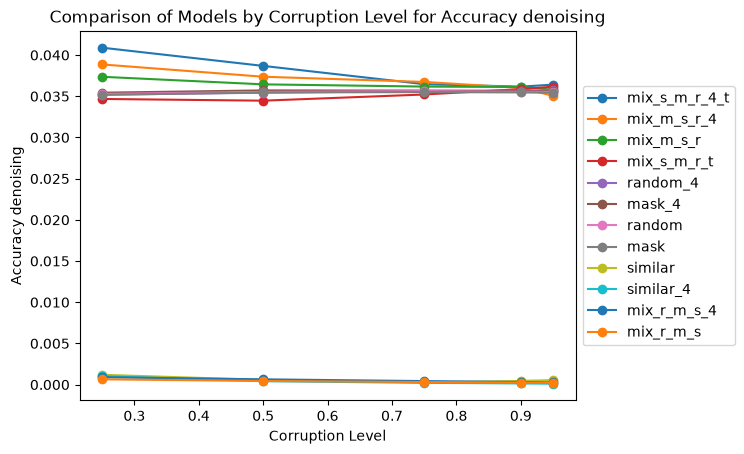

In [29]:
metric_by_corruption_level(df_random_mask_cr, 'accuracy_denoising')

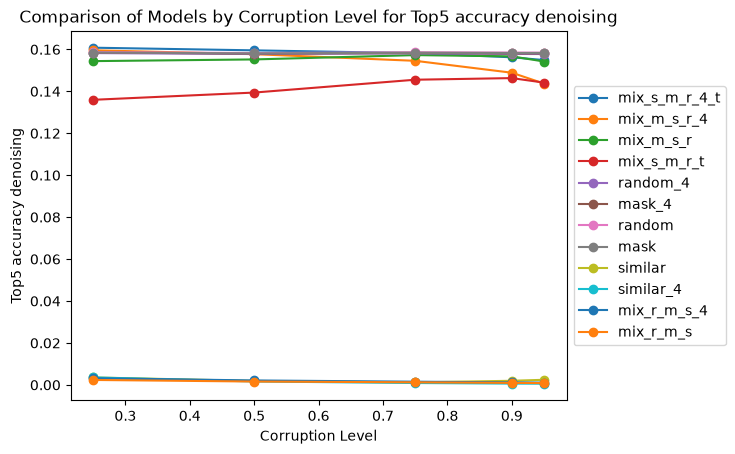

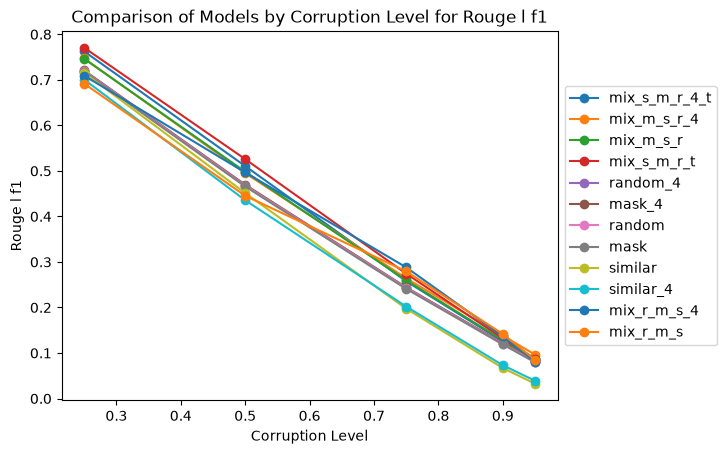

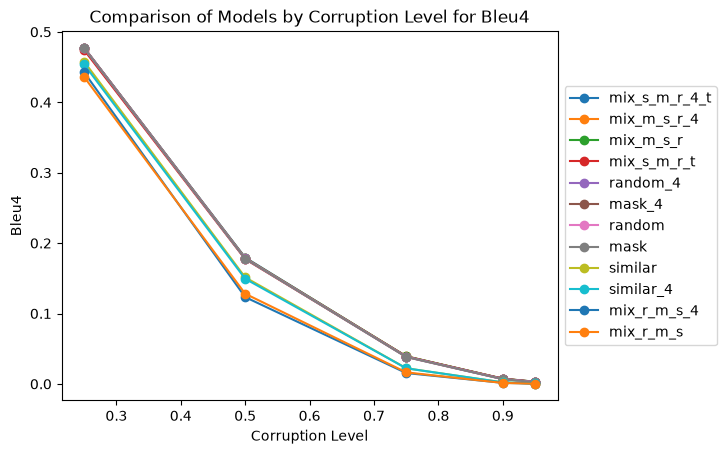

In [30]:
metric_by_corruption_level(df_random_mask_cr, 'top5_accuracy_denoising')
metric_by_corruption_level(df_random_mask_cr, 'rouge_l_f1')
metric_by_corruption_level(df_random_mask_cr, 'bleu4')

## Compare models and metrics by denoising lvl

In [36]:
df_random_mask_cr = df_eval[df_eval['corruption_method'].isin(['random', 'mask'])]
df_random_mask_cr_grouped_denoise = df_random_mask_cr.groupby(
    ['model', 'denoise_iterations']
).agg(
    {
        'loss': 'mean',
        'accuracy': 'mean',
        'accuracy_denoising': 'mean',
        'denoising_gain': 'mean',
        'top5_accuracy_denoising': 'mean',
        'rouge_l_f1': 'mean',
        'bleu4': 'mean'
    }
).reset_index()

def metric_by_denoise_level(df, metric):
    if metric not in POSSIBLE_METRICS:
        raise ValueError(
            f"Invalid metric '{metric}'. Valid metrics are: {POSSIBLE_METRICS}"
        )
    for model in df['model'].unique():
        model_df = df[df['model'] == model].sort_values(by='denoise_iterations')
        plt.plot(
            model_df['denoise_iterations'],
            model_df[metric],
            marker='o',
            label=model
        )
    ylabel = " ".join(metric.split('_')) if '_' in metric else metric
    plt.xlabel('Denoise Level')
    plt.ylabel(ylabel.capitalize())
    plt.title(f'Comparison of Models by Denoise Level for {ylabel.capitalize()}')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.show()

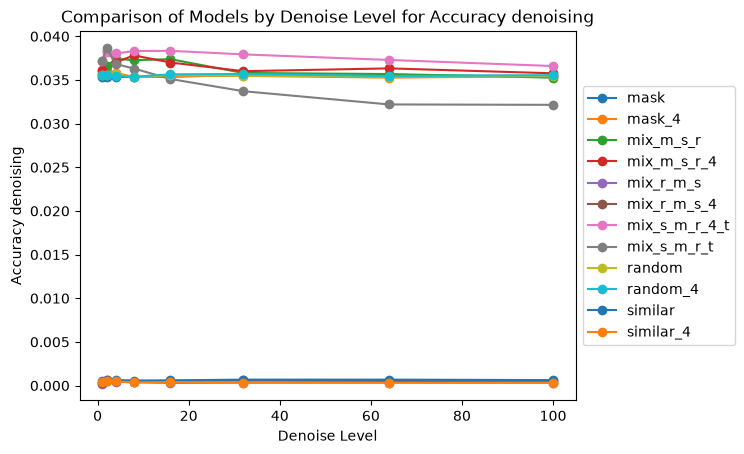

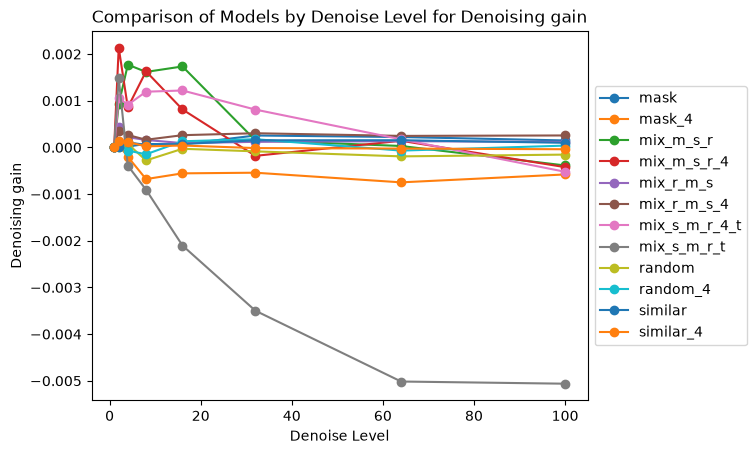

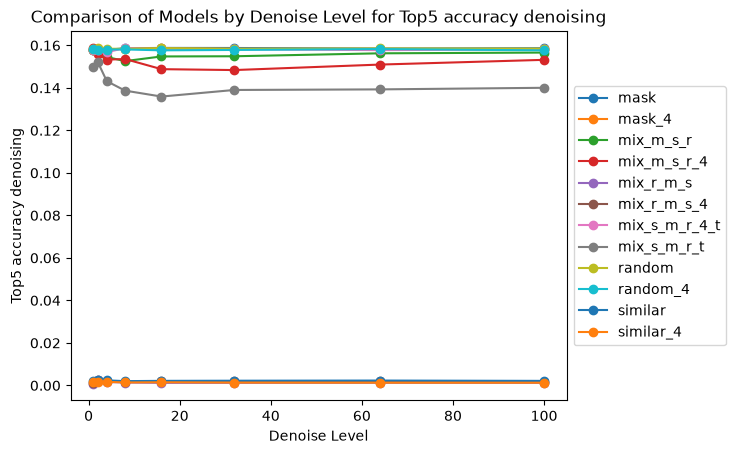

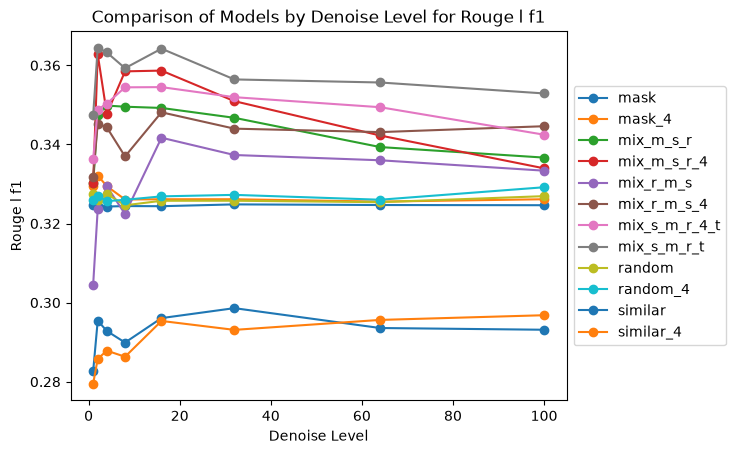

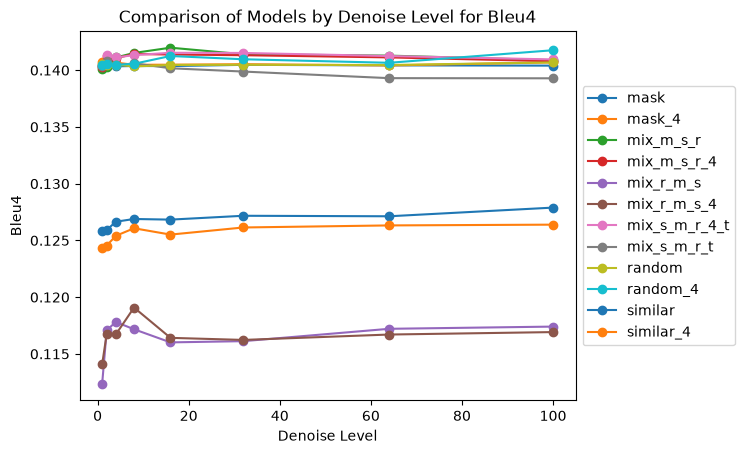

In [37]:
metric_by_denoise_level(df_random_mask_cr_grouped_denoise, 'accuracy_denoising')
metric_by_denoise_level(df_random_mask_cr_grouped_denoise, 'denoising_gain')
metric_by_denoise_level(df_random_mask_cr_grouped_denoise, 'top5_accuracy_denoising')
metric_by_denoise_level(df_random_mask_cr_grouped_denoise, 'rouge_l_f1')
metric_by_denoise_level(df_random_mask_cr_grouped_denoise, 'bleu4')

### heatmap

In [38]:
def plot_iteration_heatmap(
    df,
    metric='denoising_gain',
    methods=('random', 'mask'),
    figsize=(10, 6)
):
    data = df[df['corruption_method'].isin(methods)].copy()

    heatmap_data = (
        data
        .groupby(['model', 'denoise_iterations'])[metric]
        .mean()
        .unstack('denoise_iterations')
        .sort_index()
    )

    # Display denoising gain in percentage points
    if metric == 'denoising_gain':
        display_data = heatmap_data * 100
    else:
        display_data = heatmap_data

    fig, ax = plt.subplots(figsize=figsize)

    if metric == 'denoising_gain':
        max_abs = np.nanmax(np.abs(display_data.to_numpy()))

        norm = SymLogNorm(
            linthresh=0.02,
            linscale=1.5,
            vmin=-max_abs,
            vmax=max_abs,
            base=10
        )
        cmap = 'RdBu_r'
        colorbar_label = 'Denoising gain (percentage points)'
    else:
        norm = None
        cmap = 'viridis'
        colorbar_label = metric.replace('_', ' ').title()

    image = ax.imshow(
        display_data.to_numpy(),
        aspect='auto',
        cmap=cmap,
        norm=norm
    )

    ax.set_xticks(np.arange(len(display_data.columns)))
    ax.set_xticklabels(display_data.columns)

    ax.set_yticks(np.arange(len(display_data.index)))
    ax.set_yticklabels(display_data.index)

    ax.set_xlabel('Number of denoising iterations')
    ax.set_ylabel('Model')
    ax.set_title(
        f'{metric.replace("_", " ").title()} by Model and Iterations'
    )

    for i in range(display_data.shape[0]):
        for j in range(display_data.shape[1]):
            value = display_data.iloc[i, j]

            if not np.isnan(value):
                rgba = image.cmap(image.norm(value))
                luminance = (
                    0.299 * rgba[0]
                    + 0.587 * rgba[1]
                    + 0.114 * rgba[2]
                )

                ax.text(
                    j,
                    i,
                    f'{value:.3f}' if metric == 'denoising_gain'
                    else f'{value:.4f}',
                    ha='center',
                    va='center',
                    color='white' if luminance < 0.5 else 'black'
                )

    fig.colorbar(
        image,
        ax=ax,
        label=colorbar_label
    )

    plt.tight_layout()
    plt.show()

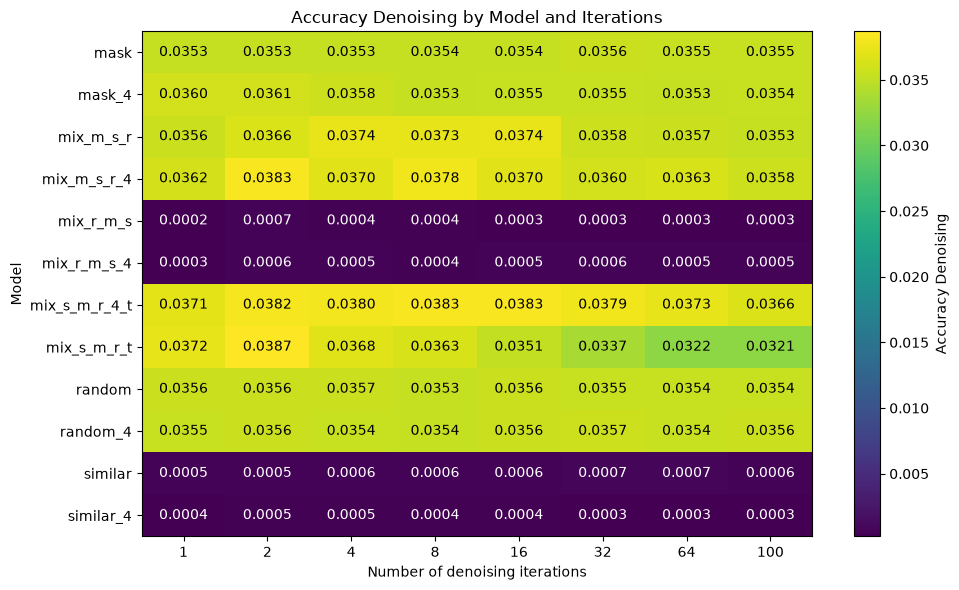

In [43]:
plot_iteration_heatmap(
    df_eval,
    metric='accuracy_denoising'
)

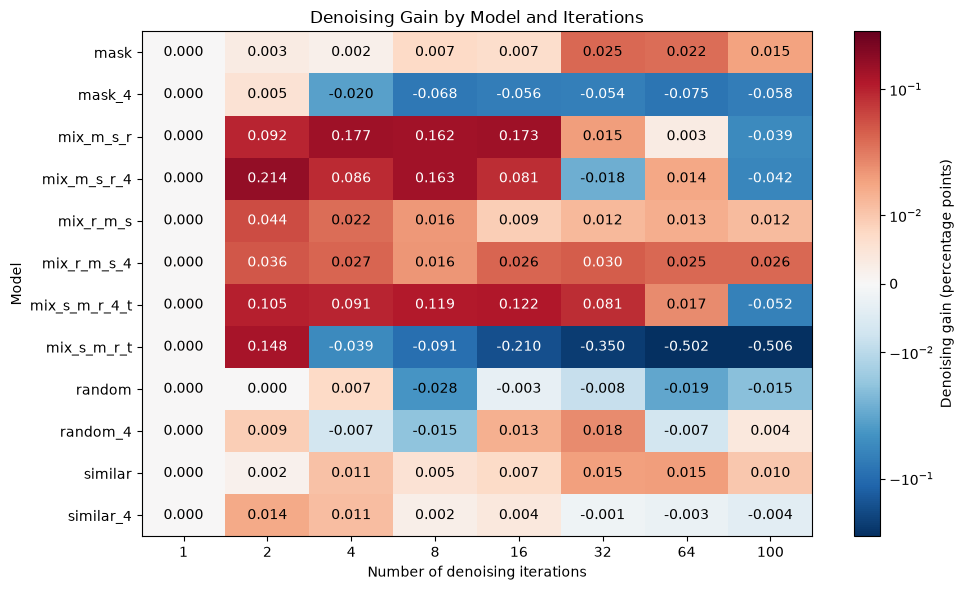

In [44]:
plot_iteration_heatmap(
    df_eval,
    metric='denoising_gain'
)

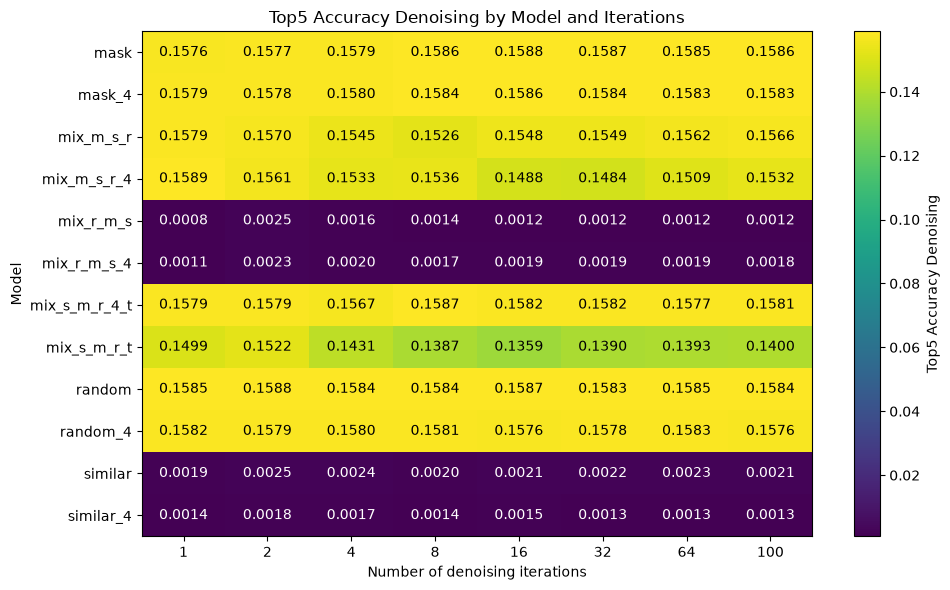

In [45]:
plot_iteration_heatmap(
    df_eval,
    metric='top5_accuracy_denoising'
)

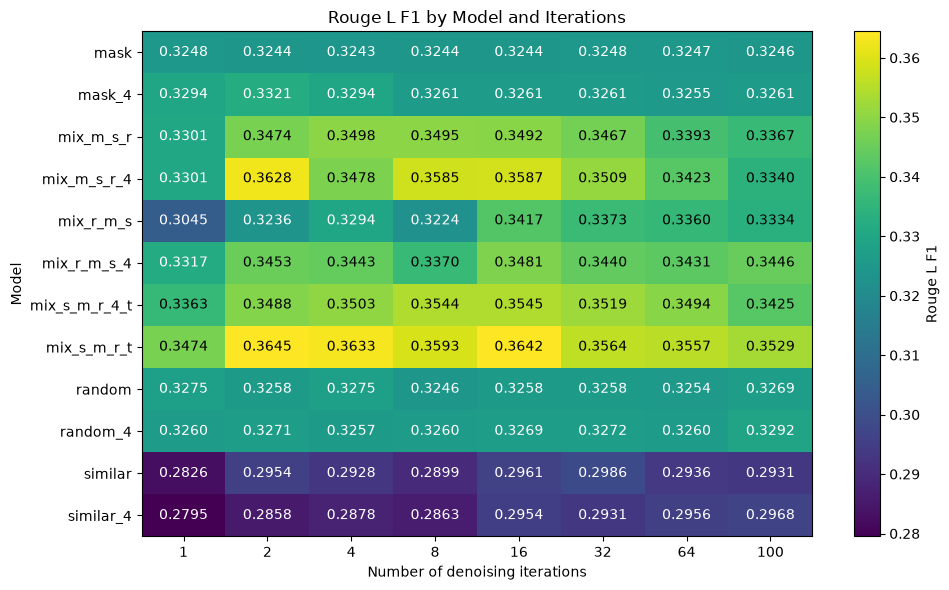

In [46]:
plot_iteration_heatmap(
    df_eval,
    metric='rouge_l_f1'
)

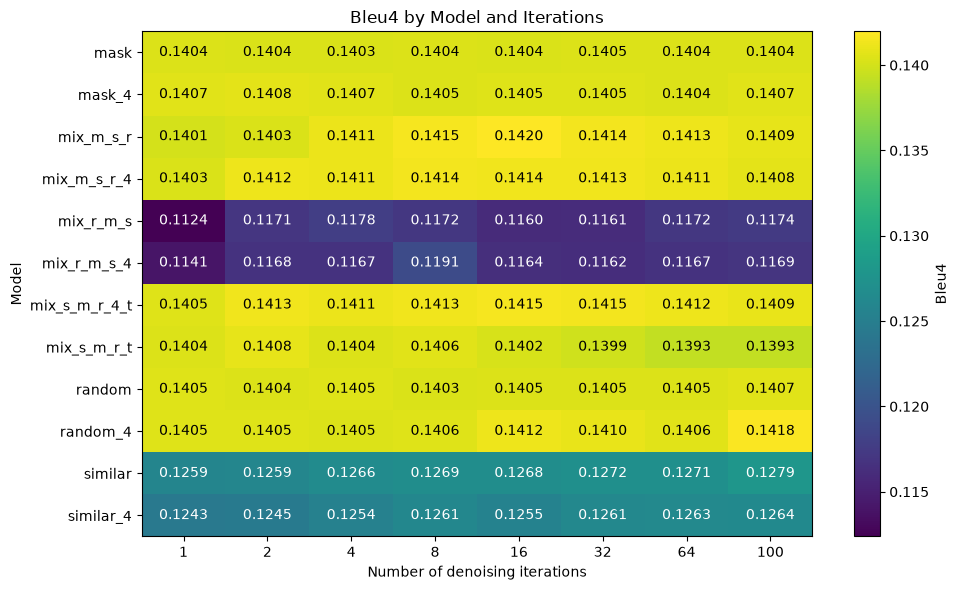

In [47]:
plot_iteration_heatmap(
    df_eval,
    metric='bleu4'
)

## AUC iterations

### AUC over denoising iterations

The Area Under the Curve (AUC) summarizes the overall denoising performance across different numbers of denoising iterations. It is calculated from the curve of `accuracy_denoising` versus `denoise_iterations`.

A higher AUC indicates better average performance across the evaluated iteration levels, rather than at only one specific number of iterations.

In [48]:
auc_data = df_eval[
    df_eval['corruption_method'].isin(['random', 'mask'])
].copy()

iteration_curves = (
    auc_data
    .groupby(['model', 'denoise_iterations'])['accuracy_denoising']
    .mean()
    .reset_index()
)

# Calculate AUC for every model
auc_results = []

for model, model_df in iteration_curves.groupby('model'):
    model_df = model_df.sort_values('denoise_iterations')

    x = model_df['denoise_iterations'].to_numpy()
    y = model_df['accuracy_denoising'].to_numpy()

    auc = np.trapezoid(y, x)

    # Normalized AUC = average accuracy over the iteration range
    normalized_auc = auc / (x[-1] - x[0])

    auc_results.append({
        'model': model,
        'auc_iterations': auc,
        'normalized_auc_iterations': normalized_auc
    })

auc_iterations_df = (
    pd.DataFrame(auc_results)
    .sort_values(
        'normalized_auc_iterations',
        ascending=False
    )
)

auc_iterations_df

,model,auc_iterations,normalized_auc_iterations
6,mix_s_m_r_4_t,3.716744,0.037543
3,mix_m_s_r_4,3.600478,0.036368
2,mix_m_s_r,3.564090,0.036001
9,random_4,3.519069,0.035546
0,mask,3.512701,0.035482
8,random,3.509373,0.035448
1,mask_4,3.505038,0.035404
7,mix_s_m_r_t,3.308730,0.033422
10,similar,0.064177,0.000648
5,mix_r_m_s_4,0.053395,0.000539


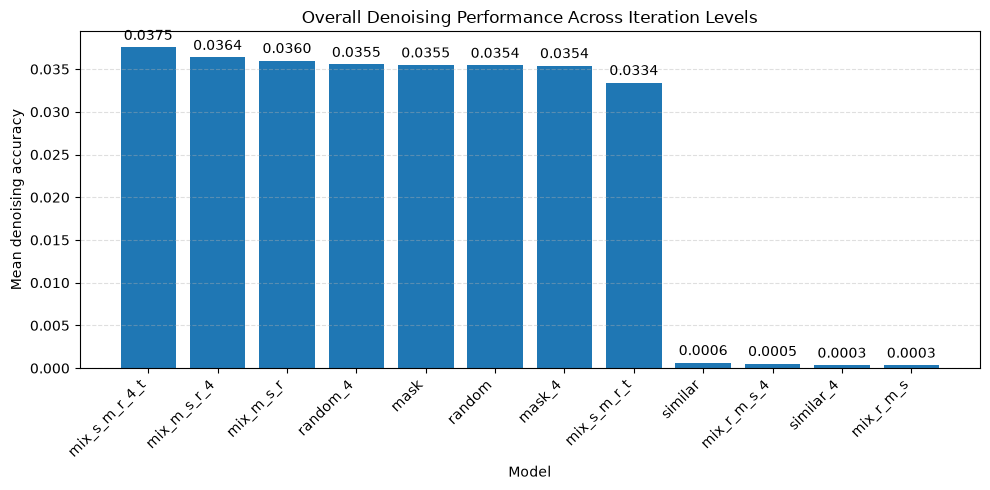

In [49]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    auc_iterations_df['model'],
    auc_iterations_df['normalized_auc_iterations']
)

plt.ylabel('Mean denoising accuracy')
plt.xlabel('Model')
plt.title('Overall Denoising Performance Across Iteration Levels')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.bar_label(bars, fmt='%.4f', padding=3)

plt.tight_layout()
plt.show()